# Предсказание возраста посетителей сайтов для таргетирования рекламы

> Учебный проект Яндекс Практикума (программа Data Science, модуль 3). Данные публичные, загружаются по ссылке `https://code.s3.yandex.net/datasets/`. Окружение: см. `requirements.txt` в корне репозитория.

**Проект реализует модель для предсказания возраста клиента по данных его информационного следа с целью таргетирования рекламы и соответствия показываемой рекламы восрастному цензу**

- данные собраны из нескольких источников в формате csv:

    - **ds_s13_users.csv** содержит информацию о возрастной категории пользователя
        
        * user_id — уникальный идентификатор пользователя.        
        * age_category — возрастная категория пользователя, этот показатель модель должна научиться предсказывать. Содержит следующие категории: 0: младше 18; 1: 18-25 лет; 2: 26-40 лет; 3: 41-55 лет; 4: 56+ лет.        
    
    -  **ds_s13_visits.csv** сбор и анализ информации об активности пользователей разных сайтов  
        * date — дата посещения сайта.
        * daytime — анонимизированное время посещения сайта. Категории: утро, день, вечер, ночь.
        * session_id — уникальный идентификатор сессии.     
        * user_id — уникальный идентификатор пользователя.        
        * website_category — анонимизированная категория сайта. (В лог включены несколько десятков категорий)
            
    - **ads_activity.csv** - активность взаимодействия пользователя с рекламными объявлениями (CTR)    
        * user_id — уникальный идентификатор пользователя.        
        * ads_activity — характеристика CTR, Категории: очень редко, редко, умеренно, часто, очень часто.       
    
    -  **surf_depth.csv** глубина перехода пользователя по сайтам во время одной сессии
        * user_id — уникальный идентификатор пользователя.       
        * surf_depth — глубина перехода пользователя по сайтам во время одной сессии. Категории: поверхностно, средне, глубоко.
        
    -  **primary_device.csv** содержит два признака информация о типе основного устройства пользователя для выхода в Интернет   
        * user_id — уникальный идентификатор пользователя.       
        * primary_device — информация о типе основного устройства пользователя для выхода в Интернет.       

    - **cloud_usage.csv** использование облачных технологий    
        * user_id — уникальный идентификатор пользователя;        
        * cloud_usage — True, пользователь обращается к облачным ресурсам типа Яндекс 360 прямо/через посещаемые сайты.


- Целевая переменная - age_category - возрастная категория пользователя

- Используемые архитектурные модели для задачи многоклассовой классификации:
    - базовая модель - DummyClassifier
    - LogisticRegression
    - модель опорных веторов SVM - SVC

- Для оценки модели используется ключевая метрика - **F1** (нижний порог для лучшей модели не менее 0.75)

    - Вспомогательные метрики: precision и recall
    
    - С использование макро-усреднения


**В рамках проекта выполняются следующие шаги:**

1. Подготовка среды и библиотек.
2. Исследовательский анализ данных (EDA).
3. Предобработка данных.
4. Обучение и оценка базовой модели.
5. Создание и отбор признаков.
6. Подбор гиперпараметров моделей.
7. Подготовка артефактов модели для внедрения.
8. Выводы о результатах работы.
 



## Подготовка среды и библиотек

Версии библиотек зафиксированы в `requirements.txt`. Установка: `pip install -r requirements.txt`.

In [282]:
import numpy as np
import pandas as pd

# для визуализации
import matplotlib.pyplot as plt
import seaborn as sns

# для корреляции 
import phik

# для устранения warnings
import warnings

# для сохранения модели
import joblib
import os

# для модели Логистической регрессии
from sklearn.linear_model import LogisticRegression

# для модели Опорных векторов
from sklearn.svm import SVC

# для Базовой модели
from sklearn.dummy import DummyClassifier

# для разделения на обучающую/валидационную/калибровочную/тестовую выборки
from sklearn.model_selection import train_test_split

# для кросс-валидации
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_score

# для метрик оценки качества модели
from sklearn.metrics import make_scorer, f1_score, precision_score, recall_score, classification_report

# Предобработка данных
# для заполнения пропусков
from sklearn.impute import SimpleImputer

# для масштабирования и кодирования 
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.preprocessing import TargetEncoder  # Доступно в sklearn >= 1.3.0

# для пайплайна и трансформера
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# для подбора гиперпараметров
from itertools import product
from sklearn.model_selection import GridSearchCV

# Отбор признаков
# для фильтрации признаков
from sklearn.feature_selection import VarianceThreshold

# для методов-обёртки
from sklearn.feature_selection import SequentialFeatureSelector as SFS
from sklearn.feature_selection import RFE

### Константы и воспроизводимость

In [284]:
TEST_SIZE = 0.2

In [285]:
RANDOM_SEED = 42

### Загрузка данных из файлов

In [286]:
# Один раз определяем функцию
def load_data(filename):
    try:
        return pd.read_csv(f'/datasets/{filename}')
    except (FileNotFoundError, OSError):
        return pd.read_csv(f'https://code.s3.yandex.net/datasets/{filename}')

In [287]:
# Словарь: имя DataFrame → имя файла
csv_files = {
    'df_users': 'ds_s13_users.csv',
    'df_visits': 'ds_s13_visits.csv',
    'df_ads_activity': 'ads_activity.csv',
    'df_surf_depth': 'surf_depth.csv',
    'df_primary_device': 'primary_device.csv',
    'df_cloud_usage': 'cloud_usage.csv'
}

# Словарь для хранения загруженных данных
dataframes = {}

# Загрузка всех файлов
for name, filename in csv_files.items():
#    print(f"Загрузка: {filename} → {name}")
    dataframes[name] = load_data(filename)  
#    print(f"Загружено: {dataframes[name].shape}")

# Выводим общую информацию  по каждому DataFrame:
for name, df in dataframes.items():
    print(f"\n{'='*50}")
    print(f"{name} : Размер: {df.shape}")
    print(f"{'-'*50}")
    print(df.head(3))
    print(f"{'-'*50}")
    print(f"{df.info()}")


df_users : Размер: (5913, 2)
--------------------------------------------------
                              user_id  age_category
0  f545-8c95aefe8d3e5548a689-a5b2fd39             4
1  cb48-5a0d6cde4d86ae10637e-c8ceb6ed             2
2  678b-614cd47d854b9d591db2-000b2e50             0
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5913 entries, 0 to 5912
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   user_id       5913 non-null   object
 1   age_category  5913 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 92.5+ KB
None

df_visits : Размер: (1065745, 5)
--------------------------------------------------
         date daytime                            session_id  \
0  2025-11-01   вечер  066e4e02-8c1f-45eb-a50f-178659abe698   
1  2025-11-01   вечер  0bce1749-3376-439c-9a22-f8ffbba00e9a   
2  2025-11-01   вечер  3445d8c4-221d-4d88-bb6a-a2939fe3c

## Исследовательский анализ данных

### Первичный анализ каждой таблицы (до объединения)

In [288]:


# Для каждой таблицы выполняем базовую диагностику:
for name, df in dataframes.items():
    print(f"\n{'='*60}")
    print(f"{name.upper()}: {df.shape}")
    print(f"{'='*60}")
    print(f"Пропуски:\n{df.isnull().sum()}")
    print(f"\nДубликаты: {df.duplicated().sum()}")
    print(f"\nУникальные user_id: {df['user_id'].nunique()}")
    print(f"Всего записей: {len(df)}")
    if 'user_id' in df.columns and len(df) > df['user_id'].nunique():
        print(f"Есть дубли user_id: {len(df) - df['user_id'].nunique()}")
    print(f"\nПервые 3 строки:\n{df.head(3)}")


DF_USERS: (5913, 2)
Пропуски:
user_id         0
age_category    0
dtype: int64

Дубликаты: 87

Уникальные user_id: 5826
Всего записей: 5913
Есть дубли user_id: 87

Первые 3 строки:
                              user_id  age_category
0  f545-8c95aefe8d3e5548a689-a5b2fd39             4
1  cb48-5a0d6cde4d86ae10637e-c8ceb6ed             2
2  678b-614cd47d854b9d591db2-000b2e50             0

DF_VISITS: (1065745, 5)
Пропуски:
date                0
daytime             0
session_id          0
user_id             0
website_category    0
dtype: int64

Дубликаты: 15750

Уникальные user_id: 5826
Всего записей: 1065745
Есть дубли user_id: 1059919

Первые 3 строки:
         date daytime                            session_id  \
0  2025-11-01   вечер  066e4e02-8c1f-45eb-a50f-178659abe698   
1  2025-11-01   вечер  0bce1749-3376-439c-9a22-f8ffbba00e9a   
2  2025-11-01   вечер  3445d8c4-221d-4d88-bb6a-a2939fe3c610   

                              user_id website_category  
0  0010-5cf8f6b38a7b6c70a021-

**Вывод: В рамках проекта доступно 6 таблиц с информацией о пользователях и их поведении в цифровой среде.**

| Таблица           | Записей   | Признаков | Пропуски | Дубликаты | Уникальные user_id |
| ----------------- | --------- | --------- | -------- | --------- | ------------------ |
| df_users          | 5 913     | 2         |  Нет    |  87     | 5 826              |
| df_visits         | 1 065 745 | 5         |  Нет    |  15 750 | 5 826              |
| df_ads_activity   | 5 826     | 2         |  Нет    |  233    | 5 593              |
| df_surf_depth     | 5 715     | 2         |  Нет    |  Нет     | 5 715              |
| df_primary_device | 5 669     | 2         |  Нет    |  Нет     | 5 669              |
| df_cloud_usage    | 5 680     | 2         |  Нет    |  Нет     | 5 680              |



**Ниже представлена детальная диагностика каждой таблицы.**

In [289]:
df_users=dataframes['df_users']
df_users.head()

,user_id,age_category
0,f545-8c95aefe8d3e5548a689-a5b2fd39,4
1,cb48-5a0d6cde4d86ae10637e-c8ceb6ed,2
2,678b-614cd47d854b9d591db2-000b2e50,0
3,4ac0-dad169100b4a29b20818-b26ae7c5,4
4,f19b-9ac21ca973b41ecfa8c3-6a58191d,0


**Таблица df_users (целевая переменная)**

| Параметр                | Значение                               |
| ----------------------- | -------------------------------------- |
| Размер                  | (5913, 2)                              |
| Признаки                | user_id (object), age_category (int64) |
| Пропуски                | Отсутствуют                            |
| Дубликаты               | 87 записей (дубли user_id)             |
| Уникальные пользователи | 5 826                                  |

**Проблема:** Наличие дубликатов user_id означает, что для 87 пользователей указано более одной возрастной категории. Требуется очистка перед объединением.

In [290]:
# ============================================
# ШАГ 1: Диагностика дубликатов
# ============================================
print("=" * 60)
print(" ДИАГНОСТИКА ДУБЛИКАТОВ В df_users")
print("=" * 60)

# Находим все дубликаты user_id
duplicates = df_users[df_users.duplicated(subset=['user_id'], keep=False)]

print(f"Всего записей до очистки: {len(df_users)}")
print(f"Уникальных user_id: {df_users['user_id'].nunique()}")
print(f"Дубликатов записей: {len(df_users) - df_users['user_id'].nunique()}")
print(f"\nПримеры дубликатов (первые 10):")
display(duplicates.head(10))

 ДИАГНОСТИКА ДУБЛИКАТОВ В df_users
Всего записей до очистки: 5913
Уникальных user_id: 5826
Дубликатов записей: 87

Примеры дубликатов (первые 10):


,user_id,age_category
22,ee47-db686342605ccf3ce244-088514e9,4
25,9bd6-b1663d3dd9859692bd1d-1fdc22cd,4
45,3bdd-4131152c20bbe4a56bdd-f6474b41,4
58,7bc7-528d9984666f8f2bee7b-971362e5,2
64,cda3-8ef64feb790e9e138307-173bd4ad,2
77,ea64-ae0d1ec99654768bd6f7-a40d9a81,2
111,3360-1ea0274d97bc1b80026b-36b1934d,4
138,857c-69d44ee399e9d461a86b-72054180,4
248,7047-0d5ce423a246c4bdf124-ad82a1cb,3
256,3718-86508c4768c06b3440a7-b81c6d36,0


In [291]:
duplicates

,user_id,age_category
22,ee47-db686342605ccf3ce244-088514e9,4
25,9bd6-b1663d3dd9859692bd1d-1fdc22cd,4
45,3bdd-4131152c20bbe4a56bdd-f6474b41,4
58,7bc7-528d9984666f8f2bee7b-971362e5,2
64,cda3-8ef64feb790e9e138307-173bd4ad,2
...,...,...
5709,48c4-88e07854a9125ee372de-bef57968,3
5784,ec4b-649d01a7343855b471db-857fe97f,4
5811,81b3-d3a8a19cfff77a75c571-a81355fc,2
5868,c1c6-7ce02c0dd580afef460d-45dbc7a2,0


In [292]:
# ============================================
# ШАГ 2: Проверка, разные ли age_category у дублей
# ============================================
print("=" * 60)
print(" АНАЛИЗ ДУБЛИКАТОВ: СОВПАДАЮТ ЛИ age_category?")
print("=" * 60)

# Группируем дубликаты и проверяем, сколько уникальных age_category на user_id
dup_analysis = duplicates.groupby('user_id')['age_category'].agg(['count', 'nunique']).reset_index()
dup_analysis.columns = ['user_id', 'total_records', 'unique_categories']

# Показываем, есть ли user_id с разными категориями
conflicting = dup_analysis[dup_analysis['unique_categories'] > 1]

print(f"Дубликатов user_id всего: {len(dup_analysis)}")
print(f"Из них с РАЗНЫМИ age_category: {len(conflicting)}")
print(f"Из них с ОДИНАКОВЫМИ age_category: {len(dup_analysis) - len(conflicting)}")

if len(conflicting) > 0:
    print("\n Примеры user_id с РАЗНЫМИ возрастными категориями:")
    display(conflicting.head(5))
    
    # Показываем конкретные значения
    sample_user = conflicting.iloc[0]['user_id']
    print(f"\nДетали для user_id = {sample_user}:")
    display(df_users[df_users['user_id'] == sample_user])

 АНАЛИЗ ДУБЛИКАТОВ: СОВПАДАЮТ ЛИ age_category?
Дубликатов user_id всего: 87
Из них с РАЗНЫМИ age_category: 0
Из них с ОДИНАКОВЫМИ age_category: 87


In [293]:
# ============================================
# ШАГ 3: Очистка от дубликатов
# ============================================
print("=" * 60)
print(" ОЧИСТКА df_users ОТ ДУБЛИКАТОВ")
print("=" * 60)

# Сохраняем размер до очистки
size_before = len(df_users)

# Вариант 1: Оставить первое вхождение (рекомендуется)
df_users_clean = df_users.drop_duplicates(subset=['user_id'], keep='first').reset_index(drop=True)

print(f"Записей до очистки: {size_before}")
print(f"Записей после очистки: {len(df_users_clean)}")
print(f"Удалено записей: {size_before - len(df_users_clean)}")
print(f"Уникальных user_id: {df_users_clean['user_id'].nunique()}")

# Проверка: дубликатов больше нет
assert df_users_clean['user_id'].nunique() == len(df_users_clean), " Остались дубликаты!"
print("\n Проверка пройдена: дубликаты удалены!")

 ОЧИСТКА df_users ОТ ДУБЛИКАТОВ
Записей до очистки: 5913
Записей после очистки: 5826
Удалено записей: 87
Уникальных user_id: 5826

 Проверка пройдена: дубликаты удалены!


In [294]:
# ============================================
# ШАГ 4: Проверка распределения age_category до и после
# ============================================
print("=" * 60)
print(" СРАВНЕНИЕ РАСПРЕДЕЛЕНИЯ age_category")
print("=" * 60)

import pandas as pd

comparison = pd.DataFrame({
    'До очистки': df_users['age_category'].value_counts().sort_index(),
    'После очистки': df_users_clean['age_category'].value_counts().sort_index(),
    'Изменение': df_users_clean['age_category'].value_counts().sort_index() - 
                 df_users['age_category'].value_counts().sort_index()
})

print(comparison)
print(f"\n Распределение в процентах (после очистки):")
print(df_users_clean['age_category'].value_counts(normalize=True).sort_index() * 100)

 СРАВНЕНИЕ РАСПРЕДЕЛЕНИЯ age_category
   До очистки  После очистки  Изменение
0         863            853        -10
1         520            514         -6
2        1467           1439        -28
3        1269           1254        -15
4        1794           1766        -28

 Распределение в процентах (после очистки):
0    14.641263
1     8.822520
2    24.699622
3    21.524202
4    30.312393
Name: age_category, dtype: float64


In [295]:
# ============================================
# ШАГ 5: Сохраняем очищенную таблицу для дальнейшей работы
# ============================================
# Переопределяем исходный DataFrame
df_users = df_users_clean.copy()

print("=" * 60)
print("df_users ГОТОВ К ДАЛЬНЕЙШЕЙ РАБОТЕ")
print("=" * 60)
print(f"Размер: {df_users.shape}")
print(f"Уникальных пользователей: {df_users['user_id'].nunique()}")
print(f"\nПервые 5 строк:")
display(df_users.head())

df_users ГОТОВ К ДАЛЬНЕЙШЕЙ РАБОТЕ
Размер: (5826, 2)
Уникальных пользователей: 5826

Первые 5 строк:


,user_id,age_category
0,f545-8c95aefe8d3e5548a689-a5b2fd39,4
1,cb48-5a0d6cde4d86ae10637e-c8ceb6ed,2
2,678b-614cd47d854b9d591db2-000b2e50,0
3,4ac0-dad169100b4a29b20818-b26ae7c5,4
4,f19b-9ac21ca973b41ecfa8c3-6a58191d,0


In [296]:
df_visits=dataframes['df_visits']
df_visits.head()

,date,daytime,session_id,user_id,website_category
0,2025-11-01,вечер,066e4e02-8c1f-45eb-a50f-178659abe698,0010-5cf8f6b38a7b6c70a021-009dbcda,Category 17
1,2025-11-01,вечер,0bce1749-3376-439c-9a22-f8ffbba00e9a,0010-5cf8f6b38a7b6c70a021-009dbcda,Category 19
2,2025-11-01,вечер,3445d8c4-221d-4d88-bb6a-a2939fe3c610,0010-5cf8f6b38a7b6c70a021-009dbcda,Category 18
3,2025-11-01,вечер,3bf97286-1d91-4aaa-af4a-ed58eceb8cd2,0010-5cf8f6b38a7b6c70a021-009dbcda,Category 20
4,2025-11-01,вечер,40e22712-3cad-410d-a9f0-13bd8f6911c0,0010-5cf8f6b38a7b6c70a021-009dbcda,Category 05


**Таблица df_visits (логи посещений)**

| Параметр                | Значение                                                          |
| ----------------------- | ----------------------------------------------------------------- |
| Размер                  | (1065745, 5)                                                      |
| Признаки                | date, daytime, session_id, user_id, website_category (все object) |
| Пропуски                | Отсутствуют                                                       |
| Дубликаты               | 15 750 записей                                                    |
| Уникальные пользователи | 5 826                                                             |
| Записей на пользователя | ~183 в среднем                                                    |

Т.к. в таблице df_visits обнаружены полные дубликаты строк (15 750) , а не просто повторение session_id или user_id. 
**Полные дубликаты перед агрегацией нужно удалять**

In [297]:
# Полные дубликаты строк (все 5 колонок одинаковы)
full_duplicates = df_visits.duplicated().sum()
print(f"Полных дубликатов строк: {full_duplicates:,}")

Полных дубликатов строк: 15,750


In [298]:
# Удаляем полные дубликаты строк
df_visits_clean = df_visits.drop_duplicates(keep='first').reset_index(drop=True)

In [299]:
df_visits = df_visits_clean.copy()

In [300]:
len(df_visits)

1049995

In [301]:
# Приведем значения к виду, необходимому для лальнейшего использования для наименования признаков
df_visits['website_category']=df_visits['website_category'].str.lower().replace(' ','_')
df_visits['website_category']

0          category 17
1          category 19
2          category 18
3          category 20
4          category 05
              ...     
1049990    category 06
1049991    category 04
1049992    category 19
1049993    category 05
1049994    category 10
Name: website_category, Length: 1049995, dtype: object

In [302]:
# ============================================
# ШАГ 1: Диагностика перед агрегацией
# ============================================
print("=" * 60)
print(" ДИАГНОСТИКА df_visits ПЕРЕД АГРЕГАЦИЕЙ")
print("=" * 60)

print(f"Размер до агрегации: {df_visits.shape}")
print(f"Уникальные пользователи: {df_visits['user_id'].nunique()}")
print(f"Среднее записей на пользователя: {len(df_visits) / df_visits['user_id'].nunique():.1f}")
print(f"\nРаспределение записей по пользователям:")
print(df_visits.groupby('user_id').size().describe())

 ДИАГНОСТИКА df_visits ПЕРЕД АГРЕГАЦИЕЙ
Размер до агрегации: (1049995, 5)
Уникальные пользователи: 5826
Среднее записей на пользователя: 180.2

Распределение записей по пользователям:
count    5826.000000
mean      180.225712
std        75.186802
min       100.000000
25%       124.000000
50%       167.000000
75%       213.000000
max       839.000000
dtype: float64


In [303]:
# ============================================
# ШАГ 2: Базовые агрегации по пользователю
# ============================================
print("=" * 60)
print(" АГРЕГАЦИЯ 1: БАЗОВЫЕ МЕТРИКИ АКТИВНОСТИ")
print("=" * 60)

visits_basic = df_visits.groupby('user_id').agg(
    total_visits=('date', 'count'),              # Общее количество посещений
    total_sessions=('session_id', 'nunique'),    # Количество уникальных сессий
    first_visit=('date', 'min'),                 # Дата первого посещения
    last_visit=('date', 'max'),                  # Дата последнего посещения
    unique_categories=('website_category', 'nunique')  # Сколько разных категорий сайтов
).reset_index()

# Добавляем признак: длительность активности (в днях)
visits_basic['activity_span_days'] = (
    pd.to_datetime(visits_basic['last_visit']) - pd.to_datetime(visits_basic['first_visit'])
).dt.days + 1

# Добавляем признак: средняя глубина сессии (посещений на сессию)
visits_basic['avg_visits_per_session'] = (
    visits_basic['total_visits'] / visits_basic['total_sessions'].replace(0, 1)
)

print(f" Базовые агрегации созданы: {visits_basic.shape}")
print(f"Признаки: {list(visits_basic.columns)}")
display(visits_basic.head())

 АГРЕГАЦИЯ 1: БАЗОВЫЕ МЕТРИКИ АКТИВНОСТИ
 Базовые агрегации созданы: (5826, 8)
Признаки: ['user_id', 'total_visits', 'total_sessions', 'first_visit', 'last_visit', 'unique_categories', 'activity_span_days', 'avg_visits_per_session']


,user_id,total_visits,total_sessions,first_visit,last_visit,unique_categories,activity_span_days,avg_visits_per_session
0,0010-5cf8f6b38a7b6c70a021-009dbcda,546,546,2025-11-01,2025-11-14,19,14,1.0
1,0013-4ae5f7d127b91a3fb0f8-ba59f141,185,185,2025-11-01,2025-11-14,19,14,1.0
2,0014-d3032d60979a8d2b3077-f09bdce8,117,117,2025-11-01,2025-11-14,19,14,1.0
3,001a-eee53e44f848608779b0-78704a67,287,287,2025-11-01,2025-11-14,19,14,1.0
4,002c-40a064b12e1217e12207-a56eaf3b,490,490,2025-11-01,2025-11-14,18,14,1.0


In [304]:
# ============================================
# ШАГ 3: Агрегация по категориям сайтов (pivot)
# ============================================
print("=" * 60)
print(" АГРЕГАЦИЯ 2: ПРЕДПОЧТЕНИЯ ПО КАТЕГОРИЯМ САЙТОВ")
print("=" * 60)

# Создаём pivot-таблицу: количество посещений каждой категории
category_counts = df_visits.pivot_table(
    index='user_id',
    columns='website_category',
    values='session_id',
    aggfunc='count',
    fill_value=0
).reset_index()

# Переименовываем колонки для понятности
category_counts.columns = ['user_id'] + [f'cat_{col}' for col in category_counts.columns[1:]]

# Нормализуем: доля посещений каждой категории (сумма = 1 для каждого пользователя)
category_cols = [col for col in category_counts.columns if col.startswith('cat_')]
category_proportions = category_counts.copy()
category_proportions[category_cols] = category_counts[category_cols].div(
    category_counts[category_cols].sum(axis=1), axis=0
).fillna(0)

print(f" Категорий сайтов: {len(category_cols)}")
print(f"Пример долей (первые 5 пользователей, первые 5 категорий):")
display(category_proportions[['user_id'] + category_cols[:5]].head())

 АГРЕГАЦИЯ 2: ПРЕДПОЧТЕНИЯ ПО КАТЕГОРИЯМ САЙТОВ
 Категорий сайтов: 20
Пример долей (первые 5 пользователей, первые 5 категорий):


,user_id,cat_category 01,cat_category 02,cat_category 03,cat_category 04,cat_category 05
0,0010-5cf8f6b38a7b6c70a021-009dbcda,0.029304,0.000000,0.062271,0.042125,0.032967
1,0013-4ae5f7d127b91a3fb0f8-ba59f141,0.081081,0.059459,0.027027,0.037838,0.081081
2,0014-d3032d60979a8d2b3077-f09bdce8,0.008547,0.017094,0.034188,0.059829,0.068376
3,001a-eee53e44f848608779b0-78704a67,0.066202,0.045296,0.034843,0.076655,0.034843
4,002c-40a064b12e1217e12207-a56eaf3b,0.000000,0.053061,0.071429,0.061224,0.040816


In [305]:
# ============================================
# ШАГ 4: Агрегация по времени суток (pivot)
# ============================================
print("=" * 60)
print(" АГРЕГАЦИЯ 3: АКТИВНОСТЬ ПО ВРЕМЕНИ СУТОК")
print("=" * 60)

# Создаём pivot-таблицу: количество посещений в разное время суток
daytime_counts = df_visits.pivot_table(
    index='user_id',
    columns='daytime',
    values='session_id',
    aggfunc='count',
    fill_value=0
).reset_index()

# Переименовываем колонки
daytime_counts.columns = ['user_id'] + [f'time_{col}' for col in daytime_counts.columns[1:]]

# Нормализуем: доля активности в каждое время суток
daytime_cols = [col for col in daytime_counts.columns if col.startswith('time_')]
daytime_proportions = daytime_counts.copy()
daytime_proportions[daytime_cols] = daytime_counts[daytime_cols].div(
    daytime_counts[daytime_cols].sum(axis=1), axis=0
).fillna(0)

# Добавляем признак: наиболее активное время суток
daytime_proportions['most_active_time'] = daytime_proportions[daytime_cols].idxmax(axis=1)
daytime_proportions['most_active_time'] = daytime_proportions['most_active_time'].str.replace('time_', '')

print(f" Временных слотов: {len(daytime_cols)}")
print(f"Распределение наиболее активного времени:")
print(daytime_proportions['most_active_time'].value_counts())
print(f"\nПример долей (первые 5 пользователей):")
display(daytime_proportions[['user_id'] + daytime_cols].head())

 АГРЕГАЦИЯ 3: АКТИВНОСТЬ ПО ВРЕМЕНИ СУТОК
 Временных слотов: 4
Распределение наиболее активного времени:
день     3087
вечер    2735
утро        4
Name: most_active_time, dtype: int64

Пример долей (первые 5 пользователей):


,user_id,time_вечер,time_день,time_ночь,time_утро
0,0010-5cf8f6b38a7b6c70a021-009dbcda,0.413919,0.326007,0.095238,0.164835
1,0013-4ae5f7d127b91a3fb0f8-ba59f141,0.275676,0.372973,0.086486,0.264865
2,0014-d3032d60979a8d2b3077-f09bdce8,0.307692,0.384615,0.094017,0.213675
3,001a-eee53e44f848608779b0-78704a67,0.414634,0.334495,0.108014,0.142857
4,002c-40a064b12e1217e12207-a56eaf3b,0.295918,0.383673,0.069388,0.251020


In [306]:
# ============================================
# ШАГ 5: Дополнительные признаки (по желанию)
# ============================================
print("=" * 60)
print(" АГРЕГАЦИЯ 4: ДОПОЛНИТЕЛЬНЫЕ ПРИЗНАКИ")
print("=" * 60)

# 5.1: Активность по дням недели (если есть дата)
df_visits['date_dt'] = pd.to_datetime(df_visits['date'], errors='coerce')
df_visits['day_of_week'] = df_visits['date_dt'].dt.dayofweek  # 0=Пн, 6=Вс

# Доля активности в выходные (сб=5, вс=6)
weekend_activity = df_visits.groupby('user_id').apply(
    lambda x: (x['day_of_week'].isin([5, 6])).sum() / len(x) if len(x) > 0 else 0
).reset_index(name='weekend_activity_ratio')

# 5.2: Средняя активность в день
daily_activity = df_visits.groupby(['user_id', 'date']).size().reset_index(name='daily_visits')
daily_activity_agg = daily_activity.groupby('user_id')['daily_visits'].agg([
    ('avg_daily_visits', 'mean'),
    ('max_daily_visits', 'max'),
    ('std_daily_visits', 'std')
]).reset_index()
daily_activity_agg['std_daily_visits'] = daily_activity_agg['std_daily_visits'].fillna(0)

print(f" Дополнительные признаки созданы")
print(f"weekend_activity_ratio: {weekend_activity.shape}")
print(f"daily_activity_agg: {daily_activity_agg.shape}")

 АГРЕГАЦИЯ 4: ДОПОЛНИТЕЛЬНЫЕ ПРИЗНАКИ
 Дополнительные признаки созданы
weekend_activity_ratio: (5826, 2)
daily_activity_agg: (5826, 4)


In [307]:
# ============================================
# ШАГ 6: Объединение всех агрегаций в одну таблицу
# ============================================
print("=" * 60)
print(" ОБЪЕДИНЕНИЕ ВСЕХ АГРЕГАЦИЙ")
print("=" * 60)

# Начинаем с базовых агрегаций
visits_aggregated = visits_basic.copy()

# Добавляем доли категорий
visits_aggregated = visits_aggregated.merge(
    category_proportions, 
    on='user_id', 
    how='left'
)

# Добавляем доли времени суток
visits_aggregated = visits_aggregated.merge(
    daytime_proportions, 
    on='user_id', 
    how='left'
)

# Добавляем дополнительные признаки
visits_aggregated = visits_aggregated.merge(
    weekend_activity, 
    on='user_id', 
    how='left'
)

visits_aggregated = visits_aggregated.merge(
    daily_activity_agg, 
    on='user_id', 
    how='left'
)

# Удаляем промежуточные колонки (даты)
visits_aggregated = visits_aggregated.drop(columns=['first_visit', 'last_visit'], errors='ignore')

print(f" Финальный размер агрегированных данных: {visits_aggregated.shape}")
print(f"Уникальных пользователей: {visits_aggregated['user_id'].nunique()}")
print(f"Всего признаков: {len(visits_aggregated.columns) - 1}")  # минус user_id

 ОБЪЕДИНЕНИЕ ВСЕХ АГРЕГАЦИЙ
 Финальный размер агрегированных данных: (5826, 35)
Уникальных пользователей: 5826
Всего признаков: 34


In [308]:
visits_aggregated.head()

,user_id,total_visits,total_sessions,unique_categories,activity_span_days,avg_visits_per_session,cat_category 01,cat_category 02,cat_category 03,cat_category 04,...,cat_category 20,time_вечер,time_день,time_ночь,time_утро,most_active_time,weekend_activity_ratio,avg_daily_visits,max_daily_visits,std_daily_visits
0,0010-5cf8f6b38a7b6c70a021-009dbcda,546,546,19,14,1.0,0.029304,0.000000,0.062271,0.042125,...,0.091575,0.413919,0.326007,0.095238,0.164835,вечер,0.285714,39.000000,53,7.232406
1,0013-4ae5f7d127b91a3fb0f8-ba59f141,185,185,19,14,1.0,0.081081,0.059459,0.027027,0.037838,...,0.021622,0.275676,0.372973,0.086486,0.264865,день,0.237838,13.214286,18,4.022601
2,0014-d3032d60979a8d2b3077-f09bdce8,117,117,19,14,1.0,0.008547,0.017094,0.034188,0.059829,...,0.034188,0.307692,0.384615,0.094017,0.213675,день,0.282051,8.357143,13,3.152707
3,001a-eee53e44f848608779b0-78704a67,287,287,19,14,1.0,0.066202,0.045296,0.034843,0.076655,...,0.059233,0.414634,0.334495,0.108014,0.142857,вечер,0.296167,20.500000,24,3.156190
4,002c-40a064b12e1217e12207-a56eaf3b,490,490,18,14,1.0,0.000000,0.053061,0.071429,0.061224,...,0.055102,0.295918,0.383673,0.069388,0.251020,день,0.261224,35.000000,45,6.445034


In [309]:
# ============================================
# ШАГ 7: Проверка качества агрегации
# ============================================
print("=" * 60)
print(" ПРОВЕРКА КАЧЕСТВА АГРЕГАЦИИ")
print("=" * 60)

# 1. Проверка: один user_id = одна строка
assert visits_aggregated['user_id'].nunique() == len(visits_aggregated), " Есть дубли user_id!"
print(" Проверка 1: Дубликаты user_id отсутствуют")

# 2. Проверка: суммы долей = 1 (с небольшой погрешностью)
category_sum = visits_aggregated[category_cols].sum(axis=1)
daytime_sum = visits_aggregated[daytime_cols].sum(axis=1)

assert (abs(category_sum - 1) < 0.01).all(), " Сумма долей категорий ≠ 1!"
assert (abs(daytime_sum - 1) < 0.01).all(), " Сумма долей времени ≠ 1!"
print(" Проверка 2: Суммы долей категорий и времени = 1")

# 3. Проверка: нет пропусков в ключевых признаках
key_cols = ['total_visits', 'total_sessions', 'unique_categories']
missing = visits_aggregated[key_cols].isnull().sum().sum()
assert missing == 0, f" Есть пропуски: {missing}"
print(" Проверка 3: Пропуски в ключевых признаках отсутствуют")

# 4. Статистика по признакам
print(f"\n Статистика основных признаков:")
display(visits_aggregated[['total_visits', 'total_sessions', 'unique_categories', 'activity_span_days']].describe())

 ПРОВЕРКА КАЧЕСТВА АГРЕГАЦИИ
 Проверка 1: Дубликаты user_id отсутствуют
 Проверка 2: Суммы долей категорий и времени = 1
 Проверка 3: Пропуски в ключевых признаках отсутствуют

 Статистика основных признаков:


,total_visits,total_sessions,unique_categories,activity_span_days
count,5826.000000,5826.000000,5826.000000,5826.000000
mean,180.225712,180.225712,18.472880,13.999657
std,75.186802,75.186802,0.767831,0.018526
min,100.000000,100.000000,14.000000,13.000000
25%,124.000000,124.000000,18.000000,14.000000
50%,167.000000,167.000000,19.000000,14.000000
75%,213.000000,213.000000,19.000000,14.000000
max,839.000000,839.000000,19.000000,14.000000


In [310]:
# ============================================
# ШАГ 8: Сохранение для дальнейшей работы
# ============================================
# Переименуем для удобства
df_visits_agg = visits_aggregated.copy()

print("=" * 60)
print(" df_visits_agg ГОТОВ К ОБЪЕДИНЕНИЮ С ДРУГИМИ ТАБЛИЦАМИ")
print("=" * 60)
print(f"Размер: {df_visits_agg.shape}")
print(f"\nПервые 3 строки:")
display(df_visits_agg.head(3))

 df_visits_agg ГОТОВ К ОБЪЕДИНЕНИЮ С ДРУГИМИ ТАБЛИЦАМИ
Размер: (5826, 35)

Первые 3 строки:


,user_id,total_visits,total_sessions,unique_categories,activity_span_days,avg_visits_per_session,cat_category 01,cat_category 02,cat_category 03,cat_category 04,...,cat_category 20,time_вечер,time_день,time_ночь,time_утро,most_active_time,weekend_activity_ratio,avg_daily_visits,max_daily_visits,std_daily_visits
0,0010-5cf8f6b38a7b6c70a021-009dbcda,546,546,19,14,1.0,0.029304,0.000000,0.062271,0.042125,...,0.091575,0.413919,0.326007,0.095238,0.164835,вечер,0.285714,39.000000,53,7.232406
1,0013-4ae5f7d127b91a3fb0f8-ba59f141,185,185,19,14,1.0,0.081081,0.059459,0.027027,0.037838,...,0.021622,0.275676,0.372973,0.086486,0.264865,день,0.237838,13.214286,18,4.022601
2,0014-d3032d60979a8d2b3077-f09bdce8,117,117,19,14,1.0,0.008547,0.017094,0.034188,0.059829,...,0.034188,0.307692,0.384615,0.094017,0.213675,день,0.282051,8.357143,13,3.152707


**Итоговая структура агрегированных данных df_visits_agg**

| Группа признаков | Количество | Примеры                                         |
| ---------------- | ---------- | ----------------------------------------------- |
| Базовые метрики  | 7          | total_visits, total_sessions, unique_categories |
| Временные        | 3          | activity_span_days, avg_visits_per_session      |
| Категории сайтов | ~20-50     | cat_Category 1, cat_Category 2, ...             |
| Время суток      | 4          | time_утро, time_день, time_вечер, time_ночь     |
| Дополнительные   | 5          | weekend_activity_ratio, avg_daily_visits, ...   |
| ИТОГО            | ~40-60     | Одна строка на пользователя                     |

**Таблица df_ads_activity (активность с рекламой)**

| Параметр                | Значение                                |
| ----------------------- | --------------------------------------- |
| Размер                  | (5826, 2)                               |
| Признаки                | user_id (object), ads_activity (object) |
| Пропуски                | Отсутствуют                             |
| Дубликаты               | 233 записи (дубли user_id)              |
| Уникальные пользователи | 5 593                                   |

In [311]:
df_ads_activity=dataframes['df_ads_activity']
df_ads_activity.head()

,user_id,ads_activity
0,e318-d8e69c86b543a5fb927c-c36fb6e6,очень часто
1,35cd-a972339dec534f49332c-a8b6d383,редко
2,f7e6-3b29cf9cb7ed4bb00d8f-81534360,очень редко
3,5186-e25a37549e50f45b2b43-178eaabe,умеренно
4,febd-077f277466253ee04ef6-42656680,умеренно


In [312]:
# ============================================
# ШАГ 1: Диагностика дубликатов
# ============================================
print("=" * 60)
print(" ДИАГНОСТИКА ДУБЛИКАТОВ В df_ads_activity")
print("=" * 60)

# Находим все дубликаты user_id
duplicates = df_ads_activity[df_ads_activity.duplicated(subset=['user_id'], keep=False)]

print(f"Всего записей до очистки: {len(df_ads_activity)}")
print(f"Уникальных user_id: {df_ads_activity['user_id'].nunique()}")
print(f"Дубликатов записей: {len(df_ads_activity) - df_ads_activity['user_id'].nunique()}")
print(f"\nПримеры дубликатов (первые 10):")
display(duplicates.head(10))

 ДИАГНОСТИКА ДУБЛИКАТОВ В df_ads_activity
Всего записей до очистки: 5826
Уникальных user_id: 5593
Дубликатов записей: 233

Примеры дубликатов (первые 10):


,user_id,ads_activity
1,35cd-a972339dec534f49332c-a8b6d383,редко
26,dbda-8283701eb09fa48ff0c3-7d39e267,редко
67,3407-fc49fbbeb7d0841c2f83-ccb6448b,редко
68,e47a-50eeeb0b509ef112b358-ac1847fc,редко
106,e817-16abae45e7bcffc90942-25003dd6,редко
112,55ba-67d53ae1f884d896cfee-576d3849,часто
122,8917-4ddf0ca628c734a1810d-79fcf9ef,умеренно
123,40fb-1f25bca5350140ef4e62-7bec289d,умеренно
130,f5b4-23d7c2ede9835f33508e-237804ad,умеренно
167,94d9-66b9520201e3367b896e-88147398,редко


In [313]:
# ============================================
# ШАГ 2: Проверка, разные ли ads_activity у дублей
# ============================================
print("=" * 60)
print(" АНАЛИЗ ДУБЛИКАТОВ: СОВПАДАЮТ ЛИ ads_activity?")
print("=" * 60)

# Группируем дубликаты и проверяем, сколько уникальных ads_activity на user_id
dup_analysis = duplicates.groupby('user_id')['ads_activity'].agg(['count', 'nunique']).reset_index()
dup_analysis.columns = ['user_id', 'total_records', 'unique_activities']

# Показываем, есть ли user_id с разными значениями активности
conflicting = dup_analysis[dup_analysis['unique_activities'] > 1]

print(f"Дубликатов user_id всего: {len(dup_analysis)}")
print(f"Из них с РАЗНЫМИ ads_activity: {len(conflicting)}")
print(f"Из них с ОДИНАКОВЫМИ ads_activity: {len(dup_analysis) - len(conflicting)}")

if len(conflicting) > 0:
    print("\n Примеры user_id с РАЗНЫМИ значениями активности:")
    display(conflicting.head(5))
    
    # Показываем конкретные значения
    sample_user = conflicting.iloc[0]['user_id']
    print(f"\nДетали для user_id = {sample_user}:")
    display(df_ads_activity[df_ads_activity['user_id'] == sample_user])
else:
    print("\n Все дубликаты имеют одинаковые значения ads_activity")

 АНАЛИЗ ДУБЛИКАТОВ: СОВПАДАЮТ ЛИ ads_activity?
Дубликатов user_id всего: 233
Из них с РАЗНЫМИ ads_activity: 0
Из них с ОДИНАКОВЫМИ ads_activity: 233

 Все дубликаты имеют одинаковые значения ads_activity


In [314]:
# ============================================
# ШАГ 3: Анализ распределения ads_activity
# ============================================
print("=" * 60)
print(" РАСПРЕДЕЛЕНИЕ ads_activity ДО ОЧИСТКИ")
print("=" * 60)

print("Абсолютные значения:")
print(df_ads_activity['ads_activity'].value_counts())
print("\nПроценты:")
print(df_ads_activity['ads_activity'].value_counts(normalize=True) * 100)

 РАСПРЕДЕЛЕНИЕ ads_activity ДО ОЧИСТКИ
Абсолютные значения:
умеренно       1897
редко          1698
часто          1112
очень редко     881
очень часто     238
Name: ads_activity, dtype: int64

Проценты:
умеренно       32.560934
редко          29.145211
часто          19.086852
очень редко    15.121867
очень часто     4.085136
Name: ads_activity, dtype: float64


In [315]:
# ============================================
# ШАГ 4: Очистка от дубликатов
# ============================================
print("=" * 60)
print(" ОЧИСТКА df_ads_activity ОТ ДУБЛИКАТОВ")
print("=" * 60)

# Сохраняем размер до очистки
size_before = len(df_ads_activity)
unique_before = df_ads_activity['user_id'].nunique()

# Вариант 1: Оставить первое вхождение (рекомендуется)
df_ads_activity_clean = df_ads_activity.drop_duplicates(subset=['user_id'], keep='first').reset_index(drop=True)

# Вариант 2 (альтернатива): Оставить последнее вхождение
# df_ads_activity_clean = df_ads_activity.drop_duplicates(subset=['user_id'], keep='last').reset_index(drop=True)

# Вариант 3 (альтернатива): Агрегировать по моде (наиболее частая активность)
# df_ads_activity_clean = df_ads_activity.groupby('user_id')['ads_activity'].agg(
#     lambda x: x.mode()[0] if not x.mode().empty else x.iloc[0]
# ).reset_index()

print(f"Записей до очистки: {size_before}")
print(f"Записей после очистки: {len(df_ads_activity_clean)}")
print(f"Удалено записей: {size_before - len(df_ads_activity_clean)}")
print(f"Уникальных user_id до: {unique_before}")
print(f"Уникальных user_id после: {df_ads_activity_clean['user_id'].nunique()}")

# Проверка: дубликатов больше нет
assert df_ads_activity_clean['user_id'].nunique() == len(df_ads_activity_clean), "❌ Остались дубликаты!"
print("\n Проверка пройдена: дубликаты удалены!")

 ОЧИСТКА df_ads_activity ОТ ДУБЛИКАТОВ
Записей до очистки: 5826
Записей после очистки: 5593
Удалено записей: 233
Уникальных user_id до: 5593
Уникальных user_id после: 5593

 Проверка пройдена: дубликаты удалены!


In [316]:
# ============================================
# ШАГ 5: Проверка распределения после очистки
# ============================================
print("=" * 60)
print(" СРАВНЕНИЕ РАСПРЕДЕЛЕНИЯ ads_activity")
print("=" * 60)

import pandas as pd

comparison = pd.DataFrame({
    'До очистки': df_ads_activity['ads_activity'].value_counts().sort_index(),
    'После очистки': df_ads_activity_clean['ads_activity'].value_counts().sort_index(),
    'Изменение': df_ads_activity_clean['ads_activity'].value_counts().sort_index() - 
                 df_ads_activity['ads_activity'].value_counts().sort_index()
})

print(comparison)
print(f"\n Распределение в процентах (после очистки):")
print(df_ads_activity_clean['ads_activity'].value_counts(normalize=True).sort_index() * 100)

 СРАВНЕНИЕ РАСПРЕДЕЛЕНИЯ ads_activity
             До очистки  После очистки  Изменение
очень редко         881            841        -40
очень часто         238            225        -13
редко              1698           1634        -64
умеренно           1897           1824        -73
часто              1112           1069        -43

 Распределение в процентах (после очистки):
очень редко    15.036653
очень часто     4.022886
редко          29.215090
умеренно       32.612194
часто          19.113177
Name: ads_activity, dtype: float64


In [317]:
# ============================================
# ШАГ 6: Проверка покрытия пользователей
# ============================================
print("=" * 60)
print(" ПРОВЕРКА ПОКРЫТИЯ ПОЛЬЗОВАТЕЛЕЙ")
print("=" * 60)

# Сравниваем с df_users (целевая таблица)
users_in_ads = set(df_ads_activity_clean['user_id'])
users_in_users = set(df_users['user_id'])  # Используем уже очищенный df_users

print(f"Пользователей в df_users: {len(users_in_users)}")
print(f"Пользователей в df_ads_activity: {len(users_in_ads)}")
print(f"Пересечение (есть в обеих таблицах): {len(users_in_users & users_in_ads)}")
print(f"Только в df_users (не будет признака): {len(users_in_users - users_in_ads)}")
print(f"Только в df_ads_activity (не будет target): {len(users_in_ads - users_in_users)}")

# Процент покрытия
coverage = len(users_in_users & users_in_ads) / len(users_in_users) * 100
print(f"\n Покрытие пользователей из df_users: {coverage:.1f}%")

 ПРОВЕРКА ПОКРЫТИЯ ПОЛЬЗОВАТЕЛЕЙ
Пользователей в df_users: 5826
Пользователей в df_ads_activity: 5593
Пересечение (есть в обеих таблицах): 5593
Только в df_users (не будет признака): 233
Только в df_ads_activity (не будет target): 0

 Покрытие пользователей из df_users: 96.0%


In [318]:
# ============================================
# ШАГ 7: Сохранение очищенной таблицы
# ============================================
# Переопределяем исходный DataFrame
df_ads_activity = df_ads_activity_clean.copy()

print("=" * 60)
print(" df_ads_activity ГОТОВ К ОБЪЕДИНЕНИЮ")
print("=" * 60)
print(f"Размер: {df_ads_activity.shape}")
print(f"Уникальных пользователей: {df_ads_activity['user_id'].nunique()}")
print(f"\nПервые 5 строк:")
display(df_ads_activity.head())
print(f"\nТипы данных:")
print(df_ads_activity.dtypes)

 df_ads_activity ГОТОВ К ОБЪЕДИНЕНИЮ
Размер: (5593, 2)
Уникальных пользователей: 5593

Первые 5 строк:


,user_id,ads_activity
0,e318-d8e69c86b543a5fb927c-c36fb6e6,очень часто
1,35cd-a972339dec534f49332c-a8b6d383,редко
2,f7e6-3b29cf9cb7ed4bb00d8f-81534360,очень редко
3,5186-e25a37549e50f45b2b43-178eaabe,умеренно
4,febd-077f277466253ee04ef6-42656680,умеренно



Типы данных:
user_id         object
ads_activity    object
dtype: object


**Таблица df_surf_depth (глубина просмотра)**

| Параметр                | Значение                              |
| ----------------------- | ------------------------------------- |
| Размер                  | (5715, 2)                             |
| Признаки                | user_id (object), surf_depth (object) |
| Пропуски                | Отсутствуют                           |
| Дубликаты               | Отсутствуют                          |
| Уникальные пользователи | 5 715                                 |

Таблица готова к использованию без дополнительной очистки.

In [319]:
df_surf_depth=dataframes['df_surf_depth']
df_surf_depth.head()

,user_id,surf_depth
0,f238-0c4c1e787cce311541b7-736925a0,поверхностно
1,9030-1b562ad80182b6dc27f1-ce811740,глубоко
2,22e0-7c6cadcc45e246b8688d-c43c9b23,поверхностно
3,9d7f-a19f10756378940a49b5-5d03e1ef,поверхностно
4,4233-bb5ae4b09827e5497094-1a4956af,глубоко


**Таблица df_primary_device (основное устройство)**

| Параметр                | Значение                                  |
| ----------------------- | ----------------------------------------- |
| Размер                  | (5669, 2)                                 |
| Признаки                | user_id (object), primary_device (object) |
| Пропуски                | Отсутствуют                               |
| Дубликаты               | Отсутствуют                              |
| Уникальные пользователи | 5 669                                     |

Таблица готова к использованию без дополнительной очистки.

In [320]:
df_primary_device=dataframes['df_primary_device']
df_primary_device.head()

,user_id,primary_device
0,d602-ec060db7597a6b8cd4e7-aa625896,смартфон
1,9204-9558455be649d4e77945-b5e25d62,ПК
2,5eea-22babd6a9474b43b9d0b-a39a4cf2,ноутбук
3,c142-0296948e8d08e417de10-2da9523c,смартфон
4,abec-bb4092da51eb2233a928-e44ba074,ПК


**Таблица df_cloud_usage (использование облака)**

| Параметр                | Значение                             |
| ----------------------- | ------------------------------------ |
| Размер                  | (5680, 2)                            |
| Признаки                | user_id (object), cloud_usage (bool) |
| Пропуски                | Отсутствуют                          |
| Дубликаты               | Отсутствуют                         |
| Уникальные пользователи | 5 680                                |

Таблица готова к использованию без дополнительной очистки. Единственная таблица с булевым типом данных - необходимо преобразовать в категориальный признак с понятными значения yes/no для дальнейшей предобработки данных (Тогда OneHotEncoder создаст две колонки: cloud_usage_yes, cloud_usage_no)

In [321]:
df_cloud_usage=dataframes['df_cloud_usage']
df_cloud_usage.head()

,user_id,cloud_usage
0,a1e4-91c8a52eb855595e653f-298ce305,False
1,db9a-7b8e9e94448b7fcb19b6-4edca15f,False
2,0d55-9ad768879e9b08ca7ff9-843f76c7,True
3,4baa-43285d10a6d3cc969f2a-b21881d1,False
4,b8cd-cbb2411db005115ca64d-32700c62,False


In [322]:
# До разделения
df_cloud_usage['cloud_usage'] = df_cloud_usage['cloud_usage'].map({True: 'yes', False: 'no'})

In [323]:
df_cloud_usage.head()

,user_id,cloud_usage
0,a1e4-91c8a52eb855595e653f-298ce305,no
1,db9a-7b8e9e94448b7fcb19b6-4edca15f,no
2,0d55-9ad768879e9b08ca7ff9-843f76c7,yes
3,4baa-43285d10a6d3cc969f2a-b21881d1,no
4,b8cd-cbb2411db005115ca64d-32700c62,no


**Ключевые выводы**

- Пропуски отсутствуют — все таблицы полные, не требуется импутация на этом этапе.

-  Была выполнена очистка дубликатов в двух таблицах:
    
    - df_users: 87 дубликатов user_id → удалить перед обучением
    - df_ads_activity: 233 дубликата user_id → удалить перед объединением
        
- Для таблицы df_visits были удалены полные дубликаты строк (15 750 записей) и были выполнены агрегации — была выполнена группировка по user_id до уровня пользователя (признаки: количество сессий, доля категорий сайтов, активность по времени суток).

-  Ключ для дальнейшего объединения — user_id присутствует во всех таблицах, тип object (строка).

-  Потеря пользователей при объединении — от 5 826 (максимум в df_users) до 5593 (минимум в df_ads_activity). При left join от df_users часть признаков будет иметь пропуски (~3% пользователей).

### Объединение всех таблиц 

Используем merge(on='user_id', how='left')

In [324]:
# Подготовка к объединению
print("=" * 60)
print(" ПОДГОТОВКА ТАБЛИЦ К ОБЪЕДИНЕНИЮ")
print("=" * 60)

# Проверяем, что все таблицы существуют и очищены
tables_to_merge = {
    'df_users': df_users,
    'df_visits_agg': df_visits_agg,
    'df_ads_activity': df_ads_activity,
    'df_surf_depth': df_surf_depth,
    'df_primary_device': df_primary_device,
    'df_cloud_usage': df_cloud_usage
}

print(" Таблицы для объединения:\n")
for name, df in tables_to_merge.items():
    print(f"  • {name:20} → {df.shape[0]:>7,} пользователей, {df.shape[1]:>3} признака(ов)")

# Проверка: во всех таблицах user_id имеет тип str
for name, df in tables_to_merge.items():
    if df['user_id'].dtype != 'object':
        df['user_id'] = df['user_id'].astype(str)
        print(f"\n {name}: user_id преобразован в str")

 ПОДГОТОВКА ТАБЛИЦ К ОБЪЕДИНЕНИЮ
 Таблицы для объединения:

  • df_users             →   5,826 пользователей,   2 признака(ов)
  • df_visits_agg        →   5,826 пользователей,  35 признака(ов)
  • df_ads_activity      →   5,593 пользователей,   2 признака(ов)
  • df_surf_depth        →   5,715 пользователей,   2 признака(ов)
  • df_primary_device    →   5,669 пользователей,   2 признака(ов)
  • df_cloud_usage       →   5,680 пользователей,   2 признака(ов)


In [325]:
# Начинаем с целевой таблицы (df_users)
print("=" * 60)
print(" БАЗОВАЯ ТАБЛИЦА — df_users")
print("=" * 60)

# Начинаем с df_users (содержит target variable age_category)
df_merged = df_users.copy()

print(f"Начальный размер: {df_merged.shape}")
print(f"Уникальных пользователей: {df_merged['user_id'].nunique()}")
print(f"Признаки: {list(df_merged.columns)}")

 БАЗОВАЯ ТАБЛИЦА — df_users
Начальный размер: (5826, 2)
Уникальных пользователей: 5826
Признаки: ['user_id', 'age_category']


In [326]:
# Последовательное присоединение таблиц
print("=" * 60)
print(" ПОСЛЕДОВАТЕЛЬНОЕ ОБЪЕДИНЕНИЕ ТАБЛИЦ")
print("=" * 60)

# Список таблиц для присоединения (порядок важен для логики)
merge_order = [
    ('df_visits_agg', df_visits_agg, 'Агрегированные логи посещений'),
    ('df_ads_activity', df_ads_activity, 'Активность с рекламой'),
    ('df_surf_depth', df_surf_depth, 'Глубина просмотра'),
    ('df_primary_device', df_primary_device, 'Основное устройство'),
    ('df_cloud_usage', df_cloud_usage, 'Использование облака')
]

# Храним статистику по каждому шагу
merge_stats = []

for table_name, table_df, description in merge_order:
    # Сохраняем размер до merge
    size_before = len(df_merged)
    users_before = df_merged['user_id'].nunique()
    
    # Выполняем left join
    df_merged = df_merged.merge(table_df, on='user_id', how='left')
    
    # Сохраняем размер после merge
    size_after = len(df_merged)
    users_after = df_merged['user_id'].nunique()
    
    # Считаем пропуски в новых признаках
    new_cols = [col for col in table_df.columns if col != 'user_id']
    missing_in_new = df_merged[new_cols].isnull().sum().sum()
    
    # Статистика для отчёта
    stats = {
        'table': table_name,
        'description': description,
        'users_before': users_before,
        'users_after': users_after,
        'users_lost': users_before - users_after,
        'new_features': len(new_cols),
        'missing_values': missing_in_new
    }
    merge_stats.append(stats)
    
    # Вывод информации
    print(f"\n{'='*60}")
    print(f" {description} ({table_name})")
    print(f"{'='*60}")
    print(f"  Размер до: {size_before:,} → после: {size_after:,}")
    print(f"  Пользователей: {users_before:,} → {users_after:,}")
    print(f"  Потеряно пользователей: {users_before - users_after:,}")
    print(f"  Добавлено признаков: {len(new_cols)}")
    print(f"  Пропусков в новых признаках: {missing_in_new:,}")
    print(f"   Merge завершён")

 ПОСЛЕДОВАТЕЛЬНОЕ ОБЪЕДИНЕНИЕ ТАБЛИЦ

 Агрегированные логи посещений (df_visits_agg)
  Размер до: 5,826 → после: 5,826
  Пользователей: 5,826 → 5,826
  Потеряно пользователей: 0
  Добавлено признаков: 34
  Пропусков в новых признаках: 0
   Merge завершён

 Активность с рекламой (df_ads_activity)
  Размер до: 5,826 → после: 5,826
  Пользователей: 5,826 → 5,826
  Потеряно пользователей: 0
  Добавлено признаков: 1
  Пропусков в новых признаках: 233
   Merge завершён

 Глубина просмотра (df_surf_depth)
  Размер до: 5,826 → после: 5,826
  Пользователей: 5,826 → 5,826
  Потеряно пользователей: 0
  Добавлено признаков: 1
  Пропусков в новых признаках: 111
   Merge завершён

 Основное устройство (df_primary_device)
  Размер до: 5,826 → после: 5,826
  Пользователей: 5,826 → 5,826
  Потеряно пользователей: 0
  Добавлено признаков: 1
  Пропусков в новых признаках: 157
   Merge завершён

 Использование облака (df_cloud_usage)
  Размер до: 5,826 → после: 5,826
  Пользователей: 5,826 → 5,826
  Потер

In [327]:
# Сводная таблица по всем merge
print("=" * 60)
print(" СВОДНАЯ СТАТИСТИКА ОБЪЕДИНЕНИЯ")
print("=" * 60)

merge_stats_df = pd.DataFrame(merge_stats)
display(merge_stats_df)

# Итоговая статистика
print(f"\n{'='*60}")
print(" ИТОГОВАЯ СТАТИСТИКА")
print(f"{'='*60}")
print(f"Начальное количество пользователей (df_users): {tables_to_merge['df_users'].shape[0]:,}")
print(f"Конечное количество пользователей: {df_merged['user_id'].nunique():,}")
print(f"Всего потеряно пользователей: {tables_to_merge['df_users'].shape[0] - df_merged['user_id'].nunique():,}")
print(f"Всего признаков в финальном датасете: {len(df_merged.columns) - 2}")  # минус user_id и target

 СВОДНАЯ СТАТИСТИКА ОБЪЕДИНЕНИЯ


,table,description,users_before,users_after,users_lost,new_features,missing_values
0,df_visits_agg,Агрегированные логи посещений,5826,5826,0,34,0
1,df_ads_activity,Активность с рекламой,5826,5826,0,1,233
2,df_surf_depth,Глубина просмотра,5826,5826,0,1,111
3,df_primary_device,Основное устройство,5826,5826,0,1,157
4,df_cloud_usage,Использование облака,5826,5826,0,1,146



 ИТОГОВАЯ СТАТИСТИКА
Начальное количество пользователей (df_users): 5,826
Конечное количество пользователей: 5,826
Всего потеряно пользователей: 0
Всего признаков в финальном датасете: 38


In [328]:
# Проверка целостности данных
print("=" * 60)
print(" ПРОВЕРКА ЦЕЛОСТНОСТИ ДАННЫХ")
print("=" * 60)

# 1. Проверка: один user_id = одна строка
assert df_merged['user_id'].nunique() == len(df_merged), " Есть дубликаты user_id!"
print(" Проверка 1: Дубликаты user_id отсутствуют")

# 2. Проверка: все пользователи из df_users сохранились
users_in_merged = set(df_merged['user_id'])
users_in_original = set(tables_to_merge['df_users']['user_id'])
lost_users = users_in_original - users_in_merged

if len(lost_users) > 0:
    print(f" Проверка 2: Потеряно {len(lost_users)} пользователей из df_users")
    print(f"   Это нормально, если их нет в других таблицах")
else:
    print(" Проверка 2: Все пользователи из df_users сохранились")

# 3. Проверка: target переменная на месте
assert 'age_category' in df_merged.columns, " age_category отсутствует!"
assert df_merged['age_category'].isnull().sum() == 0, " Пропуски в age_category!"
print(" Проверка 3: Целевая переменная age_category без пропусков")

# 4. Проверка: нет полных дубликатов строк
full_duplicates = df_merged.duplicated().sum()
if full_duplicates > 0:
    print(f" Проверка 4: Найдено {full_duplicates} полных дубликатов строк")
else:
    print(" Проверка 4: Полные дубликаты строк отсутствуют")

 ПРОВЕРКА ЦЕЛОСТНОСТИ ДАННЫХ
 Проверка 1: Дубликаты user_id отсутствуют
 Проверка 2: Все пользователи из df_users сохранились
 Проверка 3: Целевая переменная age_category без пропусков
 Проверка 4: Полные дубликаты строк отсутствуют


In [329]:
# Анализ пропусков в объединённом датасете
print("=" * 60)
print(" АНАЛИЗ ПРОПУСКОВ")
print("=" * 60)

# Общая статистика пропусков
missing_total = df_merged.isnull().sum().sum()
missing_per_col = df_merged.isnull().sum()
missing_pct = (df_merged.isnull().sum() / len(df_merged) * 100).round(2)

missing_summary = pd.DataFrame({
    'Пропусков': missing_per_col,
    '% от всех': missing_pct
}).sort_values('Пропусков', ascending=False)

print(f"Всего пропусков в датасете: {missing_total:,}")
print(f"\nТоп-10 признаков с наибольшим числом пропусков:")
display(missing_summary.head(10))

# Признаки без пропусков
no_missing = missing_summary[missing_summary['Пропусков'] == 0]
print(f"\n Признаков без пропусков: {len(no_missing)} из {len(missing_summary)}")

# Признаки с критическим количеством пропусков (>50%)
critical_missing = missing_summary[missing_summary['% от всех'] > 50]
if len(critical_missing) > 0:
    print(f"\n Признаков с >50% пропусков (кандидаты на удаление):")
    display(critical_missing)
else:
    print(f"\n Нет признаков с критическим количеством пропусков (>50%)")

 АНАЛИЗ ПРОПУСКОВ
Всего пропусков в датасете: 647

Топ-10 признаков с наибольшим числом пропусков:


,Пропусков,% от всех
ads_activity,233,4.00
primary_device,157,2.69
cloud_usage,146,2.51
surf_depth,111,1.91
time_день,0,0.00
cat_category 16,0,0.00
cat_category 17,0,0.00
cat_category 18,0,0.00
cat_category 19,0,0.00
cat_category 20,0,0.00



 Признаков без пропусков: 36 из 40

 Нет признаков с критическим количеством пропусков (>50%)


In [330]:
# Анализ типов данных
print("=" * 60)
print(" ТИПЫ ДАННЫХ В ОБЪЕДИНЁННОМ ДАТАСЕТЕ")
print("=" * 60)

dtype_summary = df_merged.dtypes.value_counts()
print("Распределение типов данных:")
print(dtype_summary)

print(f"\n Признаки по типам:")
for dtype in df_merged.dtypes.unique():
    cols = df_merged.select_dtypes(include=[dtype]).columns.tolist()
    if 'user_id' in cols:
        cols.remove('user_id')
    if 'age_category' in cols:
        cols.remove('age_category')
    print(f"\n  {dtype}: {len(cols)} признаков")
    if len(cols) <= 10:
        print(f"    → {cols}")
    else:
        print(f"    → {cols[:5]}... (ещё {len(cols)-5})")

 ТИПЫ ДАННЫХ В ОБЪЕДИНЁННОМ ДАТАСЕТЕ
Распределение типов данных:
float64    28
int64       6
object      6
dtype: int64

 Признаки по типам:

  object: 5 признаков
    → ['most_active_time', 'ads_activity', 'surf_depth', 'primary_device', 'cloud_usage']

  int64: 5 признаков
    → ['total_visits', 'total_sessions', 'unique_categories', 'activity_span_days', 'max_daily_visits']

  float64: 28 признаков
    → ['avg_visits_per_session', 'cat_category 01', 'cat_category 02', 'cat_category 03', 'cat_category 04']... (ещё 23)


In [331]:
# ============================================
# ШАГ 8: Финальная информация о датасете
# ============================================
print("=" * 60)
print(" ФИНАЛЬНАЯ ИНФОРМАЦИЯ О ДАТАСЕТЕ")
print("=" * 60)

print(f"\n Размер датасета: {df_merged.shape}")
print(f"   • Строк (пользователей): {df_merged.shape[0]:,}")
print(f"   • Столбцов (признаков): {df_merged.shape[1]}")
print(f"      - Признаков: {df_merged.shape[1] - 2}")
print(f"      + user_id + age_category")

print(f"\n Целевая переменная:")
print(df_merged['age_category'].value_counts().sort_index())

print(f"\n Первые 5 строк:")
display(df_merged.head())

print(f"\n Последние 5 строк:")
display(df_merged.tail())

 ФИНАЛЬНАЯ ИНФОРМАЦИЯ О ДАТАСЕТЕ

 Размер датасета: (5826, 40)
   • Строк (пользователей): 5,826
   • Столбцов (признаков): 40
      - Признаков: 38
      + user_id + age_category

 Целевая переменная:
0     853
1     514
2    1439
3    1254
4    1766
Name: age_category, dtype: int64

 Первые 5 строк:


,user_id,age_category,total_visits,total_sessions,unique_categories,activity_span_days,avg_visits_per_session,cat_category 01,cat_category 02,cat_category 03,...,time_утро,most_active_time,weekend_activity_ratio,avg_daily_visits,max_daily_visits,std_daily_visits,ads_activity,surf_depth,primary_device,cloud_usage
0,f545-8c95aefe8d3e5548a689-a5b2fd39,4,187,187,19,14,1.0,0.064171,0.037433,0.037433,...,0.229947,день,0.299465,13.357143,16,1.823232,NaN,глубоко,смартфон,no
1,cb48-5a0d6cde4d86ae10637e-c8ceb6ed,2,141,141,19,14,1.0,0.063830,0.042553,0.099291,...,0.177305,вечер,0.319149,10.071429,18,3.221664,умеренно,средне,смартфон,no
2,678b-614cd47d854b9d591db2-000b2e50,0,100,100,17,14,1.0,0.010000,0.070000,0.000000,...,0.200000,вечер,0.270000,7.142857,11,2.507133,умеренно,средне,смартфон,no
3,4ac0-dad169100b4a29b20818-b26ae7c5,4,248,248,19,14,1.0,0.080645,0.004032,0.100806,...,0.229839,день,0.298387,17.714286,23,3.950240,редко,поверхностно,смартфон,yes
4,f19b-9ac21ca973b41ecfa8c3-6a58191d,0,119,119,19,14,1.0,0.067227,0.042017,0.092437,...,0.159664,вечер,0.252101,8.500000,13,2.345208,очень редко,поверхностно,смартфон,yes



 Последние 5 строк:


,user_id,age_category,total_visits,total_sessions,unique_categories,activity_span_days,avg_visits_per_session,cat_category 01,cat_category 02,cat_category 03,...,time_утро,most_active_time,weekend_activity_ratio,avg_daily_visits,max_daily_visits,std_daily_visits,ads_activity,surf_depth,primary_device,cloud_usage
5821,f4bd-a23c0f510067ac3836b6-052bd910,0,213,213,19,14,1.0,0.089202,0.046948,0.032864,...,0.201878,вечер,0.281690,15.214286,23,4.627320,умеренно,средне,планшет,yes
5822,eda0-e3e82537c708854dd5f2-ec0540bf,3,160,160,19,14,1.0,0.056250,0.018750,0.062500,...,0.181250,день,0.243750,11.428571,17,2.709365,редко,глубоко,смартфон,no
5823,e0d8-1b36a6b475ebfbf87c14-fa566d97,0,253,253,19,14,1.0,0.055336,0.019763,0.071146,...,0.146245,вечер,0.276680,18.071429,28,4.531332,редко,поверхностно,планшет,yes
5824,ad58-7c3c5b76a1dd90ba850d-0307d559,3,123,123,19,14,1.0,0.056911,0.008130,0.089431,...,0.252033,день,0.341463,8.785714,16,3.423416,очень редко,поверхностно,ноутбук,yes
5825,c892-72c57d41488d7956d880-3474e42b,2,164,164,18,14,1.0,0.103659,0.060976,0.054878,...,0.128049,вечер,0.262195,11.714286,16,3.361057,умеренно,средне,смартфон,NaN


In [332]:
#  Сохранение объединённого датасета
# Присваиваем финальное имя
df_final = df_merged.copy()

print("=" * 60)
print(" ДАТАСЕТ ГОТОВ К ПРЕДОБРАБОТКЕ И МОДЕЛИРОВАНИЮ")
print("=" * 60)

# Быстрый чек-лист
print("\n ЧЕК-ЛИСТ ГОТОВНОСТИ:")
print(f"  [{'' if df_final['user_id'].nunique() == len(df_final) else ''}] Дубликаты user_id отсутствуют")
print(f"  [{'' if df_final['age_category'].isnull().sum() == 0 else ''}] Пропуски в target отсутствуют")
print(f"  [{'' if df_final.shape[0] > 5000 else ''}] Достаточно пользователей (>5000)")
print(f"  [{'' if df_final.shape[1] > 10 else ''}] Достаточно признаков (>10)")

print(f"\n Следующий шаг: Предобработка данных (заполнение пропусков, кодирование, масштабирование)")

 ДАТАСЕТ ГОТОВ К ПРЕДОБРАБОТКЕ И МОДЕЛИРОВАНИЮ

 ЧЕК-ЛИСТ ГОТОВНОСТИ:
  [] Дубликаты user_id отсутствуют
  [] Пропуски в target отсутствуют
  [] Достаточно пользователей (>5000)
  [] Достаточно признаков (>10)

 Следующий шаг: Предобработка данных (заполнение пропусков, кодирование, масштабирование)


### Анализ выбросов и распределений

In [333]:
df_final.head()

,user_id,age_category,total_visits,total_sessions,unique_categories,activity_span_days,avg_visits_per_session,cat_category 01,cat_category 02,cat_category 03,...,time_утро,most_active_time,weekend_activity_ratio,avg_daily_visits,max_daily_visits,std_daily_visits,ads_activity,surf_depth,primary_device,cloud_usage
0,f545-8c95aefe8d3e5548a689-a5b2fd39,4,187,187,19,14,1.0,0.064171,0.037433,0.037433,...,0.229947,день,0.299465,13.357143,16,1.823232,NaN,глубоко,смартфон,no
1,cb48-5a0d6cde4d86ae10637e-c8ceb6ed,2,141,141,19,14,1.0,0.063830,0.042553,0.099291,...,0.177305,вечер,0.319149,10.071429,18,3.221664,умеренно,средне,смартфон,no
2,678b-614cd47d854b9d591db2-000b2e50,0,100,100,17,14,1.0,0.010000,0.070000,0.000000,...,0.200000,вечер,0.270000,7.142857,11,2.507133,умеренно,средне,смартфон,no
3,4ac0-dad169100b4a29b20818-b26ae7c5,4,248,248,19,14,1.0,0.080645,0.004032,0.100806,...,0.229839,день,0.298387,17.714286,23,3.950240,редко,поверхностно,смартфон,yes
4,f19b-9ac21ca973b41ecfa8c3-6a58191d,0,119,119,19,14,1.0,0.067227,0.042017,0.092437,...,0.159664,вечер,0.252101,8.500000,13,2.345208,очень редко,поверхностно,смартфон,yes


In [334]:
df_final.columns

Index(['user_id', 'age_category', 'total_visits', 'total_sessions',
       'unique_categories', 'activity_span_days', 'avg_visits_per_session',
       'cat_category 01', 'cat_category 02', 'cat_category 03',
       'cat_category 04', 'cat_category 05', 'cat_category 06',
       'cat_category 07', 'cat_category 08', 'cat_category 09',
       'cat_category 10', 'cat_category 11', 'cat_category 12',
       'cat_category 13', 'cat_category 14', 'cat_category 15',
       'cat_category 16', 'cat_category 17', 'cat_category 18',
       'cat_category 19', 'cat_category 20', 'time_вечер', 'time_день',
       'time_ночь', 'time_утро', 'most_active_time', 'weekend_activity_ratio',
       'avg_daily_visits', 'max_daily_visits', 'std_daily_visits',
       'ads_activity', 'surf_depth', 'primary_device', 'cloud_usage'],
      dtype='object')

In [335]:
# Определяем категориальные признаки и количество уникальных значений

cat_features = df_final.select_dtypes(include=['object','string']).columns.tolist()

cat_features

['user_id',
 'most_active_time',
 'ads_activity',
 'surf_depth',
 'primary_device',
 'cloud_usage']

In [336]:
for feature in cat_features:
    print(f'{feature}: {df_final[feature].nunique()}')

user_id: 5826
most_active_time: 3
ads_activity: 5
surf_depth: 3
primary_device: 4
cloud_usage: 2


В датасете отсутствуют категориальные признаки с высокой кардинальностью, т.е. признаки содержат небольшое количество уникальных значений. 

Следовательно для кодирования признаков достаточно применить One-Hot Encoding на этапе предобработки данных.

За исключением user_id - это технический признак, его стоит удалить из датафрейма перед обучением

In [337]:
# Определение количества уникальных значений в каждом числовом признаке (определение непрерывный или дискретный):
num_features = df_final.select_dtypes(include=['number']).columns.tolist()

for feature in num_features:
    print(f'{feature}: {df_final[feature].nunique()}')

age_category: 5
total_visits: 366
total_sessions: 366
unique_categories: 6
activity_span_days: 2
avg_visits_per_session: 1
cat_category 01: 2087
cat_category 02: 1939
cat_category 03: 2385
cat_category 04: 1998
cat_category 05: 2080
cat_category 06: 2042
cat_category 07: 2019
cat_category 08: 2102
cat_category 09: 2045
cat_category 10: 2010
cat_category 11: 1827
cat_category 12: 1995
cat_category 13: 2347
cat_category 14: 1966
cat_category 15: 1997
cat_category 16: 1982
cat_category 17: 1999
cat_category 18: 2084
cat_category 19: 2072
cat_category 20: 1999
time_вечер: 2718
time_день: 2621
time_ночь: 1926
time_утро: 2472
weekend_activity_ratio: 2351
avg_daily_visits: 372
max_daily_visits: 55
std_daily_visits: 2387


In [338]:
discrete_features = ['age_category', 'unique_categories', 'activity_span_days']
discrete_features

['age_category', 'unique_categories', 'activity_span_days']

In [339]:
continuous_features = [num_feat for num_feat in num_features if  num_feat not in discrete_features]
continuous_features

['total_visits',
 'total_sessions',
 'avg_visits_per_session',
 'cat_category 01',
 'cat_category 02',
 'cat_category 03',
 'cat_category 04',
 'cat_category 05',
 'cat_category 06',
 'cat_category 07',
 'cat_category 08',
 'cat_category 09',
 'cat_category 10',
 'cat_category 11',
 'cat_category 12',
 'cat_category 13',
 'cat_category 14',
 'cat_category 15',
 'cat_category 16',
 'cat_category 17',
 'cat_category 18',
 'cat_category 19',
 'cat_category 20',
 'time_вечер',
 'time_день',
 'time_ночь',
 'time_утро',
 'weekend_activity_ratio',
 'avg_daily_visits',
 'max_daily_visits',
 'std_daily_visits']

In [340]:
# Проверка наличия выбросов в числовых признаках

In [341]:
# Функция для визуализации выбросов  для непрерывных признаков с помощью гистрограммы:
def hist_visualize(col):
    plt.figure(figsize=(12, 6))
    df_final[col].hist(bins=30, alpha=0.7, density=True) 
    stats = [np.mean(df_final[col].dropna()), np.median(df_final[col].dropna()), *np.percentile(df_final[col].dropna(), [25,75])]
    colors = ['purple', 'orange', 'green', 'red']
    labels = ['Mean', 'Median', '25%', '75%']

    for stat, color, label in zip(stats, colors, labels):
        plt.axvline(stat, color=color, ls='--', lw=2, label=label)

    plt.legend()
    plt.title(f'{col} + KDE')
    plt.show()

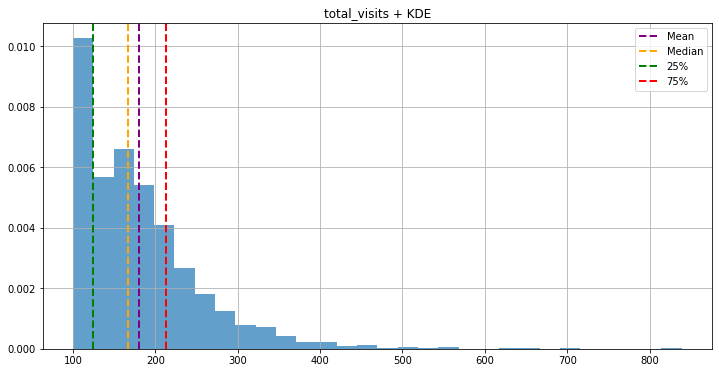

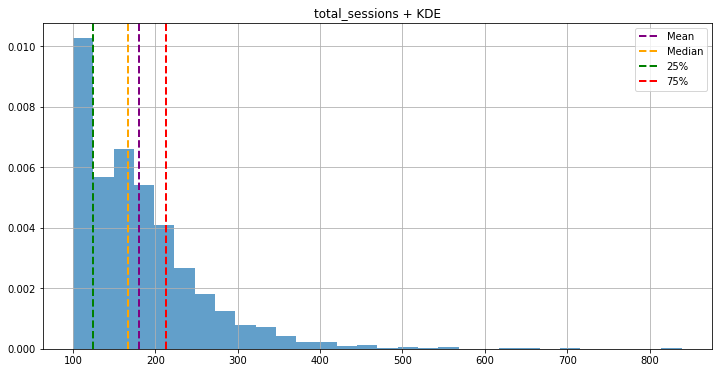

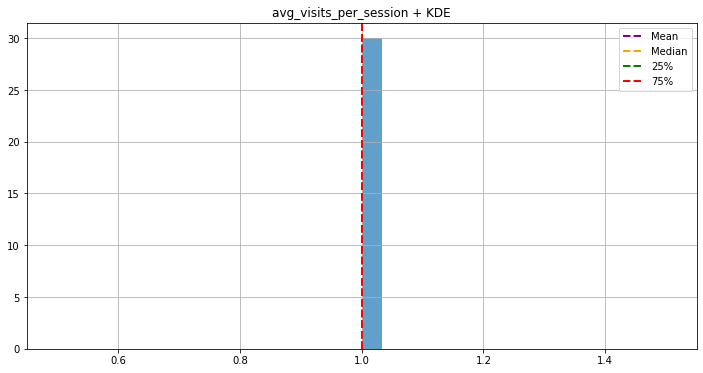

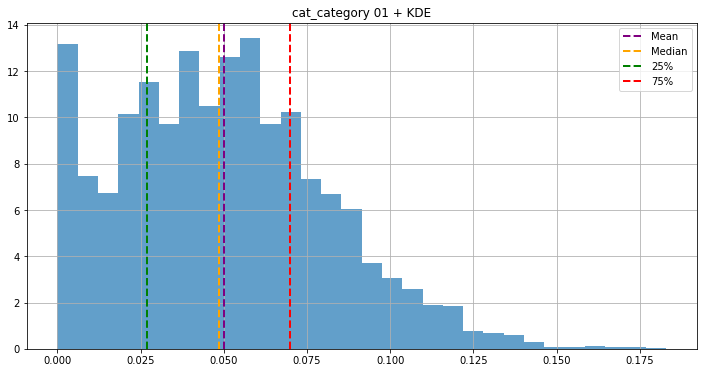

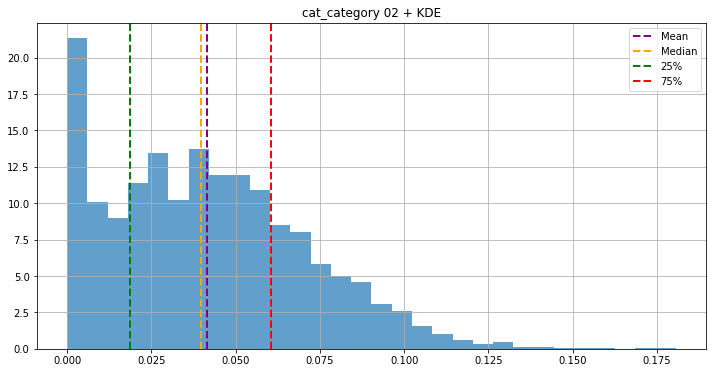

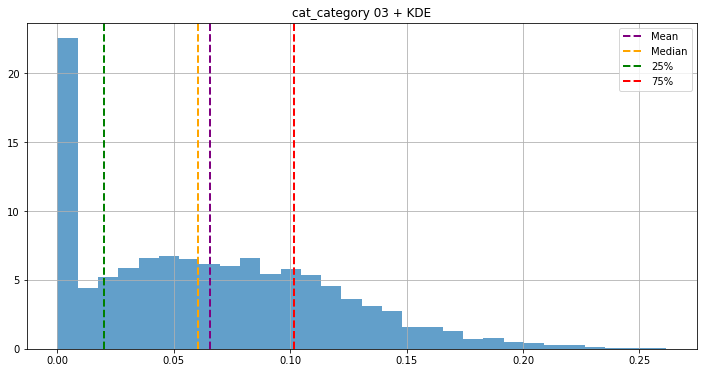

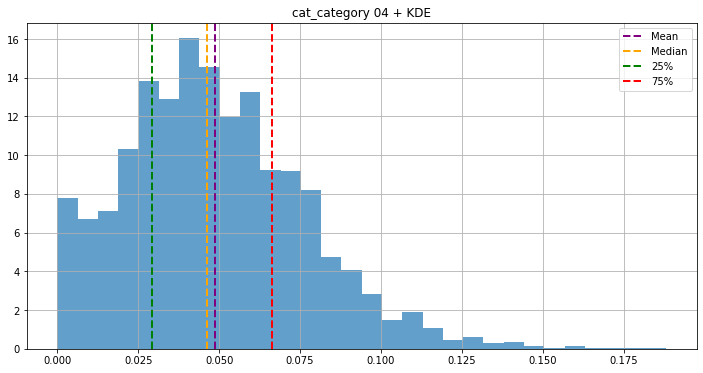

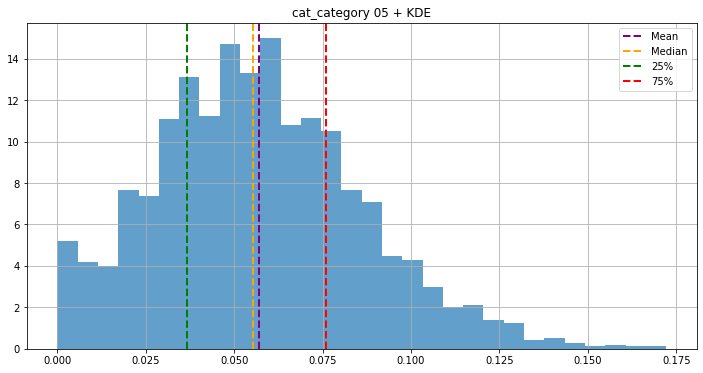

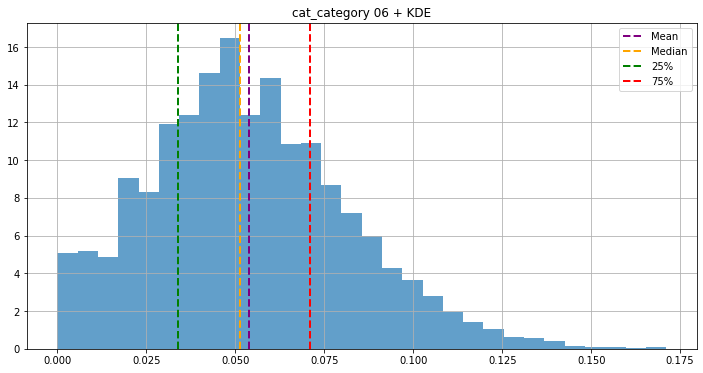

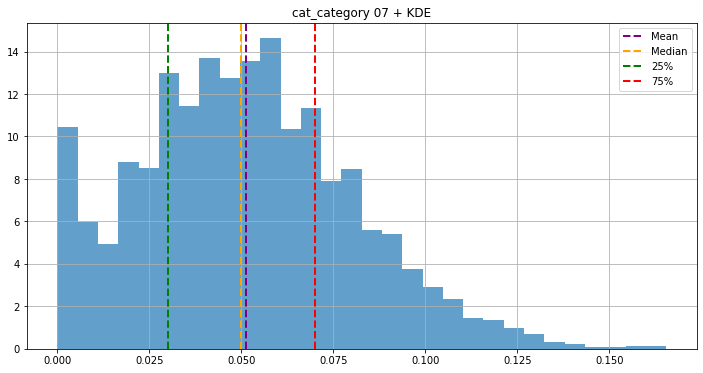

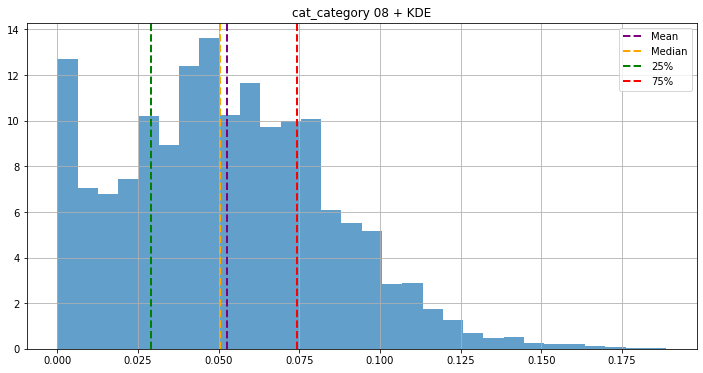

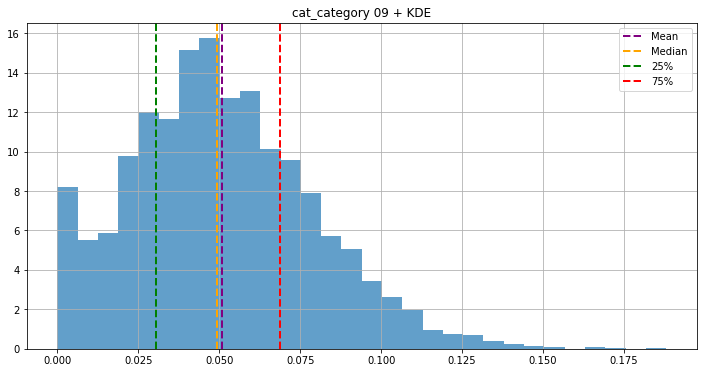

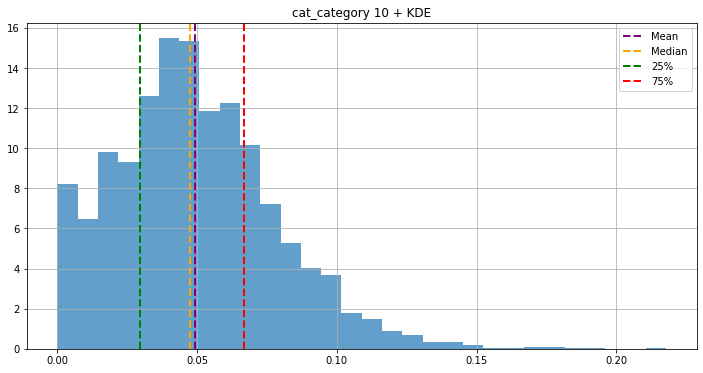

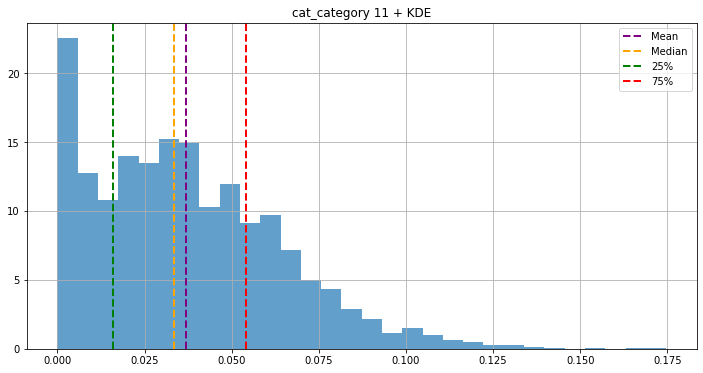

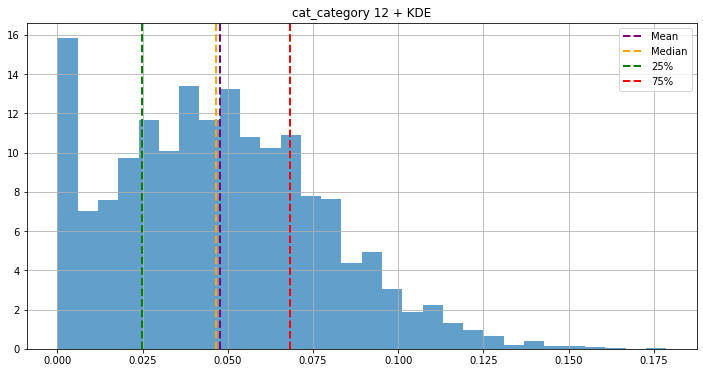

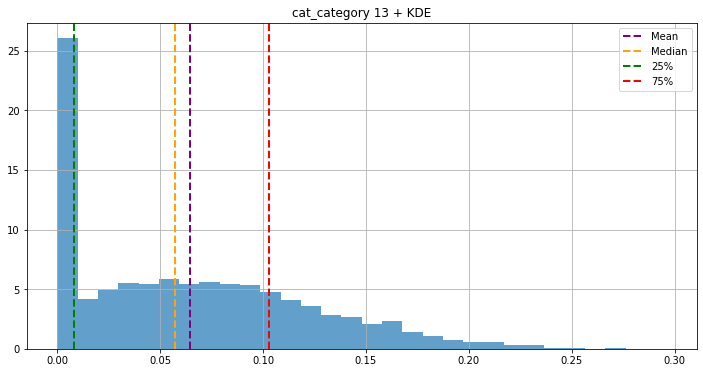

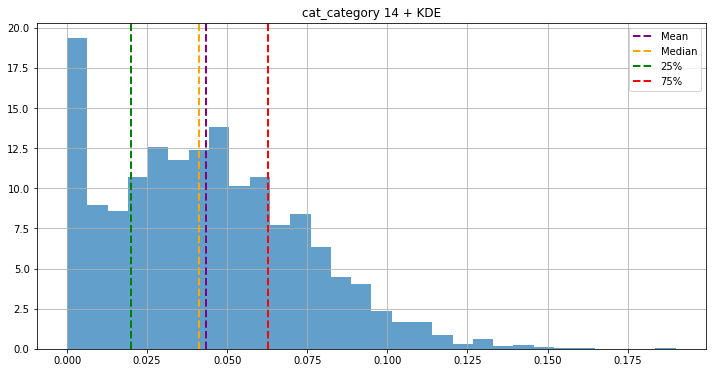

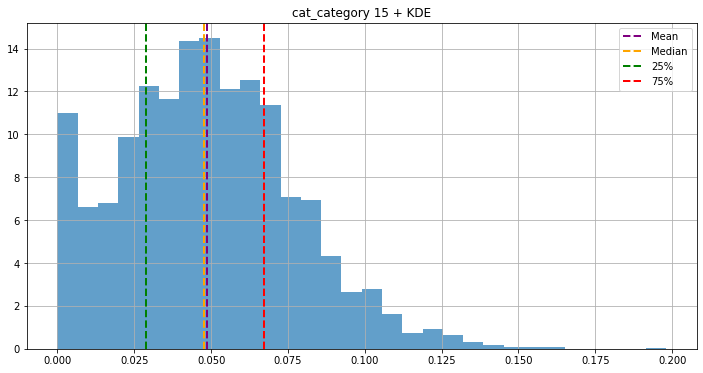

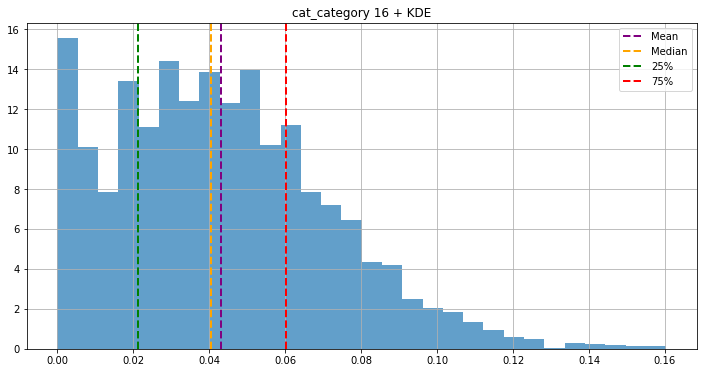

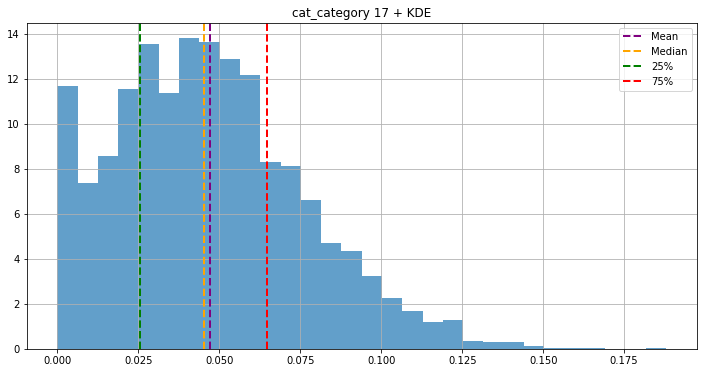

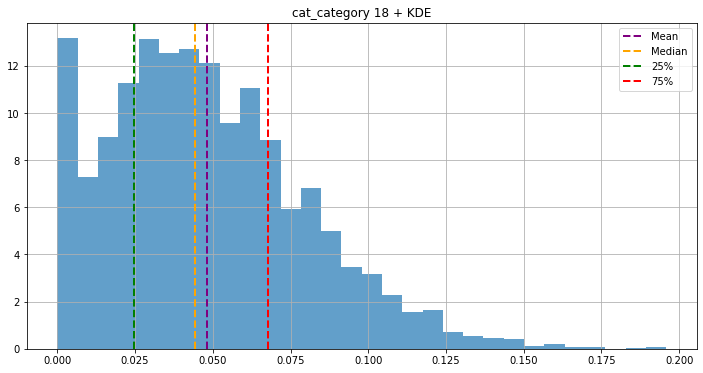

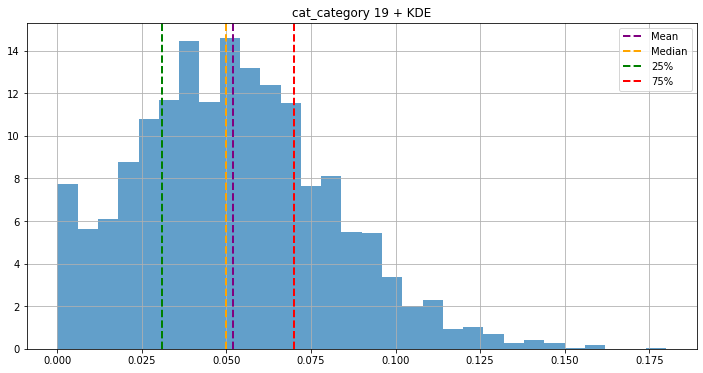

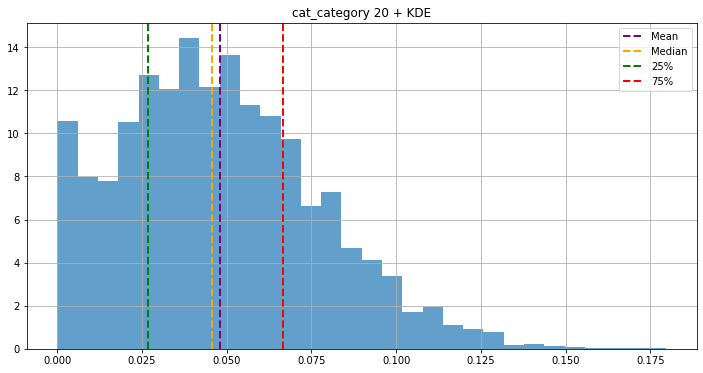

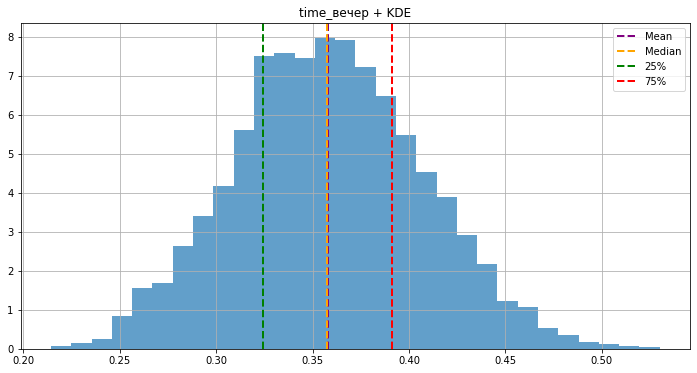

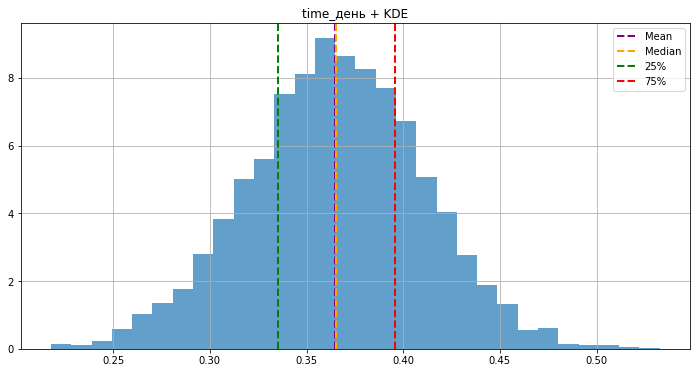

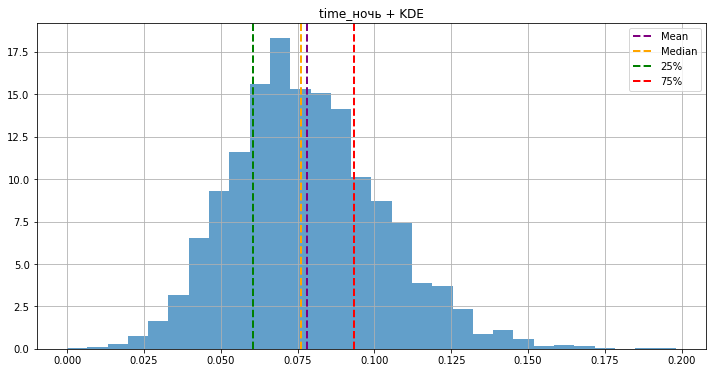

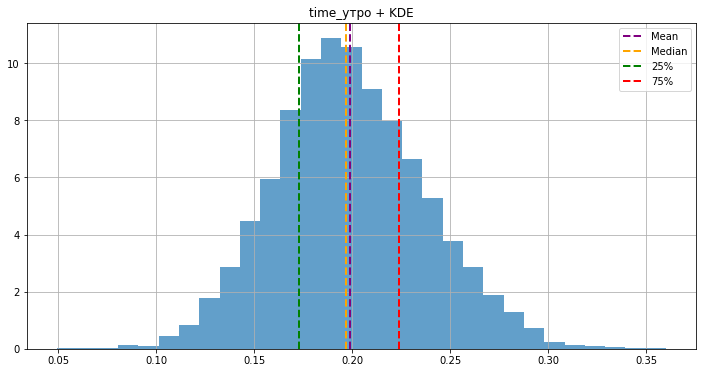

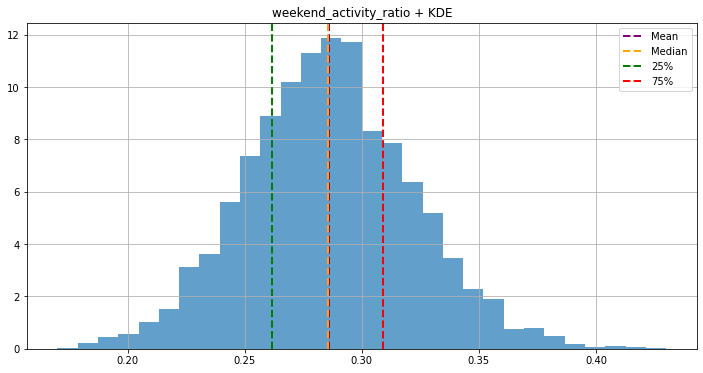

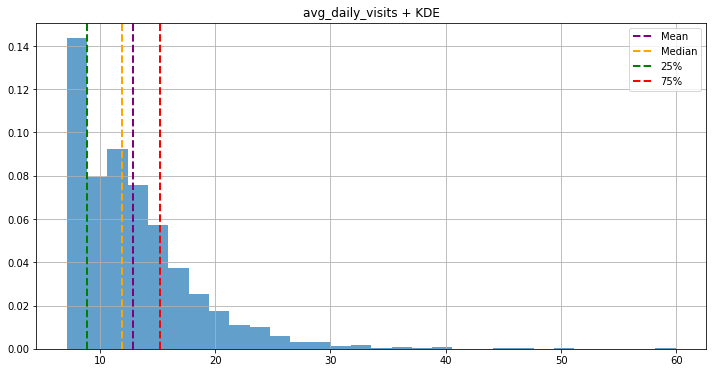

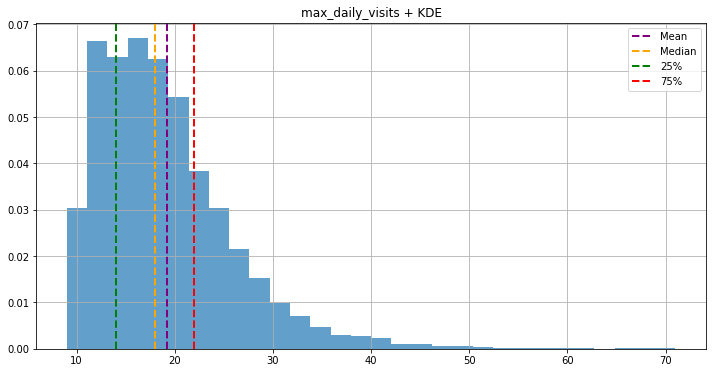

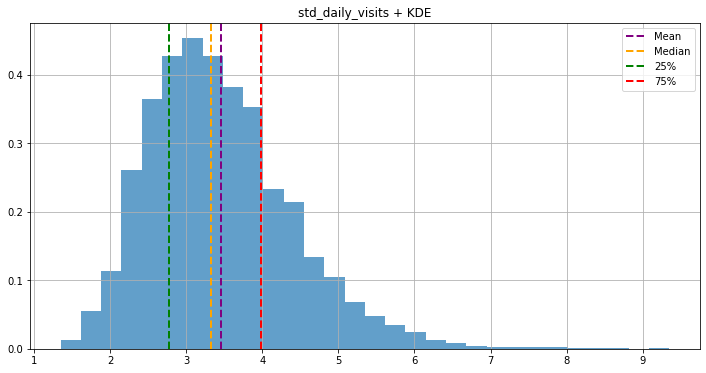

In [342]:
# Визуализируем для каждого непрерывного признака с помощью гистограммы:
for col in continuous_features:
    hist_visualize(col)

In [343]:
# Используем функцию для визуализации с помощью диаграммы размаха для выявления аномалий и выбросов для непрерывных признаков:
def boxplot_visualize(col):
    boxplot = df_final.boxplot(column=col,
                     vert=False, 
                     figsize=(12, 10))

    # Добавляем заголовок и метку оси X
    boxplot.set_title(f'Распределение {col}')
    boxplot.set_xlabel('Количество')

    plt.show()

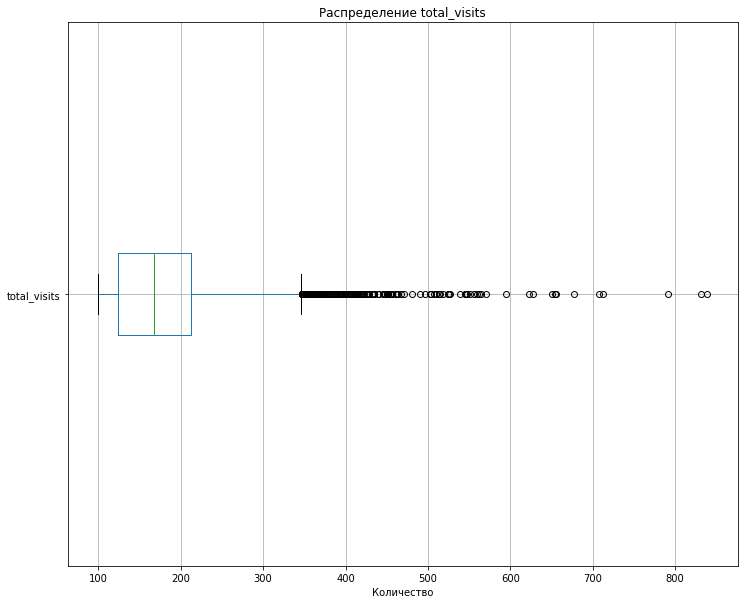

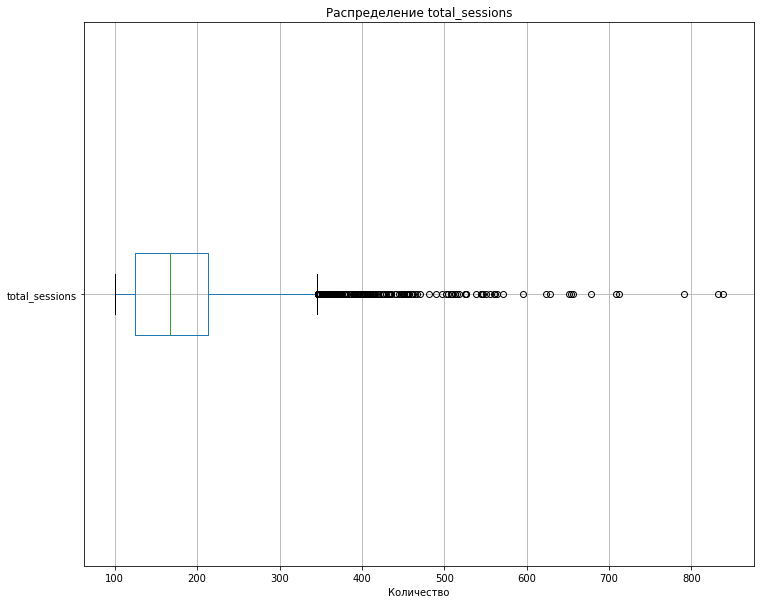

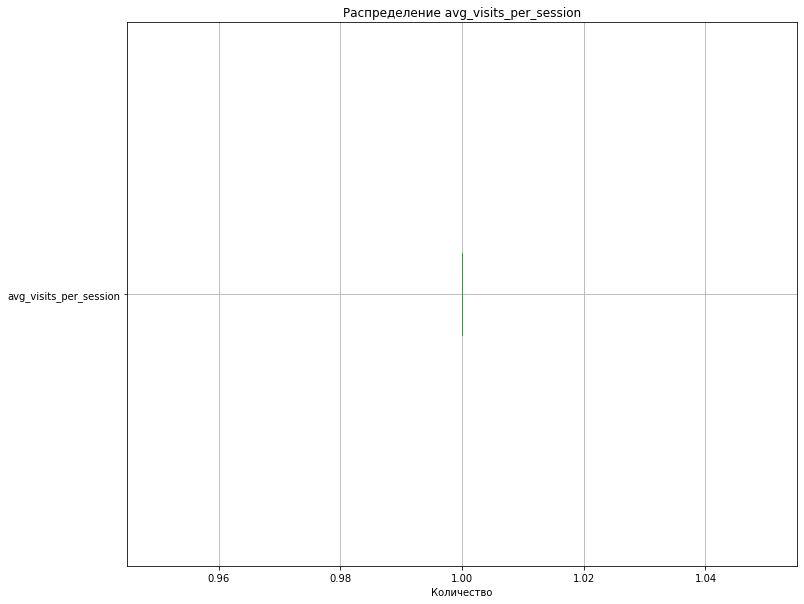

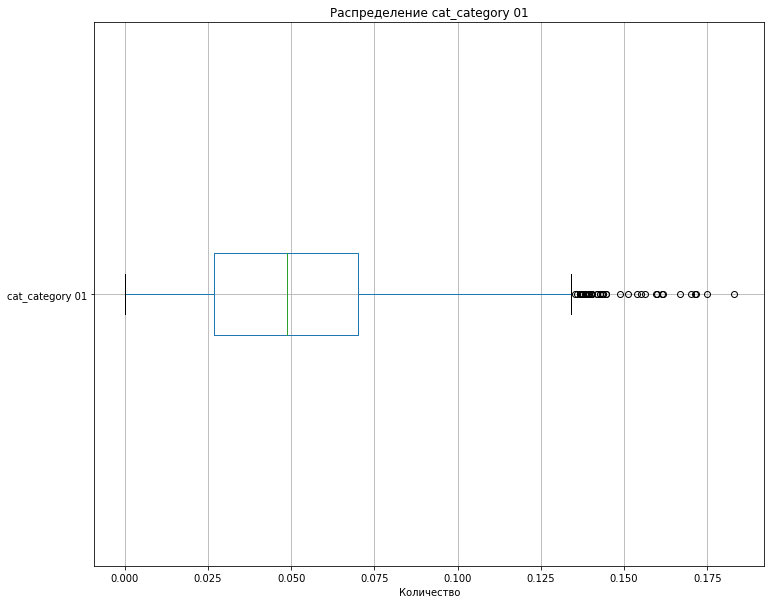

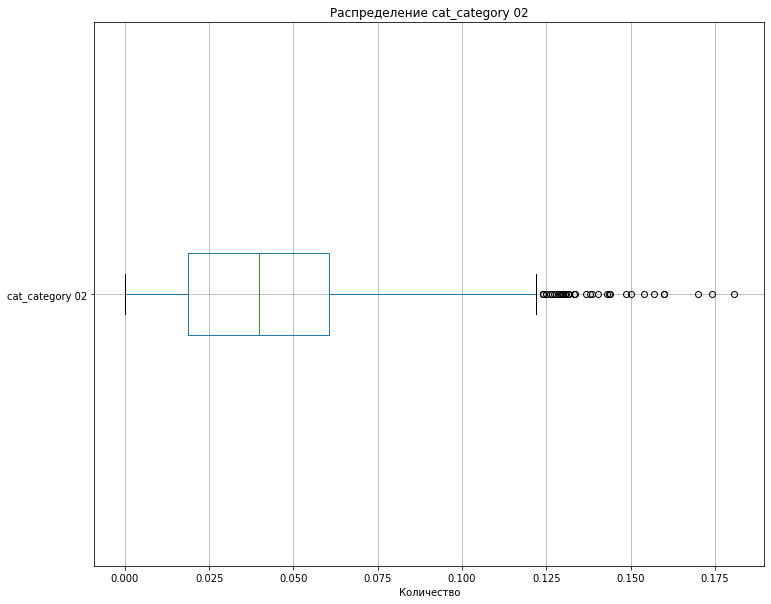

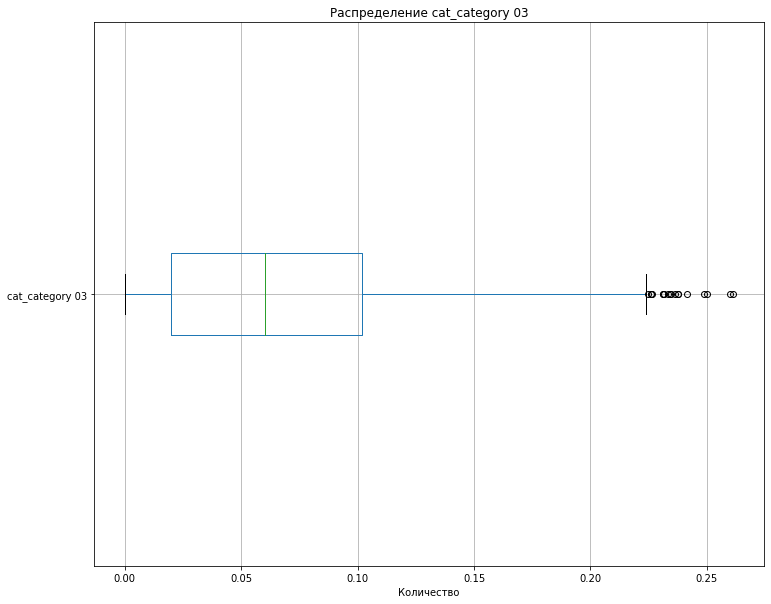

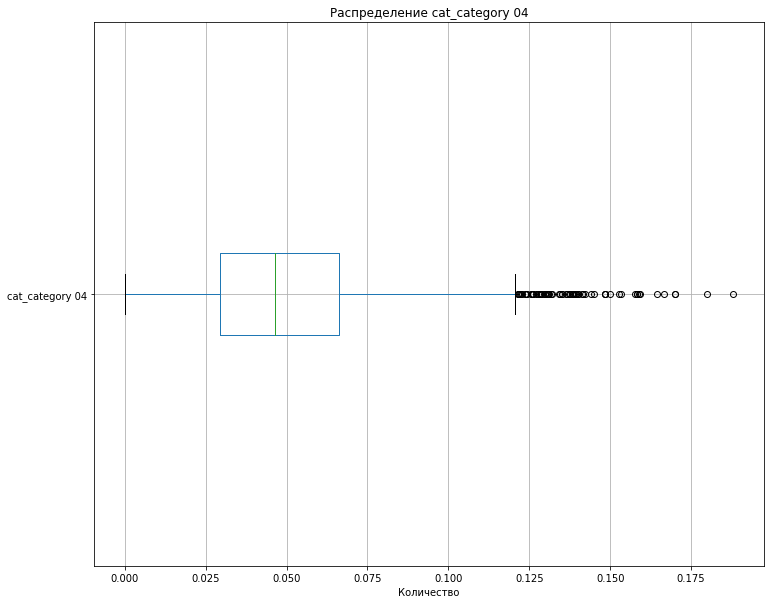

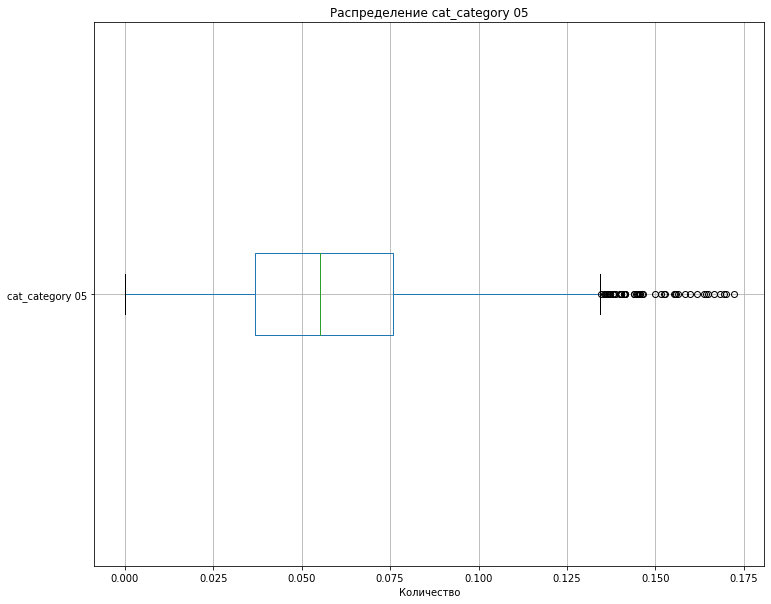

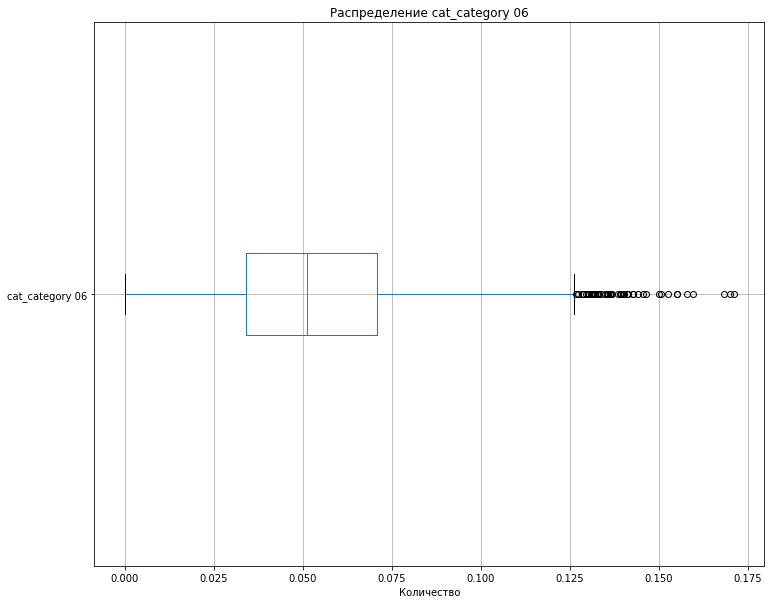

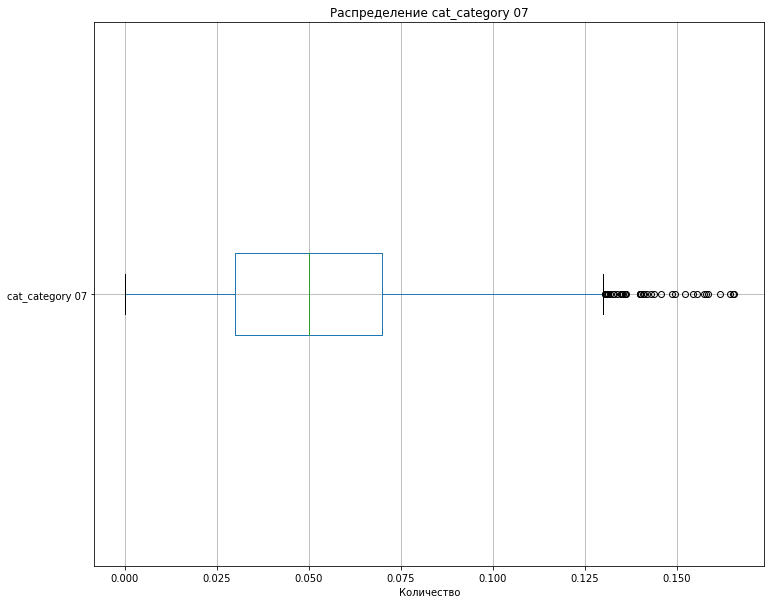

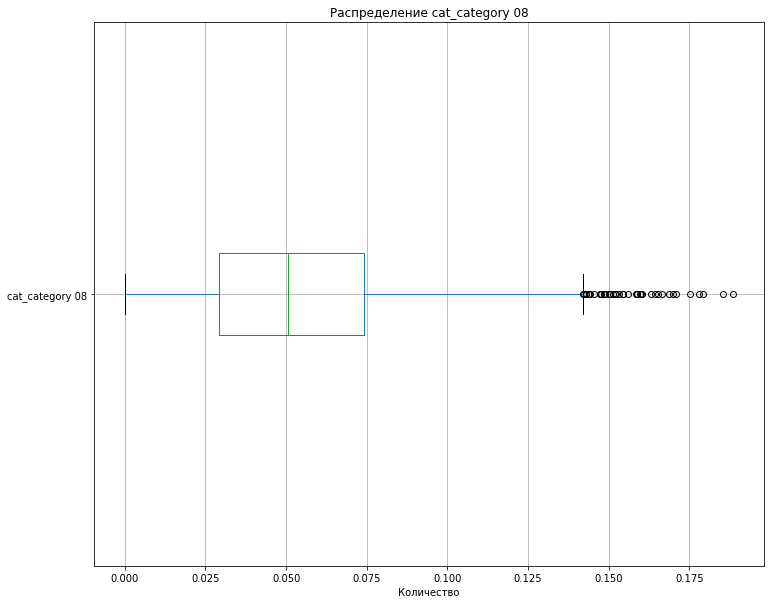

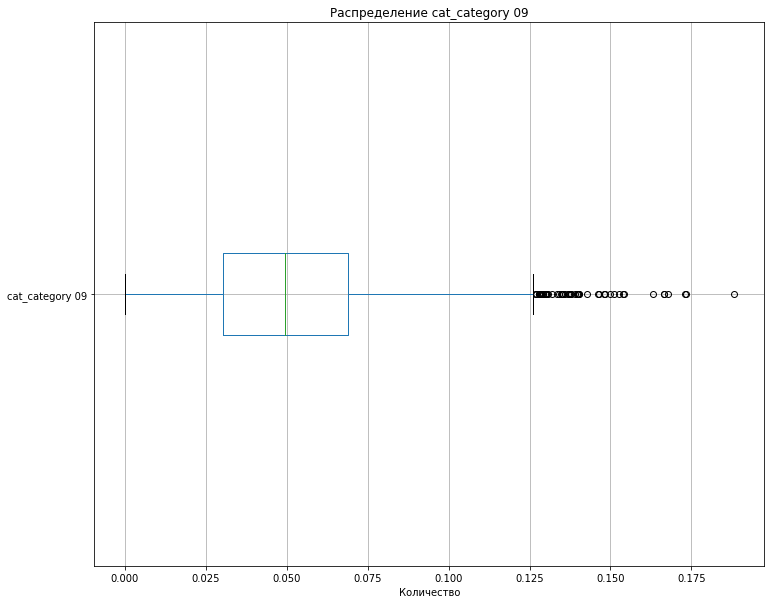

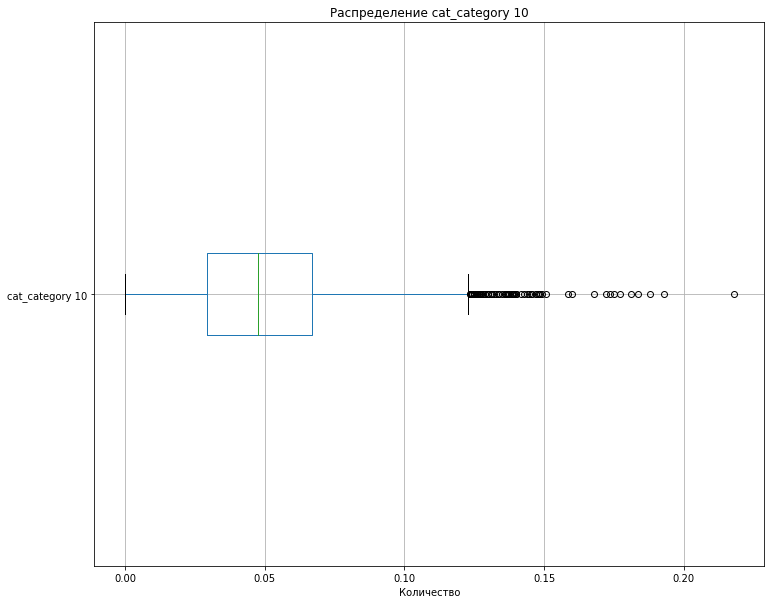

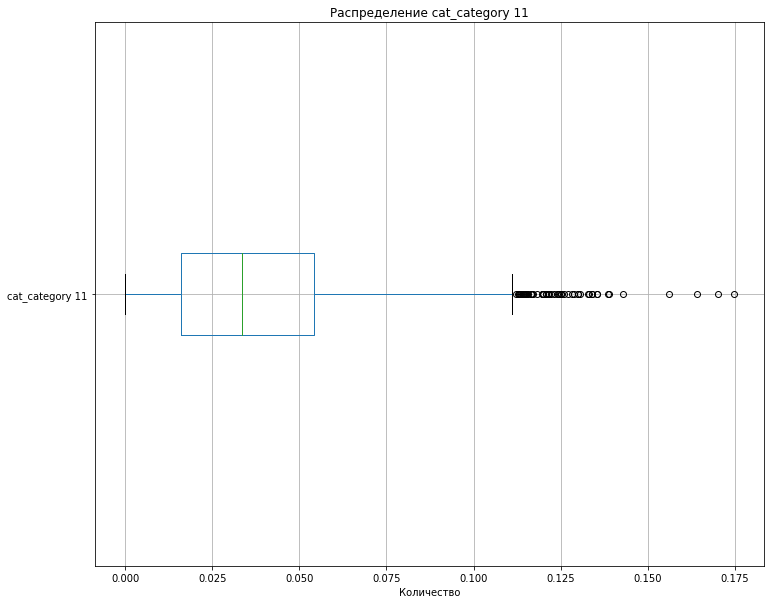

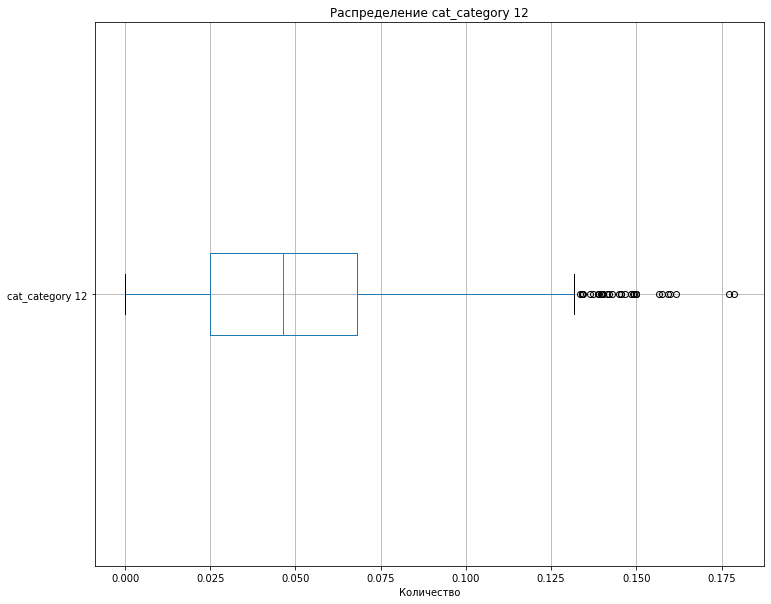

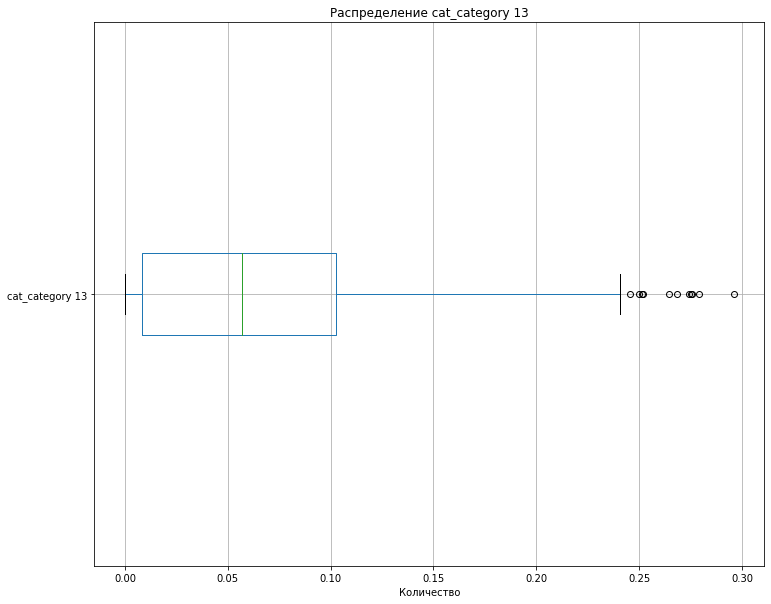

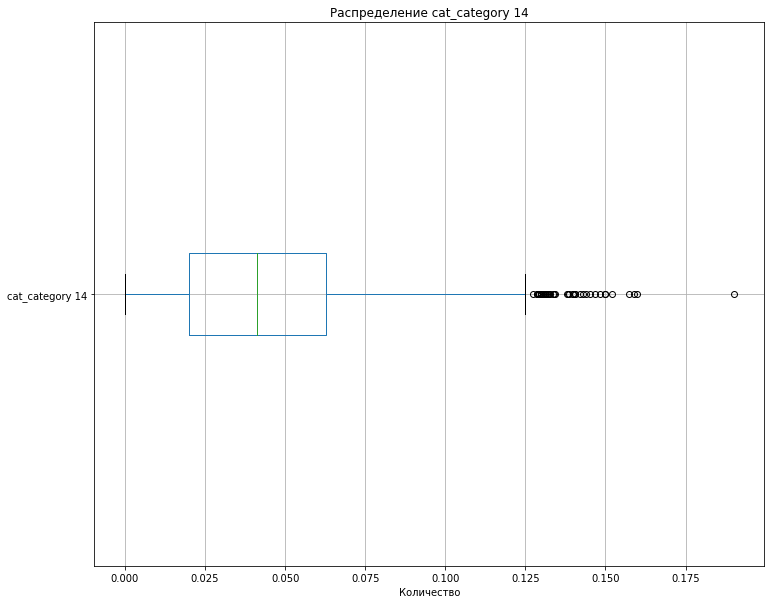

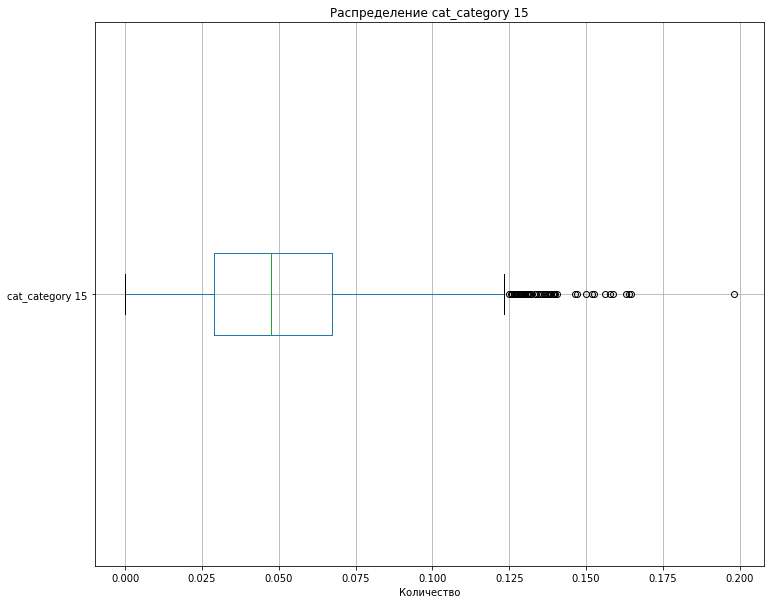

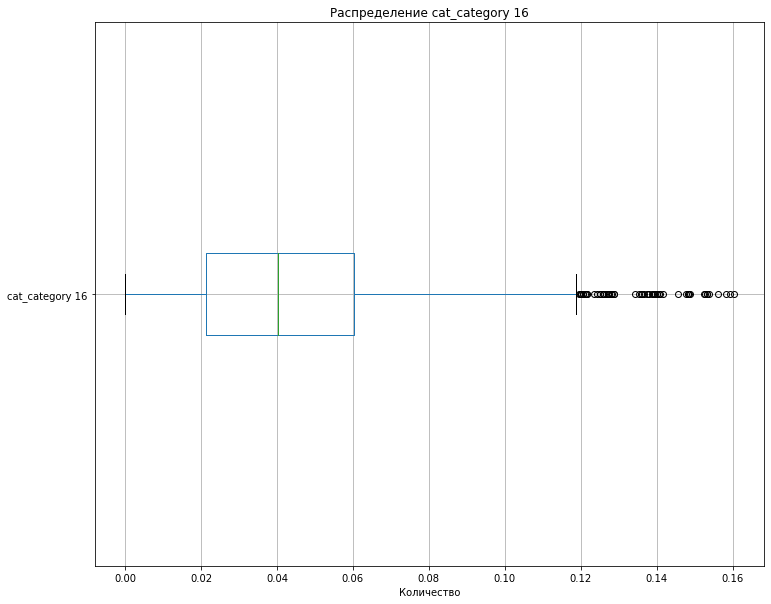

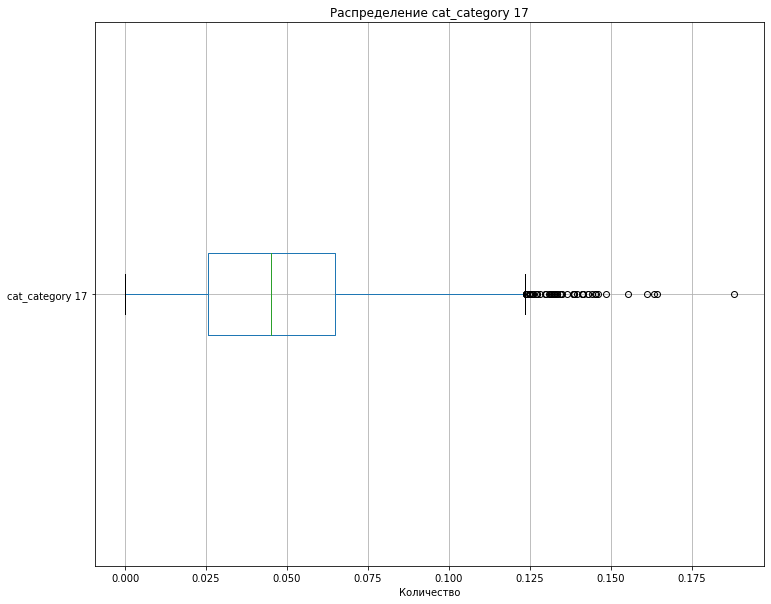

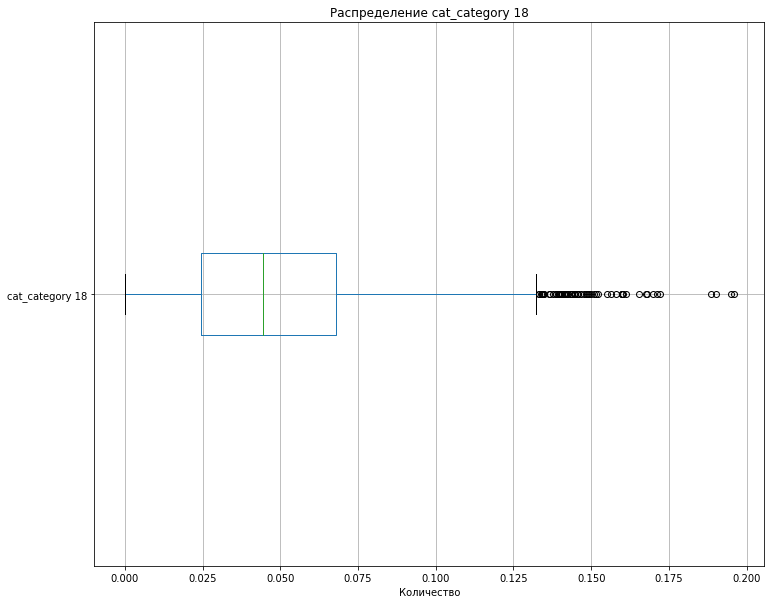

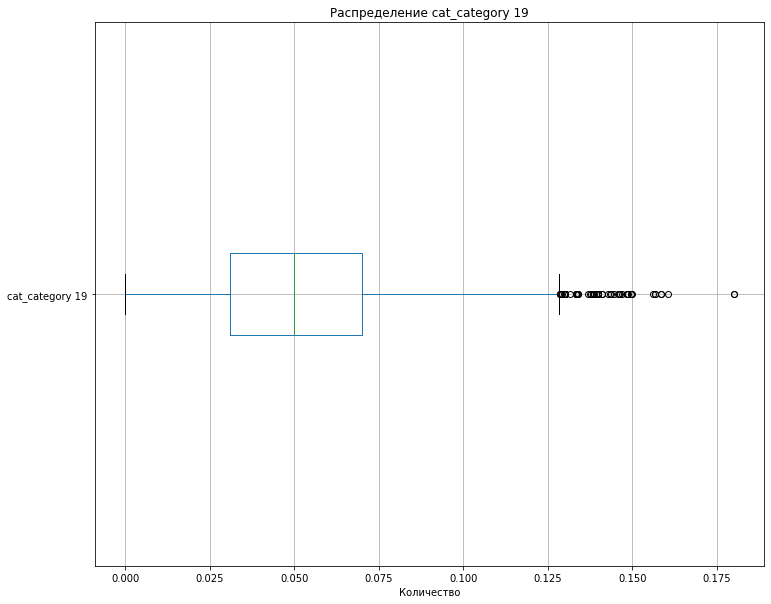

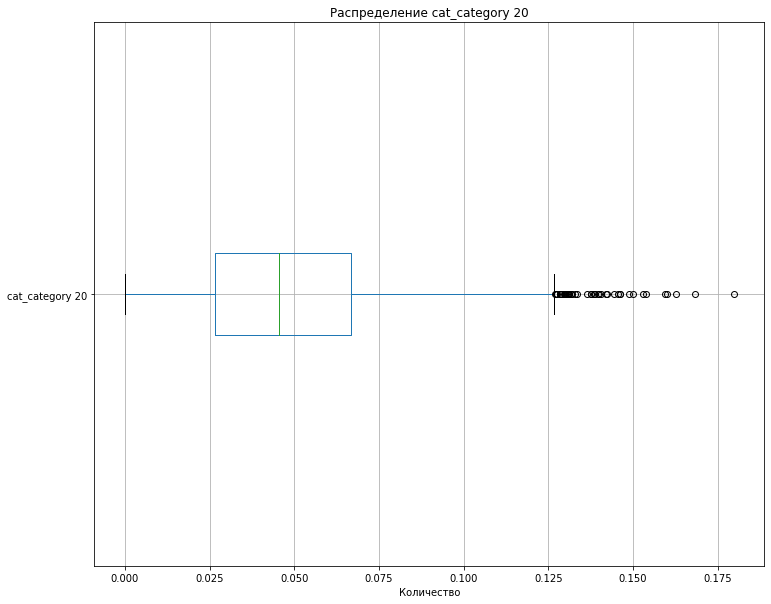

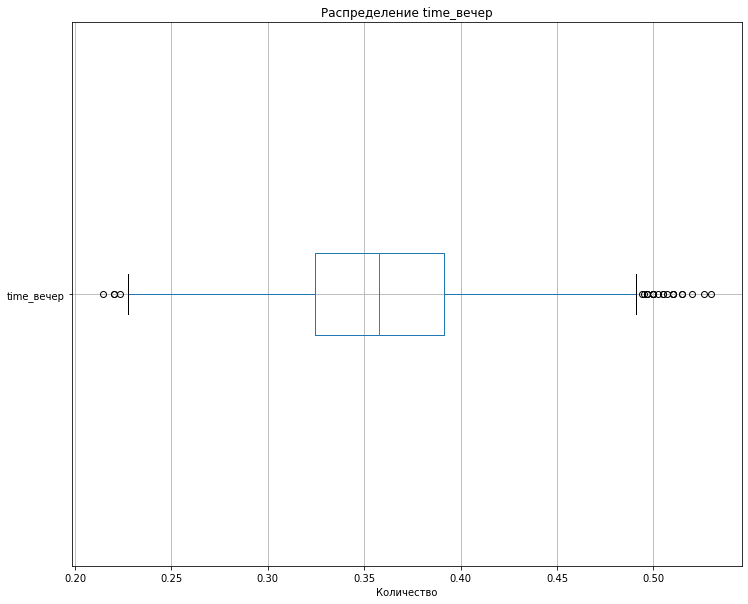

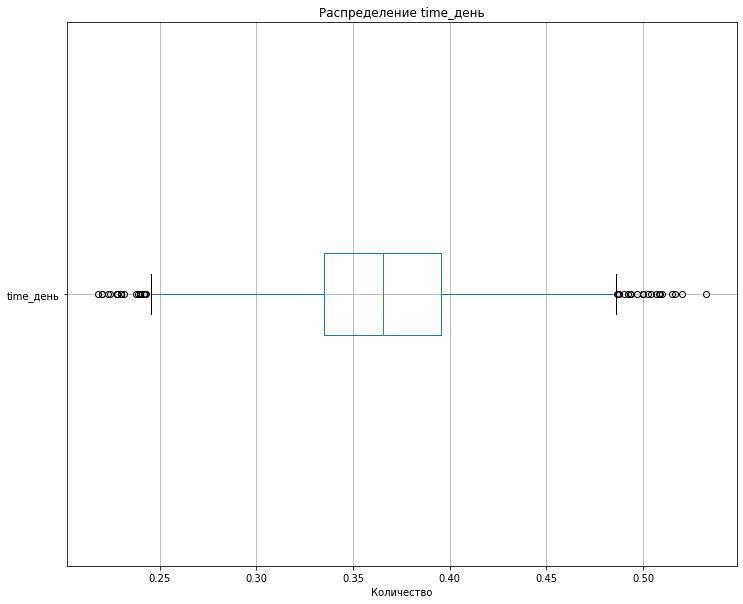

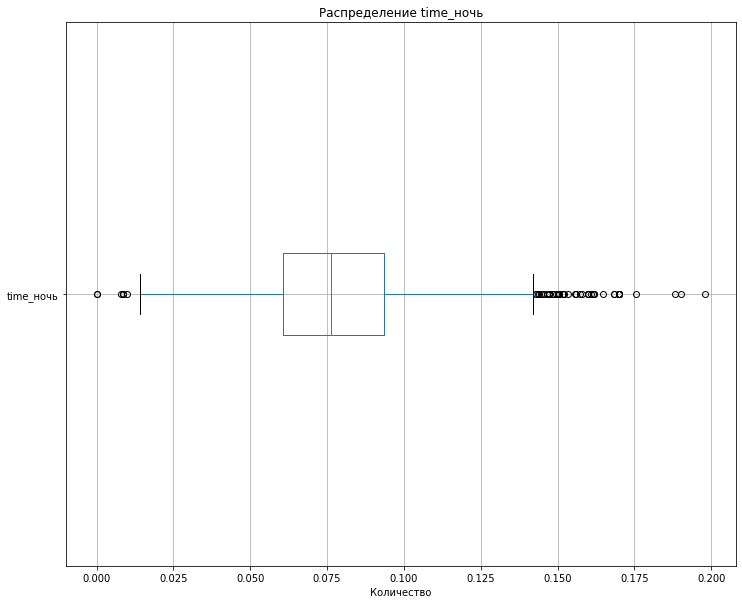

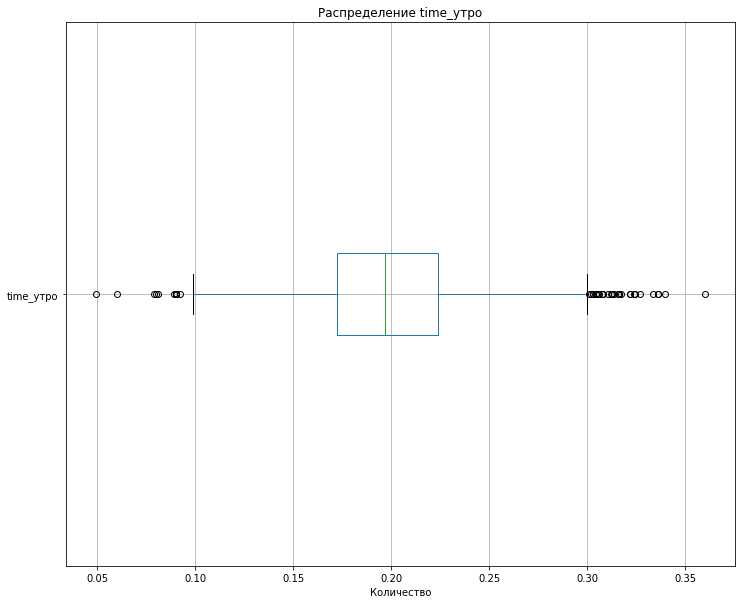

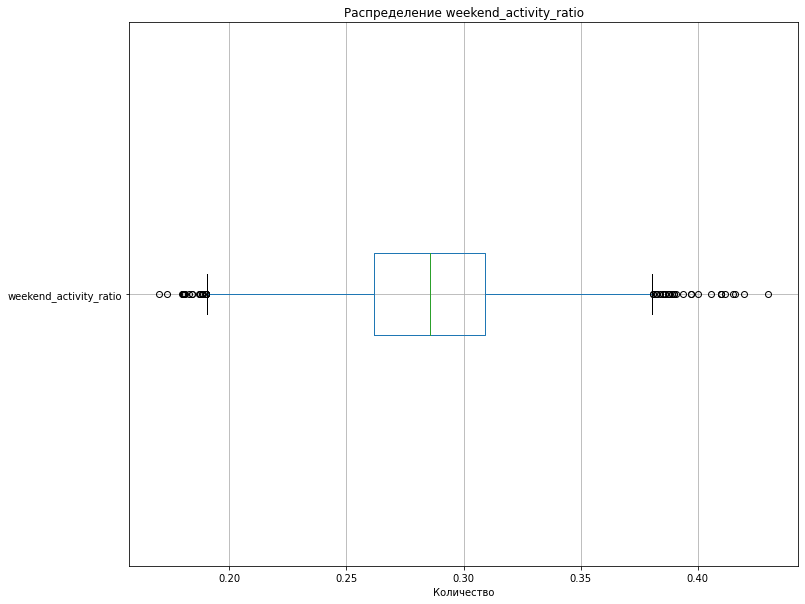

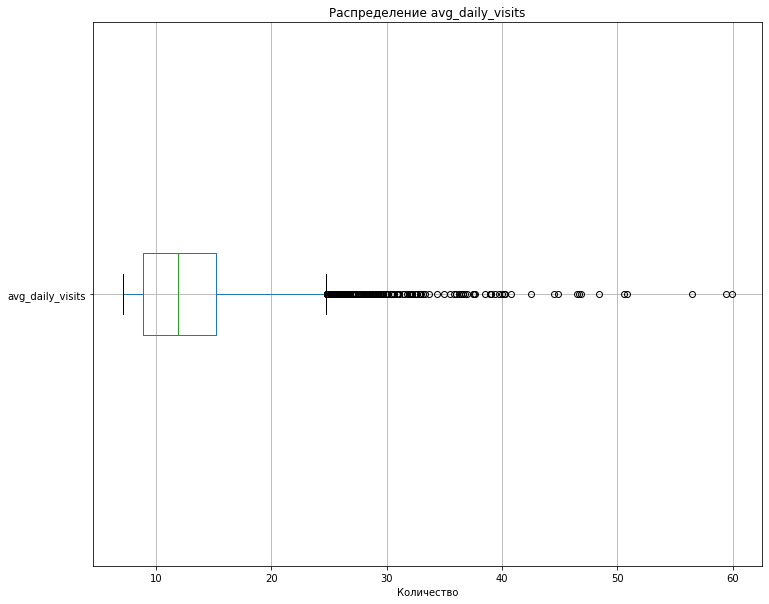

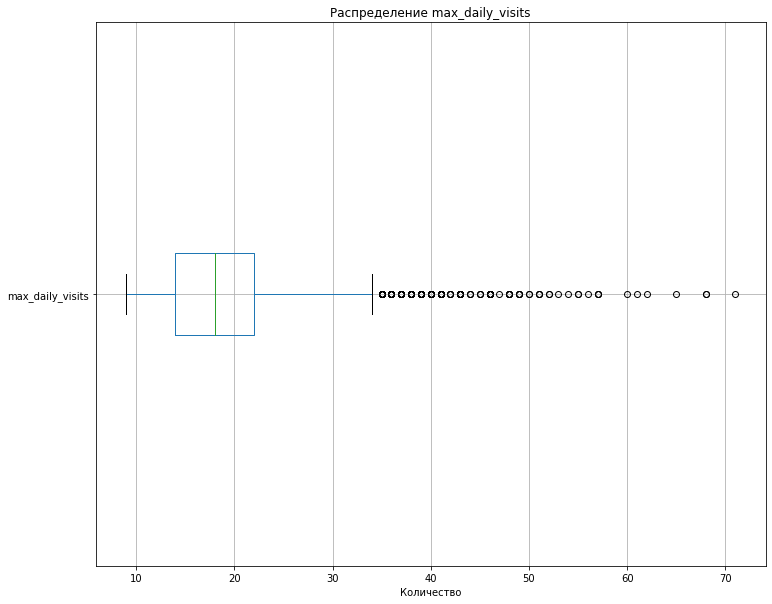

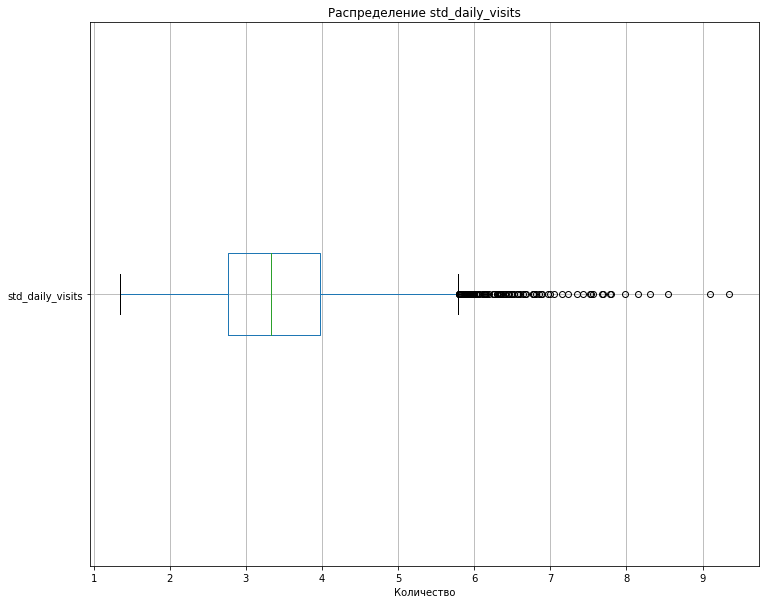

In [344]:
# Визуализируем для каждого непрерывного признака с помощью "ящика с усами" boxplot:
for col in continuous_features:
    boxplot_visualize(col)

**Вывод:**

Наблюдается типичное «распределение Парето» (или «длинный хвост»): основная масса пользователей очень похожа, а небольшая группа сильно выделяется. Это классическая ситуация для веб-аналитики, где выбросы — это не «мусор», а самые активные или необычные сегменты клиентов.
    
    Присутствуют признаки с распределением выбросов:
        
        - нормальным (выбросы справа незначительные с точки зрения самого признака ): cat_category_01 - cat_category_20

        - ассиметричным (присутствует хвост справа): total_visits,total_sessions,avg_visits_per_session,avg_daily_visits,max_daily_visits,std_daily_visits

In [345]:
# Используем функцию для визуализации countplot для дискретных признаков:
def countplot_visualize(col):
    countplot = sns.countplot(data=df_final, x=col, palette='viridis')

    # Добавляем заголовок и метку оси X
    countplot.set_title(f'Распределение {col}')
    countplot.set_xlabel('Значение')
    countplot.set_ylabel('Количество')

    plt.show()

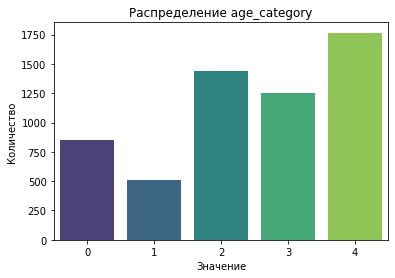

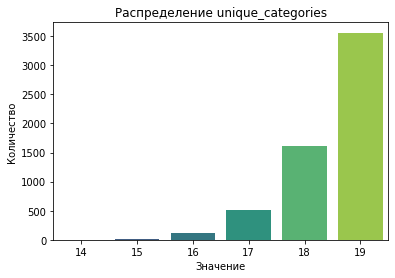

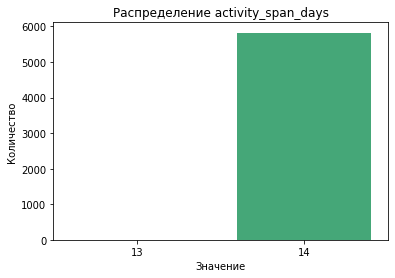

In [346]:
# Визуализируем для каждого дискретного признака с помощью countplot:
for col in discrete_features:
    countplot_visualize(col)

**Вывод:**

Для дискретных признаков наблюдается дисбаланс по категориям:

- **activity_span_days**: Почти все данные сосредоточены в категории «14». Категория «13» практически пустая или имеет ничтожно малое количество наблюдений.

    Признак практически константный (не вариативный). В машинном обучении такие признаки обычно не несут полезной информации для модели, так как почти не дают вариативности. Скорее всего, его **можно будет удалить при подготовке данных**.Для почти константных признаков (как activity_span_days) перед обучением модели необходимо првоерить корреляцию этого признака с целевой переменной. Если она близка к нулю — удалить как «шум».


- unique_categories: Явный рост от 14 к 19. Классы 18 и 19 являются доминирующими.

    Есть выраженный дисбаланс. Если 19 — это целевая категория (или самая частая), модель будет лучше всего предсказывать именно её, так как у неё больше всего примеров для «обучения». Чтобы избежать того, что модель будет «лениться» при обучении требуется использовать взвешивание классов (class_weight='balanced')


- age_category: Распределение более равномерное, чем на других графиках, но тоже есть перекос: категория 4 самая частая, а категория 1 — самая редкая.

    Признак (целевая переменная) имеет хорошую вариативность.
    
При предобработке данных необходимо использовать масштабирование методом StandardScaler()

### Корреляция признаков с целевой переменной

In [347]:
#Для корреляции  используем числовые признаки датасета
corr_columns = df_final.select_dtypes(include=['int64', 'float64']).columns

df_corr=df_final[corr_columns]

# Убираем дискретные признаки discrete_features из interval_cols

interval_cols = corr_columns.drop(discrete_features)
interval_cols

Index(['total_visits', 'total_sessions', 'avg_visits_per_session',
       'cat_category 01', 'cat_category 02', 'cat_category 03',
       'cat_category 04', 'cat_category 05', 'cat_category 06',
       'cat_category 07', 'cat_category 08', 'cat_category 09',
       'cat_category 10', 'cat_category 11', 'cat_category 12',
       'cat_category 13', 'cat_category 14', 'cat_category 15',
       'cat_category 16', 'cat_category 17', 'cat_category 18',
       'cat_category 19', 'cat_category 20', 'time_вечер', 'time_день',
       'time_ночь', 'time_утро', 'weekend_activity_ratio', 'avg_daily_visits',
       'max_daily_visits', 'std_daily_visits'],
      dtype='object')

In [348]:
df_corr.columns

Index(['age_category', 'total_visits', 'total_sessions', 'unique_categories',
       'activity_span_days', 'avg_visits_per_session', 'cat_category 01',
       'cat_category 02', 'cat_category 03', 'cat_category 04',
       'cat_category 05', 'cat_category 06', 'cat_category 07',
       'cat_category 08', 'cat_category 09', 'cat_category 10',
       'cat_category 11', 'cat_category 12', 'cat_category 13',
       'cat_category 14', 'cat_category 15', 'cat_category 16',
       'cat_category 17', 'cat_category 18', 'cat_category 19',
       'cat_category 20', 'time_вечер', 'time_день', 'time_ночь', 'time_утро',
       'weekend_activity_ratio', 'avg_daily_visits', 'max_daily_visits',
       'std_daily_visits'],
      dtype='object')

In [349]:
phik_corr_matrix = df_corr.phik_matrix(interval_cols=interval_cols)
phik_corr_matrix

/opt/conda/lib/python3.9/site-packages/phik/data_quality.py:72: UserWarning: Not enough unique value for variable avg_visits_per_session for analysis 1. Dropping this column
  warnings.warn(


,age_category,total_visits,total_sessions,unique_categories,activity_span_days,cat_category 01,cat_category 02,cat_category 03,cat_category 04,cat_category 05,...,cat_category 19,cat_category 20,time_вечер,time_день,time_ночь,time_утро,weekend_activity_ratio,avg_daily_visits,max_daily_visits,std_daily_visits
age_category,1.000000,0.065297,0.065297,0.077844,0.000000,0.272933,0.406494,0.376865,0.416194,0.323572,...,0.314134,0.466237,0.686111,0.566752,0.532861,0.578419,0.000000,0.065297,0.101689,0.054942
total_visits,0.065297,1.000000,1.000000,0.198445,0.000000,0.058225,0.000000,0.000000,0.047386,0.055327,...,0.000000,0.091586,0.144937,0.143166,0.146330,0.150014,0.203693,1.000000,0.961759,0.764601
total_sessions,0.065297,1.000000,1.000000,0.198445,0.000000,0.058225,0.000000,0.000000,0.047386,0.055327,...,0.000000,0.091586,0.144937,0.143166,0.146330,0.150014,0.203693,1.000000,0.961759,0.764601
unique_categories,0.077844,0.198445,0.198445,1.000000,0.000000,0.142943,0.164306,0.161825,0.145220,0.135594,...,0.123222,0.185359,0.058003,0.025082,0.063393,0.083258,0.053645,0.198445,0.213976,0.143738
activity_span_days,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.100054,0.000000,0.043654,0.000000,...,0.000000,0.000000,0.033656,0.000000,0.000000,0.000000,0.054968,0.000000,0.000000,0.017754
cat_category 01,0.272933,0.058225,0.058225,0.142943,0.000000,1.000000,0.129134,0.309372,0.282594,0.052968,...,0.078234,0.075539,0.123900,0.052305,0.029342,0.103901,0.000000,0.058225,0.048910,0.036449
cat_category 02,0.406494,0.000000,0.000000,0.164306,0.100054,0.129134,1.000000,0.427643,0.072259,0.121507,...,0.200680,0.114338,0.163899,0.097118,0.133525,0.164428,0.000000,0.000000,0.000000,0.033841
cat_category 03,0.376865,0.000000,0.000000,0.161825,0.000000,0.309372,0.427643,1.000000,0.173118,0.094925,...,0.247620,0.154222,0.049301,0.051049,0.066903,0.045163,0.048006,0.000000,0.000000,0.000000
cat_category 04,0.416194,0.047386,0.047386,0.145220,0.043654,0.282594,0.072259,0.173118,1.000000,0.173431,...,0.164341,0.136577,0.029462,0.069367,0.090001,0.000000,0.000000,0.047386,0.057874,0.000000
cat_category 05,0.323572,0.055327,0.055327,0.135594,0.000000,0.052968,0.121507,0.094925,0.173431,1.000000,...,0.288847,0.124710,0.129377,0.121379,0.000000,0.078440,0.041686,0.055327,0.032474,0.039717


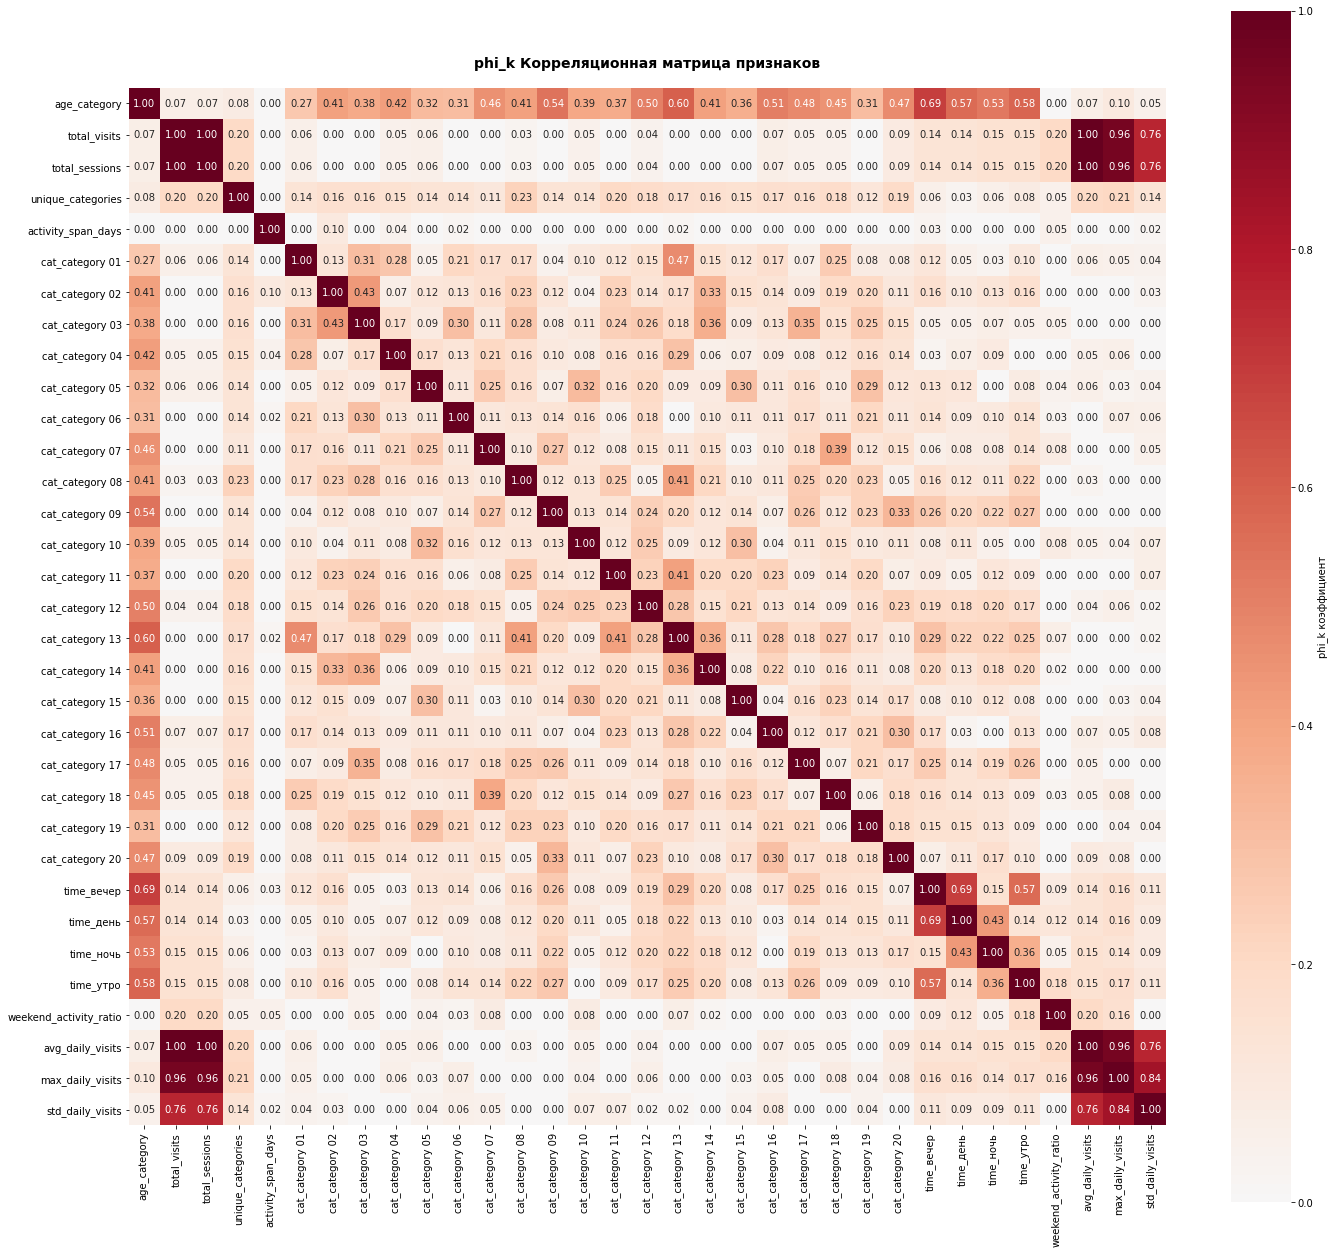

In [350]:
# Визуализируем матрицу корреляции с помощью heatmap
plt.figure(figsize=(20, 18))

# Корреляция всех признаков
sns.heatmap(phik_corr_matrix.round(2), 
            annot=True, cmap='RdBu_r', center=0,
            square=True, fmt='.2f',
            cbar_kws={'label': 'phi_k коэффициент'})

plt.title('phi_k Корреляционная матрица признаков', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

In [351]:
# Корреляции для age_category
phik_click_correlations_all = (phik_corr_matrix['age_category'].drop('age_category'))
phik_click_correlations_all.sort_values(ascending=False)

time_вечер                0.686111
cat_category 13           0.595733
time_утро                 0.578419
time_день                 0.566752
cat_category 09           0.536089
time_ночь                 0.532861
cat_category 16           0.507852
cat_category 12           0.503128
cat_category 17           0.482861
cat_category 20           0.466237
cat_category 07           0.460505
cat_category 18           0.452656
cat_category 04           0.416194
cat_category 08           0.412309
cat_category 14           0.411782
cat_category 02           0.406494
cat_category 10           0.387249
cat_category 03           0.376865
cat_category 11           0.366315
cat_category 15           0.359040
cat_category 05           0.323572
cat_category 19           0.314134
cat_category 06           0.311592
cat_category 01           0.272933
max_daily_visits          0.101689
unique_categories         0.077844
avg_daily_visits          0.065297
total_visits              0.065297
total_sessions      

**Вывод:**

Анализ корреляционной матрицы phik показывает несколько критически важных моментов для подготовки данных к обучению модели:

1. Сильно скоррелированные признаки (Мультиколлинеарность)
В данных есть группы признаков, которые дублируют друг друга. Включение всех их в модель может привести к переобучению и ухудшению интерпретируемости.

- total_visits и total_sessions: Корреляция между ними 1.00. Это означает, что они несут идентичную информацию.

    **Необходимо удалить один из них (например, total_sessions).**

- **avg_daily_visits, total_visits, max_daily_visits**: Эти признаки также имеют очень высокую корреляцию (0.96–0.98).

    Необходимо **оставить только один наиболее репрезентативный (например, max_daily_visits), остальные можно удалить.**

- Группы cat_category_XX: На матрице видно, что некоторые категории имеют умеренную корреляцию между собой (например, cat_category_13 и cat_category_01 — 0.47).


2. Признаки с целевой переменной age_category

Наибольшее влияние (наивысшая корреляция) на целевую переменную оказывают:

Временные признаки: time_вечер (0.68), time_утро (0.58), time_день (0.57), time_ночь (0.53). Это говорит о том, что время активности пользователя — ключевой фактор определения его возрастной категории.

Категориальные признаки: cat_category_13 (0.60), cat_category_09 (0.53).

Слабые признаки: total_visits, total_sessions, unique_categories имеют крайне низкую корреляцию с возрастом (менее 0.1). Это значит, что интенсивность использования приложения почти не связана с возрастом пользователя.

3. «Нулевые» признаки
Признаки **weekend_activity_ratio, avg_visits_per_session и activity_span_days** имеют корреляцию с целевой переменной 0.00.

    Эти признаки не приносят никакой пользы для классификации по возрасту. Необходимо **удалить их перед обучением модели**, чтобы уменьшить размерность данных и снизить шум.

**Итоговый план обработки (Feature Selection):**

- Удалить константы/шум: weekend_activity_ratio, avg_visits_per_session, activity_span_days.

- Устранить мультиколлинеарность:

    - Из пары total_visits / total_sessions оставить только один.

    - Из группы avg_daily_visits / max_daily_visits / total_visits оставить только max_daily_visits.

- Оставить: 

    - Все временные признаки (time_...), так как они дают сильный сигнал.

    - Категориальные признаки (cat_category_...), которые имеют корреляцию с целевой переменной выше 0.3–0.4. 
    
    - Остальные можно протестировать на важность позже, при отборе признаков.

На этапе EDA удалить можно только признак user_id как технический признак

In [352]:
# Удаляем признак user_id как технический признак
df_final.drop(columns=['user_id'],inplace=True)

In [353]:
df_final.columns

Index(['age_category', 'total_visits', 'total_sessions', 'unique_categories',
       'activity_span_days', 'avg_visits_per_session', 'cat_category 01',
       'cat_category 02', 'cat_category 03', 'cat_category 04',
       'cat_category 05', 'cat_category 06', 'cat_category 07',
       'cat_category 08', 'cat_category 09', 'cat_category 10',
       'cat_category 11', 'cat_category 12', 'cat_category 13',
       'cat_category 14', 'cat_category 15', 'cat_category 16',
       'cat_category 17', 'cat_category 18', 'cat_category 19',
       'cat_category 20', 'time_вечер', 'time_день', 'time_ночь', 'time_утро',
       'most_active_time', 'weekend_activity_ratio', 'avg_daily_visits',
       'max_daily_visits', 'std_daily_visits', 'ads_activity', 'surf_depth',
       'primary_device', 'cloud_usage'],
      dtype='object')

## Предобработка данных

### Разделение на обучающую и тестовую выборки

Перед обработкой данных разделим данные на обучающу, валидационную и тестовую выборки:

In [354]:
# Отделяем признаки и целевую переменную
X = df_final.drop(columns=['age_category'])

y = df_final['age_category']

In [355]:
X.shape

(5826, 38)

In [356]:
y.shape

(5826,)

In [357]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=TEST_SIZE,stratify=y,
                                                 shuffle=True,random_state=RANDOM_SEED)

In [358]:
X_train.shape

(4660, 38)

In [359]:
X_test.shape

(1166, 38)

In [360]:
y_train.shape

(4660,)

In [361]:
y_test.shape

(1166,)

### Построение пайплайнов

In [362]:
# Pipeline для числовых признаков
num_pipeline = Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='mean')),
    ('scaler',StandardScaler())
])

In [363]:
# Pipeline для категориальных признаков
cat_pipeline = Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='constant',fill_value='unknown')),
    ('encoding',OneHotEncoder())
])

In [364]:
# Выделяем числовые признаки в обучающей выборке
numerical_features = X_train.select_dtypes(include=['number']).columns.tolist()
numerical_features

['total_visits',
 'total_sessions',
 'unique_categories',
 'activity_span_days',
 'avg_visits_per_session',
 'cat_category 01',
 'cat_category 02',
 'cat_category 03',
 'cat_category 04',
 'cat_category 05',
 'cat_category 06',
 'cat_category 07',
 'cat_category 08',
 'cat_category 09',
 'cat_category 10',
 'cat_category 11',
 'cat_category 12',
 'cat_category 13',
 'cat_category 14',
 'cat_category 15',
 'cat_category 16',
 'cat_category 17',
 'cat_category 18',
 'cat_category 19',
 'cat_category 20',
 'time_вечер',
 'time_день',
 'time_ночь',
 'time_утро',
 'weekend_activity_ratio',
 'avg_daily_visits',
 'max_daily_visits',
 'std_daily_visits']

In [365]:
# Выделяем категориальные признаки в обучающей выборке
categorical_features = X_train.select_dtypes(include=['object','string']).columns.tolist()
categorical_features

['most_active_time',
 'ads_activity',
 'surf_depth',
 'primary_device',
 'cloud_usage']

In [366]:
# Объединяем пайплайны с помощью трансформера
processor = ColumnTransformer(transformers=[
    ('num',num_pipeline,numerical_features),
    ('cat',cat_pipeline,categorical_features)  
],
    remainder='drop')

In [367]:
# Обучаем на обучающей выборке
processor.fit(X_train,y_train)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer', SimpleImputer()),
                                                 ('scaler', StandardScaler())]),
                                 ['total_visits', 'total_sessions',
                                  'unique_categories', 'activity_span_days',
                                  'avg_visits_per_session', 'cat_category 01',
                                  'cat_category 02', 'cat_category 03',
                                  'cat_category 04', 'cat_category 05',
                                  'cat_category 06', 'cat_category 07',
                                  'cat_category 08', 'c...
                                  'cat_category 16', 'cat_category 17',
                                  'cat_category 18', 'cat_category 19',
                                  'cat_category 20', 'time_вечер', 'time_день',
                                  'time_ночь', 'time_утро',
                                  'weekend_activity_ratio', ...]),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(fill_value='unknown',
                                                                strategy='constant')),
                                                 ('encoding',
                                                  OneHotEncoder())]),
                                 ['most_active_time', 'ads_activity',
                                  'surf_depth', 'primary_device',
                                  'cloud_usage'])])

## Обучение и оценка базовой модели

### DummyClassifier

In [368]:
dummy_model = DummyClassifier(strategy='stratified', random_state=RANDOM_SEED)

In [369]:
#Pipeline с dummy_model (базовая модель,случайный выбор ответа)
dummy_pipeline = Pipeline(steps = [
    ('processor',processor),
    ('model',dummy_model)    
])

In [370]:
# Создаём скореры с правильным average для многоклассовой задачи 
# (Модель нужно оценить одинаково по всем классам, даже если один из них встречается редко, 
# поэтому используем макро-усреднение.)
scoring = {
    'precision': make_scorer(precision_score, average='macro'),
    'recall': make_scorer(recall_score, average='macro'),
    'f1': make_scorer(f1_score, average='macro')
}

In [371]:
N_FOLDS = 5
kfold = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED)

In [372]:
cv_scores = cross_validate(
    dummy_pipeline, X_train, y_train,
    cv=kfold,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=True,
    error_score='raise'
)

In [373]:
cv_scores

{'fit_time': array([0.03510451, 0.02195644, 0.02240467, 0.02593422, 0.022053  ]),
 'score_time': array([0.01848197, 0.01636314, 0.01750422, 0.01719213, 0.01747274]),
 'test_precision': array([0.20763409, 0.20433286, 0.21750472, 0.22585578, 0.22006518]),
 'train_precision': array([0.19535739, 0.21424101, 0.1977558 , 0.19642868, 0.19858436]),
 'test_recall': array([0.20768086, 0.20378025, 0.21758796, 0.22600395, 0.22120425]),
 'train_recall': array([0.19534574, 0.21433492, 0.1976025 , 0.19659855, 0.19854692]),
 'test_f1': array([0.20751782, 0.20396842, 0.21741739, 0.22579999, 0.22047558]),
 'train_f1': array([0.19529233, 0.21421878, 0.19761564, 0.19645111, 0.19850161])}

In [374]:
# Вывод результатов
cv_results = {}
# Создаём DataFrame для удобного отображения
results_df = pd.DataFrame({
    'metric': ['precision', 'recall', 'f1'],
    'train_mean': [
        cv_scores['train_precision'].mean(),
        cv_scores['train_recall'].mean(),
        cv_scores['train_f1'].mean()
    ],
    'train_std': [
        cv_scores['train_precision'].std(),
        cv_scores['train_recall'].std(),
        cv_scores['train_f1'].std()
    ],
    'test_mean': [
        cv_scores['test_precision'].mean(),
        cv_scores['test_recall'].mean(),
        cv_scores['test_f1'].mean()
    ],
    'test_std': [
        cv_scores['test_precision'].std(),
        cv_scores['test_recall'].std(),
        cv_scores['test_f1'].std()
    ]
})

print("\n Таблица результатов:")
display(results_df.style.format({
    'train_mean': '{:.4f}',
    'train_std': '{:.4f}',
    'test_mean': '{:.4f}',
    'test_std': '{:.4f}'
}))

# Вывод в текстовом формате
print("\n" + "=" * 60)
print(" ТЕКСТОВЫЙ ОТЧЁТ")
print("=" * 60)
print(f"\n TRAIN (обучающая выборка):")
print(f"  Precision: {cv_scores['train_precision'].mean():.4f} ± {cv_scores['train_precision'].std():.4f}")
print(f"  Recall:    {cv_scores['train_recall'].mean():.4f} ± {cv_scores['train_recall'].std():.4f}")
print(f"  F1:        {cv_scores['train_f1'].mean():.4f} ± {cv_scores['train_f1'].std():.4f}")

print(f"\n TEST (валидационная выборка):")
print(f"  Precision: {cv_scores['test_precision'].mean():.4f} ± {cv_scores['test_precision'].std():.4f}")
print(f"  Recall:    {cv_scores['test_recall'].mean():.4f} ± {cv_scores['test_recall'].std():.4f}")
print(f"  F1:        {cv_scores['test_f1'].mean():.4f} ± {cv_scores['test_f1'].std():.4f}")

# ============================================
# ШАГ 6: Сохранение результатов
# ============================================
cv_results['dummy'] = cv_scores
print("\n Результаты сохранены в cv_results['dummy']")


 Таблица результатов:


,metric,train_mean,train_std,test_mean,test_std
0,precision,0.2005,0.0070,0.2151,0.0080
1,recall,0.2005,0.0070,0.2153,0.0083
2,f1,0.2004,0.0070,0.2150,0.0081



 ТЕКСТОВЫЙ ОТЧЁТ

 TRAIN (обучающая выборка):
  Precision: 0.2005 ± 0.0070
  Recall:    0.2005 ± 0.0070
  F1:        0.2004 ± 0.0070

 TEST (валидационная выборка):
  Precision: 0.2151 ± 0.0080
  Recall:    0.2153 ± 0.0083
  F1:        0.2150 ± 0.0081

 Результаты сохранены в cv_results['dummy']


In [375]:
cv_results['dummy']

{'fit_time': array([0.03510451, 0.02195644, 0.02240467, 0.02593422, 0.022053  ]),
 'score_time': array([0.01848197, 0.01636314, 0.01750422, 0.01719213, 0.01747274]),
 'test_precision': array([0.20763409, 0.20433286, 0.21750472, 0.22585578, 0.22006518]),
 'train_precision': array([0.19535739, 0.21424101, 0.1977558 , 0.19642868, 0.19858436]),
 'test_recall': array([0.20768086, 0.20378025, 0.21758796, 0.22600395, 0.22120425]),
 'train_recall': array([0.19534574, 0.21433492, 0.1976025 , 0.19659855, 0.19854692]),
 'test_f1': array([0.20751782, 0.20396842, 0.21741739, 0.22579999, 0.22047558]),
 'train_f1': array([0.19529233, 0.21421878, 0.19761564, 0.19645111, 0.19850161])}

In [376]:
cv_results

{'dummy': {'fit_time': array([0.03510451, 0.02195644, 0.02240467, 0.02593422, 0.022053  ]),
  'score_time': array([0.01848197, 0.01636314, 0.01750422, 0.01719213, 0.01747274]),
  'test_precision': array([0.20763409, 0.20433286, 0.21750472, 0.22585578, 0.22006518]),
  'train_precision': array([0.19535739, 0.21424101, 0.1977558 , 0.19642868, 0.19858436]),
  'test_recall': array([0.20768086, 0.20378025, 0.21758796, 0.22600395, 0.22120425]),
  'train_recall': array([0.19534574, 0.21433492, 0.1976025 , 0.19659855, 0.19854692]),
  'test_f1': array([0.20751782, 0.20396842, 0.21741739, 0.22579999, 0.22047558]),
  'train_f1': array([0.19529233, 0.21421878, 0.19761564, 0.19645111, 0.19850161])}}

**Вывод**

F1-мера DummyClassifier на кросс-валидации равна 0.215 (на train 0.200) — это ориентир случайного угадывания для 5 классов и сильно ниже целевого порога проекта (≥ 0.75).

## Создание и отбор признаков

###  Применение фильтрационных методов

In [377]:
# Объединяем X_train и y_train только для анализа корреляций
df_train = pd.concat([X_train, y_train], axis=1)

# Выбираем числовые колонки для корреляции
corr_columns = df_train.select_dtypes(include=['int64', 'float64']).columns
df_corr = df_train[corr_columns]

# Исключаем дискретные/бинарные из interval_cols, если используете phik
interval_cols = [col for col in corr_columns if col not in discrete_features]

# Считаем матрицу корреляций ТОЛЬКО на train-данных
phik_corr_matrix = df_corr.phik_matrix(interval_cols=interval_cols)
phik_click_correlations = phik_corr_matrix['age_category'].drop('age_category').sort_values(ascending=False)

/opt/conda/lib/python3.9/site-packages/phik/data_quality.py:72: UserWarning: Not enough unique value for variable avg_visits_per_session for analysis 1. Dropping this column
  warnings.warn(


In [378]:
phik_click_correlations

time_вечер                0.679932
cat_category 13           0.599308
time_утро                 0.583718
time_день                 0.561368
cat_category 09           0.541791
time_ночь                 0.530795
cat_category 16           0.508277
cat_category 12           0.498932
cat_category 17           0.489305
cat_category 18           0.459182
cat_category 20           0.459135
cat_category 07           0.449723
cat_category 04           0.414489
cat_category 14           0.411441
cat_category 08           0.407384
cat_category 02           0.407051
cat_category 10           0.381555
cat_category 11           0.372939
cat_category 03           0.372336
cat_category 15           0.367349
cat_category 05           0.329579
cat_category 19           0.326427
cat_category 06           0.312496
cat_category 01           0.266170
max_daily_visits          0.105125
unique_categories         0.087425
avg_daily_visits          0.080211
total_visits              0.080211
total_sessions      

In [379]:
# Исключаем признаки, которые показали слабую корреляцию с age_category 
# или сильную мультиколлинеарность (вывод из EDA п.2.4)

features_to_drop = ['activity_span_days', 'total_sessions', 'avg_daily_visits', 
                    'std_daily_visits', 'total_visits', 'weekend_activity_ratio', 'avg_visits_per_session']

numerical_features = [col for col in X_train.select_dtypes(include=['number']).columns 
                      if col not in features_to_drop]
numerical_features

['unique_categories',
 'cat_category 01',
 'cat_category 02',
 'cat_category 03',
 'cat_category 04',
 'cat_category 05',
 'cat_category 06',
 'cat_category 07',
 'cat_category 08',
 'cat_category 09',
 'cat_category 10',
 'cat_category 11',
 'cat_category 12',
 'cat_category 13',
 'cat_category 14',
 'cat_category 15',
 'cat_category 16',
 'cat_category 17',
 'cat_category 18',
 'cat_category 19',
 'cat_category 20',
 'time_вечер',
 'time_день',
 'time_ночь',
 'time_утро',
 'max_daily_visits']

###  Применение методов-обёртки

In [380]:
# Оборачиваем отбор признаков в пайплайн

# 1. Используется уже сформированный трансформер (препроцессор для обработки данных)
processor = ColumnTransformer(transformers=[
    ('num',num_pipeline,numerical_features),
    ('cat',cat_pipeline,categorical_features)  
],
    remainder='drop')

# 2. Отбор признаков (должен быть вставлен внутри пайплайна)
feature_selector = RFE(
    estimator=LogisticRegression(solver='liblinear', random_state=RANDOM_SEED),
    n_features_to_select=15,
    step=1
)

# 3. Полный пайплайн: Препроцессинг → Отбор → Модель LogesticRegression
logreg_pipeline = Pipeline(steps=[
    ('preprocessor', processor),      # Шаг 1: обработка данных
    ('selector', feature_selector),   # Шаг 2: отбор признаков
    ('model', LogisticRegression(class_weight="balanced",
        solver="lbfgs",
        penalty="l2",
        random_state=RANDOM_SEED))  # Шаг 3: модель
])

In [381]:
cv_scores = cross_validate(
    logreg_pipeline,           # Pipeline с отбором признаков внутри
    X_train, y_train,        # Сырые данные
    cv=3,
    scoring=scoring,
    return_train_score=True
)

In [382]:
cv_results['logreg'] = cv_scores

In [383]:
# Обучаем на сырых данных
logreg_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['unique_categories',
                                                   'cat_category 01',
                                                   'cat_category 02',
                                                   'cat_category 03',
                                                   'cat_category 04',
                                                   'cat_category 05',
                                                   'cat_category 06',
                                                   'cat_category 07',
                                                   'cat_category 08',
                                                   'cat_category 09',
                                                   'cat_category 10',
                                                   'cat_category 1...
                                                                   SimpleImputer(fill_value='unknown',
                                                                                 strategy='constant')),
                                                                  ('encoding',
                                                                   OneHotEncoder())]),
                                                  ['most_active_time',
                                                   'ads_activity', 'surf_depth',
                                                   'primary_device',
                                                   'cloud_usage'])])),
                ('selector',
                 RFE(estimator=LogisticRegression(random_state=42,
                                                  solver='liblinear'),
                     n_features_to_select=15)),
                ('model',
                 LogisticRegression(class_weight='balanced', random_state=42))])

In [384]:
# Получение выбранных признаков

# 1. Доступ к селектору признаков
selector = logreg_pipeline.named_steps['selector']

# 2. Доступ к препроцессору (для имён признаков)
preprocessor = logreg_pipeline.named_steps['preprocessor']
feature_names = preprocessor.get_feature_names_out()

# 3. Маска выбранных признаков
selected_mask = selector.support_

# 4. Список выбранных признаков
selected_features = feature_names[selected_mask].tolist()

print(f" Выбрано признаков: {len(selected_features)}")
print(f" Список: {selected_features}")

# 5. Ранжирование признаков (для RFE)
for feature, rank in zip(feature_names, selector.ranking_):
    print(f"Признак: {feature}, Ранг: {rank}")

 Выбрано признаков: 15
 Список: ['num__cat_category 04', 'num__cat_category 09', 'num__cat_category 12', 'num__cat_category 13', 'num__cat_category 16', 'num__cat_category 18', 'num__time_вечер', 'num__time_ночь', 'cat__most_active_time_вечер', 'cat__most_active_time_день', 'cat__ads_activity_умеренно', 'cat__ads_activity_часто', 'cat__cloud_usage_no', 'cat__cloud_usage_unknown', 'cat__cloud_usage_yes']
Признак: num__unique_categories, Ранг: 28
Признак: num__cat_category 01, Ранг: 24
Признак: num__cat_category 02, Ранг: 14
Признак: num__cat_category 03, Ранг: 3
Признак: num__cat_category 04, Ранг: 1
Признак: num__cat_category 05, Ранг: 23
Признак: num__cat_category 06, Ранг: 26
Признак: num__cat_category 07, Ранг: 10
Признак: num__cat_category 08, Ранг: 4
Признак: num__cat_category 09, Ранг: 1
Признак: num__cat_category 10, Ранг: 5
Признак: num__cat_category 11, Ранг: 19
Признак: num__cat_category 12, Ранг: 1
Признак: num__cat_category 13, Ранг: 1
Признак: num__cat_category 14, Ранг: 2

In [385]:
selected_features

['num__cat_category 04',
 'num__cat_category 09',
 'num__cat_category 12',
 'num__cat_category 13',
 'num__cat_category 16',
 'num__cat_category 18',
 'num__time_вечер',
 'num__time_ночь',
 'cat__most_active_time_вечер',
 'cat__most_active_time_день',
 'cat__ads_activity_умеренно',
 'cat__ads_activity_часто',
 'cat__cloud_usage_no',
 'cat__cloud_usage_unknown',
 'cat__cloud_usage_yes']

In [386]:
# Полный пайплайн: Препроцессинг → Отбор → Модель SVC
svm_model = SVC(
    C=1.0,              # коэффициент регуляризации
    kernel='linear',    # тип ядра
    random_state=RANDOM_SEED,    # фиксируем генератор случайных чисел
    probability=False,
    tol=0.01,           # порог сходимости
    max_iter=-1         # нет ограничения по числу итераций
) 

svc_pipeline = Pipeline(steps=[
    ('preprocessor', processor),      # Шаг 1: обработка данных
    ('selector', feature_selector),   # Шаг 2: отбор признаков
    ('model', svm_model)  # Шаг 3: модель
])

In [387]:
cv_scores = cross_validate(
    svc_pipeline, X_train, y_train,
    cv=kfold,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=True,
    error_score='raise'
)

In [388]:
cv_results['svc'] = cv_scores

In [389]:
cv_results

{'dummy': {'fit_time': array([0.03510451, 0.02195644, 0.02240467, 0.02593422, 0.022053  ]),
  'score_time': array([0.01848197, 0.01636314, 0.01750422, 0.01719213, 0.01747274]),
  'test_precision': array([0.20763409, 0.20433286, 0.21750472, 0.22585578, 0.22006518]),
  'train_precision': array([0.19535739, 0.21424101, 0.1977558 , 0.19642868, 0.19858436]),
  'test_recall': array([0.20768086, 0.20378025, 0.21758796, 0.22600395, 0.22120425]),
  'train_recall': array([0.19534574, 0.21433492, 0.1976025 , 0.19659855, 0.19854692]),
  'test_f1': array([0.20751782, 0.20396842, 0.21741739, 0.22579999, 0.22047558]),
  'train_f1': array([0.19529233, 0.21421878, 0.19761564, 0.19645111, 0.19850161])},
 'logreg': {'fit_time': array([2.74323654, 2.73529339, 2.66410041]),
  'score_time': array([0.02217722, 0.02194619, 0.02893996]),
  'test_precision': array([0.73633846, 0.68237108, 0.71343048]),
  'train_precision': array([0.74106591, 0.7297353 , 0.70756861]),
  'test_recall': array([0.75272281, 0.689771

In [390]:
# Создание таблицы с результатами
results_data = []
for model_name, scores in cv_results.items():
    for metric in scoring.keys():
        test_mean = scores[f'test_{metric}'].mean()
        test_std = scores[f'test_{metric}'].std()
        train_mean = scores[f'train_{metric}'].mean()
        train_std = scores[f'train_{metric}'].std()

        results_data.append({
            'Model': model_name,
            'Metric': metric,
            'Test Score': f'{test_mean:.3f}',
            'Train Score': f'{train_mean:.3f}'
        })

results_df = pd.DataFrame(results_data)
print("\nРезультаты кросс-валидации:")
print(results_df.to_string(index=False))


Результаты кросс-валидации:
 Model    Metric Test Score Train Score
 dummy precision      0.215       0.200
 dummy    recall      0.215       0.200
 dummy        f1      0.215       0.200
logreg precision      0.711       0.726
logreg    recall      0.723       0.740
logreg        f1      0.713       0.729
   svc precision      0.732       0.741
   svc    recall      0.717       0.721
   svc        f1      0.717       0.723


#### Результаты сравнения моделей

- Базовая модель (DummyClassifier)
    - F1 = 0.215 соответствует ожидаемому уровню случайного угадывания при 5 классах (1/5 = 0.20), что подтверждает корректность настройки кросс-валидации.

- Логистическая регрессия
    - Достигнута F1-мера 0.713 на тестовых фолдах, что в 3.3 раза превышает baseline.
    - Минимальный разрыв train/test (0.016) свидетельствует об отсутствии переобучения.
    - Немного превосходит SVC по полноте (Recall = 0.723), что важно для задачи охвата целевой аудитории.

- SVC (Support Vector Classifier)
    - Показала наивысшую точность (Precision = 0.732), снижая количество ложных показов рекламы.
    - Стабильные результаты (gap = 0.009) подтверждают хорошую обобщающую способность.

**Вывод:**

Обе модели значительно превосходят базовый уровень и демонстрируют высокое качество без переобучения. Логистическая регрессия выбрана как основная благодаря лучшему балансу метрик и интерпретируемости. 

Для достижения целевого порога F1 ≥ 0.75 планируется выполнить набор гиперпараметров

## Подбор гиперпараметров моделей

### Grid Search с кросс-валидацией

In [391]:
# Задаем параметрические сетки

# Логистическая регрессия
param_grid_logreg = {
    'model__C': [0.01, 0.1, 1, 10],      # 4 значения
    'model__penalty': ['l1', 'l2'],       # 2 значения
    'model__solver': ['liblinear']        # 1 значение
}

# SVC
param_grid_svc = {
    'model__C': [0.1, 1, 10],             # 3 значения
    'model__kernel': ['linear', 'rbf'],   # 2 значения
    'model__gamma': ['scale', 'auto']     # 2 значения
}

In [392]:
# Логистическая регрессия
# Передаем Pipeline для LogisticRegression в GridSearchCV/cross_validate
# Создание объекта GridSearchCV с пайплайном (включая отбор признаков)
logreg_grid = GridSearchCV(estimator=logreg_pipeline, 
                        param_grid=param_grid_logreg, 
                        cv=2, 
                        scoring='f1_macro', 
                        n_jobs=-1, 
                        verbose=3)

In [393]:
#  Обучаем на СЫРЫХ данных (X_train)
logreg_grid.fit(X_train,y_train)

Fitting 2 folds for each of 8 candidates, totalling 16 fits
[CV 1/2] END model__C=0.01, model__penalty=l1, model__solver=liblinear;, score=0.626 total time=   1.8s
[CV 2/2] END model__C=0.01, model__penalty=l1, model__solver=liblinear;, score=0.636 total time=   1.8s
[CV 1/2] END model__C=0.01, model__penalty=l2, model__solver=liblinear;, score=0.659 total time=   1.8s
[CV 2/2] END model__C=0.01, model__penalty=l2, model__solver=liblinear;, score=0.668 total time=   1.8s
[CV 1/2] END model__C=0.1, model__penalty=l1, model__solver=liblinear;, score=0.686 total time=   1.8s
[CV 2/2] END model__C=0.1, model__penalty=l1, model__solver=liblinear;, score=0.692 total time=   1.8s
[CV 1/2] END model__C=0.1, model__penalty=l2, model__solver=liblinear;, score=0.680 total time=   1.8s
[CV 2/2] END model__C=0.1, model__penalty=l2, model__solver=liblinear;, score=0.686 total time=   1.8s
[CV 1/2] END model__C=1, model__penalty=l1, model__solver=liblinear;, score=0.689 total time=   1.9s
[CV 2/2] EN

GridSearchCV(cv=2,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer()),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['unique_categories',
                                                                          'cat_category '
                                                                          '01',
                                                                          'cat_category '
                                                                          '02',
                                                                          'cat_category '
                                                                          '03',
                                                                          'cat_category '
                                                                          '04',
                                                                          'cat_category '
                                                                          '05',
                                                                          'cat_category '
                                                                          '06',
                                                                          'cat_category '
                                                                          '07',
                                                                          'cat_category '
                                                                          '08',
                                                                          'cat...
                                                                          'primary_device',
                                                                          'cloud_usage'])])),
                                       ('selector',
                                        RFE(estimator=LogisticRegression(random_state=42,
                                                                         solver='liblinear'),
                                            n_features_to_select=15)),
                                       ('model',
                                        LogisticRegression(class_weight='balanced',
                                                           random_state=42))]),
             n_jobs=-1,
             param_grid={'model__C': [0.01, 0.1, 1, 10],
                         'model__penalty': ['l1', 'l2'],
                         'model__solver': ['liblinear']},
             scoring='f1_macro', verbose=3)

In [394]:
# Лучший пайплайн
logreg_best_estimator = logreg_grid.best_estimator_
logreg_best_estimator

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['unique_categories',
                                                   'cat_category 01',
                                                   'cat_category 02',
                                                   'cat_category 03',
                                                   'cat_category 04',
                                                   'cat_category 05',
                                                   'cat_category 06',
                                                   'cat_category 07',
                                                   'cat_category 08',
                                                   'cat_category 09',
                                                   'cat_category 10',
                                                   'cat_category 1...
                                                                                 strategy='constant')),
                                                                  ('encoding',
                                                                   OneHotEncoder())]),
                                                  ['most_active_time',
                                                   'ads_activity', 'surf_depth',
                                                   'primary_device',
                                                   'cloud_usage'])])),
                ('selector',
                 RFE(estimator=LogisticRegression(random_state=42,
                                                  solver='liblinear'),
                     n_features_to_select=15)),
                ('model',
                 LogisticRegression(C=0.1, class_weight='balanced',
                                    penalty='l1', random_state=42,
                                    solver='liblinear'))])

In [395]:
#  Получаем выбранные признаки после обучения

# Доступ к селектору признаков
selector = logreg_best_estimator.named_steps['selector']

# Маска выбранных признаков
selected_mask = selector.support_

# Имена признаков (нужно получить из препроцессора)
preprocessor = logreg_best_estimator.named_steps['preprocessor']
feature_names = preprocessor.get_feature_names_out()

# Список выбранных признаков
selected_features = feature_names[selected_mask].tolist()
print(f" Выбрано признаков: {len(selected_features)}")
print(f" Список: {selected_features}")

 Выбрано признаков: 15
 Список: ['num__cat_category 04', 'num__cat_category 09', 'num__cat_category 12', 'num__cat_category 13', 'num__cat_category 16', 'num__cat_category 18', 'num__time_вечер', 'num__time_ночь', 'cat__most_active_time_вечер', 'cat__most_active_time_день', 'cat__ads_activity_умеренно', 'cat__ads_activity_часто', 'cat__cloud_usage_no', 'cat__cloud_usage_unknown', 'cat__cloud_usage_yes']


In [396]:
# Вывод лучших гиперпараметров, найденных в процессе поиска
logreg_best_params = logreg_grid.best_params_  # словарь с оптимальной комбинацией параметров
logreg_best_params

{'model__C': 0.1, 'model__penalty': 'l1', 'model__solver': 'liblinear'}

In [397]:
# Вывод лучшей средней метрики на кросс-валидации
logreg_best_score = logreg_grid.best_score_  # значение метрики PR_AUC для лучших параметров 
logreg_best_score

0.6891793567032753

Первый подбор гиперпараметров (RFE внутри пайплайна, 2 фолда) дал CV F1 = 0.689, что ниже логистической регрессии с параметрами по умолчанию (0.713). Требуется доработка: вынести отбор признаков из перебора, расширить сетку, увеличить число фолдов.

In [398]:
# Сначала отбор признаков (ОДИН РАЗ)

from sklearn.feature_selection import RFE

# Фиксированный пайплайн для отбора
selector_pipeline = Pipeline([
    ('preprocessor', processor),
    ('selector', RFE(
        estimator=LogisticRegression(C=1, penalty='l2', solver='liblinear', 
                                      class_weight='balanced', random_state=RANDOM_SEED),
        n_features_to_select=25,  # Немного больше для запаса
        step=5
    )),
    ('model', LogisticRegression(random_state=RANDOM_SEED))
])

# Обучаем один раз на всём X_train
selector_pipeline.fit(X_train, y_train)

# Получаем выбранные признаки
preprocessor = selector_pipeline.named_steps['preprocessor']
selector = selector_pipeline.named_steps['selector']
feature_names = preprocessor.get_feature_names_out()
selected_features = feature_names[selector.support_].tolist()

print(f" Выбрано {len(selected_features)} признаков для всех экспериментов")

# ============================================
# ШАГ 2: Подбор гиперпараметров БЕЗ RFE
# ============================================
# Фиксированный пайплайн (без selector)
logreg_pipeline_fixed = Pipeline([
    ('preprocessor', processor),
    ('selector', RFE(
        estimator=LogisticRegression(C=1, penalty='l2', solver='liblinear',
                                      class_weight='balanced', random_state=RANDOM_SEED),
        n_features_to_select=len(selected_features),
        step=5
    )),
    ('model', LogisticRegression(class_weight='balanced', random_state=RANDOM_SEED))
])

# Теперь GridSearchCV меняет только параметры модели
param_grid_logreg = {
    'model__C': [0.001, 0.01, 0.05, 0.1, 0.5, 1, 5, 10],  
    'model__penalty': ['l2'],  
    'model__solver': ['liblinear']
}

logreg_grid = GridSearchCV(
    estimator=logreg_pipeline_fixed,
    param_grid=param_grid_logreg,
    cv=5,  
    scoring='f1_macro',
    n_jobs=-1,
    verbose=2
)

logreg_grid.fit(X_train, y_train)

 Выбрано 25 признаков для всех экспериментов
Fitting 5 folds for each of 8 candidates, totalling 40 fits
[CV] END model__C=0.001, model__penalty=l2, model__solver=liblinear; total time=   0.8s
[CV] END model__C=0.001, model__penalty=l2, model__solver=liblinear; total time=   0.8s
[CV] END model__C=0.001, model__penalty=l2, model__solver=liblinear; total time=   0.8s
[CV] END model__C=0.001, model__penalty=l2, model__solver=liblinear; total time=   0.7s
[CV] END model__C=0.001, model__penalty=l2, model__solver=liblinear; total time=   0.8s
[CV] END model__C=0.01, model__penalty=l2, model__solver=liblinear; total time=   0.8s
[CV] END model__C=0.01, model__penalty=l2, model__solver=liblinear; total time=   0.8s
[CV] END model__C=0.01, model__penalty=l2, model__solver=liblinear; total time=   0.8s
[CV] END model__C=0.01, model__penalty=l2, model__solver=liblinear; total time=   0.7s
[CV] END model__C=0.01, model__penalty=l2, model__solver=liblinear; total time=   0.8s
[CV] END model__C=0.

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer()),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['unique_categories',
                                                                          'cat_category '
                                                                          '01',
                                                                          'cat_category '
                                                                          '02',
                                                                          'cat_category '
                                                                          '03',
                                                                          'cat_category '
                                                                          '04',
                                                                          'cat_category '
                                                                          '05',
                                                                          'cat_category '
                                                                          '06',
                                                                          'cat_category '
                                                                          '07',
                                                                          'cat_category '
                                                                          '08',
                                                                          'cat...
                                        RFE(estimator=LogisticRegression(C=1,
                                                                         class_weight='balanced',
                                                                         random_state=42,
                                                                         solver='liblinear'),
                                            n_features_to_select=25, step=5)),
                                       ('model',
                                        LogisticRegression(class_weight='balanced',
                                                           random_state=42))]),
             n_jobs=-1,
             param_grid={'model__C': [0.001, 0.01, 0.05, 0.1, 0.5, 1, 5, 10],
                         'model__penalty': ['l2'],
                         'model__solver': ['liblinear']},
             scoring='f1_macro', verbose=2)

In [399]:
# Лучший пайплайн
logreg_best_estimator = logreg_grid.best_estimator_
logreg_best_estimator

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['unique_categories',
                                                   'cat_category 01',
                                                   'cat_category 02',
                                                   'cat_category 03',
                                                   'cat_category 04',
                                                   'cat_category 05',
                                                   'cat_category 06',
                                                   'cat_category 07',
                                                   'cat_category 08',
                                                   'cat_category 09',
                                                   'cat_category 10',
                                                   'cat_category 1...
                                                                  ('encoding',
                                                                   OneHotEncoder())]),
                                                  ['most_active_time',
                                                   'ads_activity', 'surf_depth',
                                                   'primary_device',
                                                   'cloud_usage'])])),
                ('selector',
                 RFE(estimator=LogisticRegression(C=1, class_weight='balanced',
                                                  random_state=42,
                                                  solver='liblinear'),
                     n_features_to_select=25, step=5)),
                ('model',
                 LogisticRegression(C=0.1, class_weight='balanced',
                                    random_state=42, solver='liblinear'))])

In [400]:
logreg_grid.best_score_

0.7815397800923455

**После выноса RFE-селектора из пайплайна (отбор 25 признаков выполнен один раз на `X_train`), расширения сетки по `C` и увеличения числа фолдов до 5 значение CV F1 выросло до 0.7815.**

_Замечание: так как RFE обучался на всей `X_train` до кросс-валидации, CV-оценка слегка оптимистична. Честная оценка — метрика на отложенной тестовой выборке (ниже)._

In [401]:
# SVC
# Передаем Pipeline для SVM в GridSearchCV/cross_validate
# Создание объекта GridSearchCV с пайплайном (включая отбор признаков)
svc_grid = GridSearchCV(estimator=svc_pipeline, 
                        param_grid=param_grid_svc, 
                        cv=2, 
                        scoring='f1_macro', 
                        n_jobs=1, 
                        verbose=3)

In [402]:
#  Обучаем на СЫРЫХ данных (X_train)
svc_grid.fit(X_train,y_train)

Fitting 2 folds for each of 12 candidates, totalling 24 fits
[CV 1/2] END model__C=0.1, model__gamma=scale, model__kernel=linear;, score=0.666 total time=   2.0s
[CV 2/2] END model__C=0.1, model__gamma=scale, model__kernel=linear;, score=0.697 total time=   1.8s
[CV 1/2] END model__C=0.1, model__gamma=scale, model__kernel=rbf;, score=0.628 total time=   2.3s
[CV 2/2] END model__C=0.1, model__gamma=scale, model__kernel=rbf;, score=0.660 total time=   2.1s
[CV 1/2] END model__C=0.1, model__gamma=auto, model__kernel=linear;, score=0.666 total time=   1.9s
[CV 2/2] END model__C=0.1, model__gamma=auto, model__kernel=linear;, score=0.697 total time=   1.9s
[CV 1/2] END model__C=0.1, model__gamma=auto, model__kernel=rbf;, score=0.622 total time=   2.1s
[CV 2/2] END model__C=0.1, model__gamma=auto, model__kernel=rbf;, score=0.661 total time=   2.2s
[CV 1/2] END model__C=1, model__gamma=scale, model__kernel=linear;, score=0.669 total time=   2.0s
[CV 2/2] END model__C=1, model__gamma=scale, mod

GridSearchCV(cv=2,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer()),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['unique_categories',
                                                                          'cat_category '
                                                                          '01',
                                                                          'cat_category '
                                                                          '02',
                                                                          'cat_category '
                                                                          '03',
                                                                          'cat_category '
                                                                          '04',
                                                                          'cat_category '
                                                                          '05',
                                                                          'cat_category '
                                                                          '06',
                                                                          'cat_category '
                                                                          '07',
                                                                          'cat_category '
                                                                          '08',
                                                                          'cat...
                                                                          'surf_depth',
                                                                          'primary_device',
                                                                          'cloud_usage'])])),
                                       ('selector',
                                        RFE(estimator=LogisticRegression(random_state=42,
                                                                         solver='liblinear'),
                                            n_features_to_select=15)),
                                       ('model',
                                        SVC(kernel='linear', random_state=42,
                                            tol=0.01))]),
             n_jobs=1,
             param_grid={'model__C': [0.1, 1, 10],
                         'model__gamma': ['scale', 'auto'],
                         'model__kernel': ['linear', 'rbf']},
             scoring='f1_macro', verbose=3)

In [403]:
# Лучший пайплайн
svc_best_estimator = svc_grid.best_estimator_
svc_best_estimator

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['unique_categories',
                                                   'cat_category 01',
                                                   'cat_category 02',
                                                   'cat_category 03',
                                                   'cat_category 04',
                                                   'cat_category 05',
                                                   'cat_category 06',
                                                   'cat_category 07',
                                                   'cat_category 08',
                                                   'cat_category 09',
                                                   'cat_category 10',
                                                   'cat_category 1...
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='unknown',
                                                                                 strategy='constant')),
                                                                  ('encoding',
                                                                   OneHotEncoder())]),
                                                  ['most_active_time',
                                                   'ads_activity', 'surf_depth',
                                                   'primary_device',
                                                   'cloud_usage'])])),
                ('selector',
                 RFE(estimator=LogisticRegression(random_state=42,
                                                  solver='liblinear'),
                     n_features_to_select=15)),
                ('model', SVC(C=10, gamma='auto', random_state=42, tol=0.01))])

In [404]:
#  Получаем выбранные признаки после обучения

# Доступ к селектору признаков
selector = svc_best_estimator.named_steps['selector']

# Маска выбранных признаков
selected_mask = selector.support_

# Имена признаков (нужно получить из препроцессора)
preprocessor = svc_best_estimator.named_steps['preprocessor']
feature_names = preprocessor.get_feature_names_out()

# Список выбранных признаков
selected_features = feature_names[selected_mask].tolist()
print(f" Выбрано признаков: {len(selected_features)}")
print(f" Список: {selected_features}")

 Выбрано признаков: 15
 Список: ['num__cat_category 04', 'num__cat_category 09', 'num__cat_category 12', 'num__cat_category 13', 'num__cat_category 16', 'num__cat_category 18', 'num__time_вечер', 'num__time_ночь', 'cat__most_active_time_вечер', 'cat__most_active_time_день', 'cat__ads_activity_умеренно', 'cat__ads_activity_часто', 'cat__cloud_usage_no', 'cat__cloud_usage_unknown', 'cat__cloud_usage_yes']


In [405]:
# Вывод лучших гиперпараметров, найденных в процессе поиска
best_params = svc_grid.best_params_  # словарь с оптимальной комбинацией параметров
best_params

{'model__C': 10, 'model__gamma': 'auto', 'model__kernel': 'rbf'}

In [406]:
# Вывод лучшей средней метрики на кросс-валидации
svc_best_score = svc_grid.best_score_  # значение метрики PR_AUC для лучших параметров 
svc_best_score

0.7366411231905295

### Финальная модель

Проверяем на тестовой выборке финальную модель

In [407]:
# Обучаем на всём X_train финальную модель 
logreg_best_estimator.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['unique_categories',
                                                   'cat_category 01',
                                                   'cat_category 02',
                                                   'cat_category 03',
                                                   'cat_category 04',
                                                   'cat_category 05',
                                                   'cat_category 06',
                                                   'cat_category 07',
                                                   'cat_category 08',
                                                   'cat_category 09',
                                                   'cat_category 10',
                                                   'cat_category 1...
                                                                  ('encoding',
                                                                   OneHotEncoder())]),
                                                  ['most_active_time',
                                                   'ads_activity', 'surf_depth',
                                                   'primary_device',
                                                   'cloud_usage'])])),
                ('selector',
                 RFE(estimator=LogisticRegression(C=1, class_weight='balanced',
                                                  random_state=42,
                                                  solver='liblinear'),
                     n_features_to_select=25, step=5)),
                ('model',
                 LogisticRegression(C=0.1, class_weight='balanced',
                                    random_state=42, solver='liblinear'))])

In [408]:
logreg_best_estimator.predict(X_train)

array([2, 2, 1, ..., 4, 1, 4])

In [409]:
y_pred_train = logreg_best_estimator.predict(X_train)

In [410]:
f1_train = f1_score(y_train, y_pred_train, average='macro')
f1_train

0.7960671634115974

In [411]:
y_pred_test = logreg_best_estimator.predict(X_test)

In [412]:
f1_test = f1_score(y_test, y_pred_test, average='macro')
f1_test

0.7722840506476597

**LogisticRegression: F1-мера на тесте = 0.772 (на train 0.796) — целевой порог 0.75 достигнут.** Тестовая выборка использовалась один раз, только для финальной оценки.

## Подготовка артефактов модели для внедрения

### Сохранение всех необходимых артефактов

In [413]:
import joblib
import os

# Создание папки для артефактов

os.makedirs('artifacts', exist_ok=True)
print("=" * 60)
print(" СОХРАНЕНИЕ АРТЕФАКТОВ МОДЕЛИ")
print("=" * 60)

# Сохранение финальной модели

# logreg_best_estimator - лучший пайплайн из GridSearchCV
joblib.dump(logreg_best_estimator, 'artifacts/final_model.pkl')
print(" Сохранено: final_model.pkl (финальная модель с пайплайном)")

# Сохранение препроцессора отдельно

# На случай если нужно будет трансформировать данные без предсказания
processor = logreg_best_estimator.named_steps['preprocessor']
joblib.dump(processor, 'artifacts/preprocessor.pkl')
print(" Сохранено: preprocessor.pkl (препроцессор)")

# Сохранение списка признаков

# Имена признаков после препроцессинга
feature_names = logreg_best_estimator.named_steps['preprocessor'].get_feature_names_out()
selected_mask = logreg_best_estimator.named_steps['selector'].support_
selected_features = feature_names[selected_mask].tolist()

joblib.dump({
    'selected_features': selected_features,
    'all_features': feature_names.tolist(),
    'n_features_selected': len(selected_features)
}, 'artifacts/feature_info.pkl')
print(" Сохранено: feature_info.pkl (информация о признаках)")

# Сохранение функции загрузки данных

# Отдельный модуль с функциями для загрузки и подготовки данных
feature_engineering_code = '''
import pandas as pd
import numpy as np
import os

def load_data(filename, local_path='/datasets', url_base='https://code.s3.yandex.net/datasets/'):
    """
    Загружает CSV-файл из локальной папки или по ссылке.
    """
    local_file = os.path.join(local_path, filename)
    url_file = url_base + filename
    
    try:
        return pd.read_csv(local_file)
    except (FileNotFoundError, OSError):
        return pd.read_csv(url_file)


def aggregate_visits(df_visits):
    """
    Агрегирует логи посещений до уровня пользователя.
    """
    # Базовые агрегации
    visits_agg = df_visits.groupby('user_id').agg(
        total_visits=('date', 'count'),
        total_sessions=('session_id', 'nunique'),
        unique_categories=('website_category', 'nunique')
    ).reset_index()
    
    # Доли по категориям сайтов
    category_pivot = df_visits.pivot_table(
        index='user_id',
        columns='website_category',
        values='session_id',
        aggfunc='count',
        fill_value=0
    )
    category_pivot = category_pivot.div(category_pivot.sum(axis=1), axis=0).fillna(0)
    category_pivot.columns = [f'cat_{col}' for col in category_pivot.columns]
    category_pivot = category_pivot.reset_index()
    
    # Доли по времени суток
    daytime_pivot = df_visits.pivot_table(
        index='user_id',
        columns='daytime',
        values='session_id',
        aggfunc='count',
        fill_value=0
    )
    daytime_pivot = daytime_pivot.div(daytime_pivot.sum(axis=1), axis=0).fillna(0)
    daytime_pivot.columns = [f'time_{col}' for col in daytime_pivot.columns]
    daytime_pivot = daytime_pivot.reset_index()
    
    # Объединяем
    visits_features = visits_agg.merge(category_pivot, on='user_id', how='left')
    visits_features = visits_features.merge(daytime_pivot, on='user_id', how='left')
    
    return visits_features


def merge_all_tables(df_users, df_visits_agg, df_ads_activity, 
                     df_surf_depth, df_primary_device, df_cloud_usage):
    """
    Объединяет все таблицы в единый датасет.
    """
    # Начинаем с users
    df_merged = df_users.copy()
    
    # Последовательно присоединяем остальные таблицы
    for df in [df_visits_agg, df_ads_activity, df_surf_depth, 
               df_primary_device, df_cloud_usage]:
        df_merged = df_merged.merge(df, on='user_id', how='left')
    
    return df_merged


def prepare_features(df_final):
    """
    Подготовка признаков перед подачей в модель.
    """
    # Преобразование булевых признаков
    if 'cloud_usage' in df_final.columns:
        df_final['cloud_usage'] = df_final['cloud_usage'].astype(str)
    
    # Удаление user_id
    if 'user_id' in df_final.columns:
        df_final = df_final.drop(columns=['user_id'])
    
    return df_final
'''

# Сохраняем код в отдельный файл
with open('artifacts/feature_engineering.py', 'w', encoding='utf-8') as f:
    f.write(feature_engineering_code)
print(" Сохранено: feature_engineering.py (функции для подготовки данных)")

# Сохранение метаданных модели

model_metadata = {
    'model_type': 'LogisticRegression',
    'f1_macro_cv': logreg_grid.best_score_,
    'f1_macro_test': f1_test,
    'n_features': len(selected_features),
    'random_state': 42,
    'classes': list(logreg_best_estimator.named_steps['model'].classes_),
    'best_params': logreg_grid.best_params_
}

joblib.dump(model_metadata, 'artifacts/model_metadata.pkl')
print(" Сохранено: model_metadata.pkl (метаданные модели)")

print("\n" + "=" * 60)
print(" ВСЕ АРТЕФАКТЫ СОХРАНЕНЫ")
print("=" * 60)
print("\nСписок файлов:")
for file in os.listdir('artifacts'):
    size = os.path.getsize(f'artifacts/{file}') / 1024
    print(f"   {file:30} ({size:.1f} KB)")

 СОХРАНЕНИЕ АРТЕФАКТОВ МОДЕЛИ
 Сохранено: final_model.pkl (финальная модель с пайплайном)
 Сохранено: preprocessor.pkl (препроцессор)
 Сохранено: feature_info.pkl (информация о признаках)
 Сохранено: feature_engineering.py (функции для подготовки данных)
 Сохранено: model_metadata.pkl (метаданные модели)

 ВСЕ АРТЕФАКТЫ СОХРАНЕНЫ

Список файлов:
   feature_engineering.py         (3.0 KB)
   feature_info.pkl               (1.4 KB)
   final_model.pkl                (11.0 KB)
   model_metadata.pkl             (0.4 KB)
   preprocessor.pkl               (6.9 KB)


### Проверка загруженных артефактов

In [414]:
# Загрузка артефактов и проверка
print("\n" + "=" * 60)
print(" ПРОВЕРКА ЗАГРУЖЕННЫХ АРТЕФАКТОВ")
print("=" * 60)

# Загружаем модель
loaded_model = joblib.load('artifacts/final_model.pkl')
print(" Модель загружена")

# Загружаем препроцессор
loaded_processor = joblib.load('artifacts/preprocessor.pkl')
print(" Препроцессор загружен")

# Загружаем информацию о признаках
feature_info = joblib.load('artifacts/feature_info.pkl')
print(" Информация о признаках загружена")

# Загружаем метаданные
metadata = joblib.load('artifacts/model_metadata.pkl')
print(" Метаданные загружены")

# Сравнение предсказаний до и после сохранения

print("\n" + "=" * 60)
print(" СРАВНЕНИЕ ПРЕДСКАЗАНИЙ")
print("=" * 60)

# Предсказания оригинальной модели
y_pred_original = logreg_best_estimator.predict(X_test)
y_proba_original = logreg_best_estimator.predict_proba(X_test)

# Предсказания загруженной модели
y_pred_loaded = loaded_model.predict(X_test)
y_proba_loaded = loaded_model.predict_proba(X_test)

# Сравнение
predictions_match = np.array_equal(y_pred_original, y_pred_loaded)
probabilities_match = np.allclose(y_proba_original, y_proba_loaded, rtol=1e-10)

print(f"Предсказания классов совпадают: {predictions_match}")
print(f"Вероятности совпадают: {probabilities_match}")

if predictions_match and probabilities_match:
    print("\n АРТЕФАКТЫ СОХРАНЕНЫ КОРРЕКТНО!")
else:
    print("\n ВНИМАНИЕ: Есть расхождения в предсказаниях!")

# Оценка качества загруженной модели

f1_loaded = f1_score(y_test, y_pred_loaded, average='macro')
f1_original = f1_score(y_test, y_pred_original, average='macro')

print("\n" + "=" * 60)
print(" МЕТРИКИ КАЧЕСТВА")
print("=" * 60)
print(f"F1-мера (оригинал):  {f1_original:.4f}")
print(f"F1-мера (загружена): {f1_loaded:.4f}")
print(f"Разница: {abs(f1_original - f1_loaded):.6f}")

if abs(f1_original - f1_loaded) < 0.001:
    print("\n Метрики совпадают с точностью до 0.001")
else:
    print("\n Есть расхождение в метриках!")

# Подробный отчёт
print("\n" + "=" * 60)
print("CLASSIFICATION REPORT (загруженная модель)")
print("=" * 60)
print(classification_report(y_test, y_pred_loaded, 
                            target_names=[f'Class {i}' for i in range(5)]))


 ПРОВЕРКА ЗАГРУЖЕННЫХ АРТЕФАКТОВ
 Модель загружена
 Препроцессор загружен
 Информация о признаках загружена
 Метаданные загружены

 СРАВНЕНИЕ ПРЕДСКАЗАНИЙ
Предсказания классов совпадают: True
Вероятности совпадают: True

 АРТЕФАКТЫ СОХРАНЕНЫ КОРРЕКТНО!

 МЕТРИКИ КАЧЕСТВА
F1-мера (оригинал):  0.7723
F1-мера (загружена): 0.7723
Разница: 0.000000

 Метрики совпадают с точностью до 0.001

CLASSIFICATION REPORT (загруженная модель)
              precision    recall  f1-score   support

     Class 0       0.74      0.85      0.79       171
     Class 1       0.55      0.60      0.58       103
     Class 2       0.85      0.78      0.81       288
     Class 3       0.82      0.79      0.81       251
     Class 4       0.88      0.88      0.88       353

    accuracy                           0.81      1166
   macro avg       0.77      0.78      0.77      1166
weighted avg       0.81      0.81      0.81      1166



## Выводы о результатах работы

В рамках проекта разработана модель машинного обучения для предсказания возрастной категории пользователей на основе их цифрового поведения с целью таргетирования рекламы.

**Выполненные шаги**

1. Подготовка среды — импорт библиотек, воспроизводимость (`RANDOM_SEED=42`).
2. EDA — проанализированы 6 таблиц, найдены дубликаты.
3. Предобработка — очистка дубликатов, агрегация логов посещений до уровня пользователя, объединение таблиц.
4. Базовая модель — DummyClassifier: CV F1 = 0.215.
5. Признаки — для каждого пользователя сформированы 38 признаков (доли посещений категорий сайтов и времени суток, активность с рекламой, глубина просмотра, устройство, облако и др.).
6. Отбор признаков — RFE (в финальной модели оставлено 25 признаков).
7. Подбор гиперпараметров — GridSearchCV для LogisticRegression и SVC.
8. Артефакты — модель, препроцессор и метаданные сохранены через joblib, загрузка и совпадение предсказаний проверены.

**Результаты**

- F1 (macro) на тестовой выборке: **0.772** (требуется ≥ 0.75); на train 0.796; CV F1 = 0.7815.
- Базовая модель: 0.215, то есть качество выше примерно в 3.6 раза.
- Лучшая модель — LogisticRegression (C = 0.1, class_weight='balanced'); SVC после подбора показал CV F1 = 0.737.
- Хуже всего модель различает класс 1 (18–25 лет): F1 = 0.58; для остальных классов F1 = 0.79–0.88.

**Данные**

- Удалено дубликатов: 87 в `df_users`, 233 в `df_ads_activity`, 15 750 в `df_visits`.
- Итоговый датасет: 5 826 пользователей, 38 признаков.
- У 233 пользователей нет записи в `ads_activity` — пропуски заполнялись значением `unknown`.

**Какие признаки отобрал RFE**

Среди отобранных признаков — доли посещений категорий сайтов (в т.ч. 04, 09, 12, 13, 16, 18), доли активности вечером и ночью, наиболее активное время суток, активность с рекламой и использование облака. Это означает, что поведенческие признаки информативны для задачи; RFE-отбор не является рейтингом важности, поэтому влияние отдельных признаков не интерпретировалось.

### Итоговое заключение

Разработана модель многоклассовой классификации для предсказания возрастной категории пользователей. Лучшая модель (LogisticRegression) достигла F1-меры 0.77 на тестовой выборке при целевом пороге 0.75.

**Ограничения**

- Класс 18–25 лет предсказывается заметно хуже остальных (F1 = 0.58).
- Отбор признаков (RFE) выполнен до кросс-валидации, поэтому CV-оценка слегка оптимистична.
- Сохранённый `feature_engineering.py` — вспомогательный модуль с функциями подготовки данных; он не используется в ноутбуке и не проверялся на воспроизведение признаков.